# 🤖 Machine Learning (Aprendizado de Máquina)
### Inteligência Artificial — Ciência da Computação · Aula 06

<a href="https://colab.research.google.com/github/profluiscaparroz/inteligencia-artificial/blob/main/06-machine-learning/06_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

---

> *"Diz-se que um programa de computador **aprende** com a experiência **E**, em relação a uma classe de tarefas **T** e a uma medida de desempenho **P**, se o seu desempenho nas tarefas de **T**, medido por **P**, melhora com a experiência **E**."*
> — **Tom M. Mitchell**, *Machine Learning* (1997)

---

### 🎯 Objetivos de aprendizagem

Ao final desta aula, você será capaz de:

1. **Definir** Machine Learning formalmente usando o arcabouço **T / P / E** de Tom Mitchell;
2. **Diferenciar** aprendizado supervisionado, não supervisionado e por reforço;
3. **Explicar** aprendizado como **busca em um espaço de hipóteses** (Find-S, Espaço de Versões e viés indutivo);
4. **Implementar do zero** em Python: regressão linear, gradiente descendente, regressão logística, Perceptron, KNN, Naive Bayes, ID3, K-Means e Q-Learning;
5. **Usar** o `scikit-learn` para treinar, avaliar e ajustar modelos;
6. **Diagnosticar** *underfitting* e *overfitting* (compromisso viés–variância);
7. **Avaliar** modelos com métricas adequadas (matriz de confusão, precisão, revocação, F1, ROC/AUC, validação cruzada);
8. **Construir** um *pipeline* completo de ML, do dado bruto ao modelo avaliado.

### 🗺️ Roteiro da aula

| Parte | Tema | Referência (Mitchell, 1997) |
|:---:|---|---|
| 0 | Preparação do ambiente | — |
| 1 | O que é aprender? Definição T/P/E, história e terminologia | Cap. 1 |
| 2 | Aprendizado de conceitos: Find-S, Espaço de Versões, viés indutivo | Cap. 2 |
| 3 | Dados: atributos, pré-processamento e divisão treino/teste | — |
| 4 | Regressão linear e **gradiente descendente** (com animações) | Cap. 1 e 4 |
| 5 | Generalização: *overfitting*, *underfitting* e viés–variância | Cap. 5 |
| 6 | Classificação: regressão logística e **Perceptron** | Cap. 4 |
| 7 | Aprendizado baseado em instâncias: **KNN** | Cap. 8 |
| 8 | Aprendizado bayesiano: **Naive Bayes** | Cap. 6 |
| 9 | Árvores de decisão: **ID3**, entropia e ganho de informação | Cap. 3 |
| 10 | SVM e métodos de *ensemble* (Random Forest) | — |
| 11 | Avaliação de modelos e validação cruzada | Cap. 5 |
| 12 | Aprendizado não supervisionado: **K-Means** e PCA | — |
| 13 | Aprendizado por reforço: **Q-Learning** | Cap. 13 |
| 14 | Projeto completo (*pipeline*) | — |
| 15 | Ética, resumo, exercícios e referências | — |

> 💡 **Como usar este notebook:** execute as células **em ordem** (`Shift + Enter`). As células marcadas com 🎬 geram **animações** (use o botão ▶ abaixo do gráfico) e as marcadas com 🎛️ têm **controles interativos** (mova os *sliders*).
>
> 🔎 Depois de **cada resultado** há uma seção **"Como interpretar"**: leia-a com o gráfico ou a saída à vista. Ela explica o que aconteceu, por que acontece e qual conceito está por trás.

---
## Parte 0 — Preparação do ambiente

No **Google Colab** todas as bibliotecas já vêm instaladas. Localmente, instale com:

```bash
pip install numpy pandas matplotlib scikit-learn ipywidgets
```

In [68]:
# Bibliotecas (no Colab já estão instaladas; a linha abaixo garante localmente)
!pip install numpy pandas matplotlib scikit-learn ipywidgets --quiet


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [69]:
# =====================================================
# IMPORTAÇÕES E CONFIGURAÇÕES GERAIS — execute primeiro
# =====================================================
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import ListedColormap
from IPython.display import HTML, display
import ipywidgets as widgets
from ipywidgets import interact

# Animações renderizadas como player HTML/JavaScript (funciona no Colab sem ffmpeg)
plt.rcParams['animation.html'] = 'jshtml'
plt.rcParams['animation.embed_limit'] = 60  # MB
plt.rcParams['figure.dpi'] = 90
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

np.random.seed(42)

# Paleta de cores usada ao longo da aula
CORES = ['#1f77b4', '#d62728', '#2ca02c', '#ff7f0e', '#9467bd']
CMAP_FUNDO = ListedColormap(['#aec7e8', '#ff9896', '#98df8a'])
CMAP_PONTOS = ListedColormap(CORES[:3])


def mostrar_animacao(anim):
    # Exibe uma animação do matplotlib como player interativo e fecha a figura estática.
    plt.close(anim._fig)
    display(HTML(anim.to_jshtml()))


def plot_fronteira(modelo, X, y, ax=None, titulo='', resolucao=200):
    # Desenha a fronteira de decisão de um classificador 2D qualquer (com .predict).
    ax = ax or plt.gca()
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, resolucao),
                         np.linspace(y_min, y_max, resolucao))
    Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.35, cmap=CMAP_FUNDO)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=CMAP_PONTOS, edgecolor='k', s=30)
    ax.set_title(titulo)
    return ax


import sklearn
print('✅ Ambiente pronto!')
print(f'   numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}')

✅ Ambiente pronto!
   numpy 2.4.4 | pandas 3.0.6 | scikit-learn 1.9.1


#### 🔎 Como interpretar esta célula

- **O que aconteceu:** carregamos as bibliotecas da aula e criamos duas funções auxiliares que serão reutilizadas várias vezes:
  - `mostrar_animacao(anim)` transforma uma animação do matplotlib em um **player HTML** (botões ▶, ⏸, avançar quadro a quadro, velocidade). Funciona no Colab sem instalar nada extra.
  - `plot_fronteira(modelo, X, y)` pinta o plano de acordo com a classe que o modelo prevê em cada ponto. A **fronteira de decisão** é a linha onde a cor de fundo muda.
- **Por que `np.random.seed(42)`?** Muitos algoritmos usam números aleatórios (sorteio de dados, inicialização). Fixar a semente garante que **todos os alunos vejam os mesmos resultados**. Isso é **reprodutibilidade**, uma boa prática em qualquer experimento científico.
- Se aparecer `✅ Ambiente pronto!` com as versões das bibliotecas, pode seguir.

---
## Parte 1 — O que é aprender?

### 1.1 Programação tradicional × Machine Learning

Na **programação tradicional**, o programador escreve as **regras** e o computador as aplica aos **dados** para produzir **respostas**.
Em **Machine Learning**, invertemos o processo: fornecemos **dados** e **respostas (exemplos)**, e o computador **descobre as regras**.

```
Programação tradicional:   Dados + Regras     ──►  Respostas
Machine Learning:          Dados + Respostas  ──►  Regras (modelo)
```

**Por que isso é útil?** Porque existem tarefas em que **não sabemos escrever as regras** (reconhecer um rosto, entender a fala, detectar fraude) ou em que as regras **mudam com o tempo** (spam, preferências de usuários).

#### 🧪 Exemplo prático: converter Celsius em Fahrenheit

Sabemos a fórmula `F = 1,8·C + 32`. Mas e se **não soubéssemos**? Poderíamos **aprender** a regra observando alguns pares (C, F) — exatamente o que um algoritmo de ML faz.

Regra escrita pelo programador:  25 °C = 77.0 °F
Regra APRENDIDA a partir dos dados: F = 1.800·C + 32.090
Previsão do modelo para 25 °C: 77.10 °F


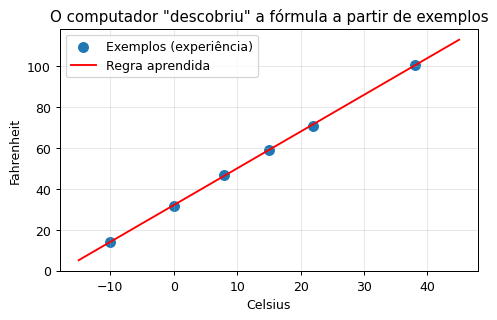

In [70]:
# ---------- Programação tradicional: NÓS escrevemos a regra ----------
def celsius_para_fahrenheit(c):
    return 1.8 * c + 32

print('Regra escrita pelo programador:  25 °C =', celsius_para_fahrenheit(25), '°F')

# ---------- Machine Learning: o computador DESCOBRE a regra ----------
# Temos apenas exemplos (experiência E), medidos com um termômetro "ruidoso"
rng = np.random.default_rng(0)
celsius    = np.array([-10, 0, 8, 15, 22, 38])
fahrenheit = 1.8 * celsius + 32 + rng.normal(0, 1.0, size=celsius.size)

# Ajuste por mínimos quadrados (o "aprendizado")
w, b = np.polyfit(celsius, fahrenheit, deg=1)
print(f'Regra APRENDIDA a partir dos dados: F = {w:.3f}·C + {b:.3f}')
print(f'Previsão do modelo para 25 °C: {w*25 + b:.2f} °F')

plt.figure(figsize=(6, 3.5))
plt.scatter(celsius, fahrenheit, s=60, label='Exemplos (experiência)')
xs = np.linspace(-15, 45, 100)
plt.plot(xs, w*xs + b, 'r-', label='Regra aprendida')
plt.xlabel('Celsius'); plt.ylabel('Fahrenheit'); plt.legend()
plt.title('O computador "descobriu" a fórmula a partir de exemplos')
plt.show()

#### 🔎 Como interpretar o resultado

- **O que aconteceu:** a função `celsius_para_fahrenheit` aplica uma regra que **nós** escrevemos. Já `np.polyfit` recebeu só **6 exemplos** (pares C → F, com um pouco de ruído de medição) e **descobriu sozinho** uma regra muito próxima: `F ≈ 1,800·C + 32,09`.
- **Por que funciona?** O `polyfit` procura a reta que **minimiza a soma dos erros ao quadrado** entre a reta e os pontos (método dos **mínimos quadrados**). Como os dados realmente seguem uma reta, a melhor reta encontrada é quase a fórmula verdadeira.
- **Como ler o gráfico:** os pontos azuis são a **experiência** (exemplos observados) e a linha vermelha é a **regra aprendida** (o modelo). A previsão para 25 °C (77,1 °F) erra só 0,1 °F, por causa do ruído nos dados.
- **💡 Conceito-chave:** em ML não programamos a resposta. Programamos um **procedimento de aprendizado** que extrai a regra dos dados. O erro de 0,09 no intercepto mostra que **o modelo é tão bom quanto os dados**: mais exemplos ou menos ruído levariam a uma estimativa ainda melhor.

### 1.2 A definição formal de Tom Mitchell: **T, P, E**

**Arthur Samuel (1959)** descreveu informalmente ML como o campo que dá aos computadores a habilidade de aprender sem serem explicitamente programados.

**Tom M. Mitchell (1997)**, professor da *Carnegie Mellon University*, propôs a definição **operacional** mais usada até hoje:

> Um programa **aprende** com a experiência **E**, em relação a uma classe de tarefas **T** e medida de desempenho **P**, se seu desempenho em **T**, medido por **P**, **melhora** com **E**.

A grande contribuição dessa definição é transformar "aprender" — uma noção vaga — em algo **mensurável**. Para dizer que um sistema aprende, precisamos especificar três coisas:

| Elemento | Pergunta | Exemplo: jogo de damas (exemplo clássico de Mitchell) |
|:---:|---|---|
| **T** — *Task* (Tarefa) | O que o sistema deve fazer? | Jogar damas |
| **P** — *Performance* (Desempenho) | Como medimos se ele faz bem? | % de partidas vencidas contra oponentes |
| **E** — *Experience* (Experiência) | De onde vem o aprendizado? | Partidas jogadas contra si mesmo |

#### Outros exemplos

| Problema | T (Tarefa) | P (Desempenho) | E (Experiência) |
|---|---|---|---|
| Filtro de spam | Classificar e-mails como spam/não-spam | % de e-mails classificados corretamente | E-mails rotulados pelos usuários |
| Reconhecimento de escrita | Reconhecer palavras manuscritas em imagens | % de palavras reconhecidas corretamente | Base de imagens de palavras com transcrição |
| Carro autônomo | Dirigir em rodovias usando câmeras | Distância média percorrida sem erro | Sequências de imagens e comandos de um motorista humano |
| Recomendação (streaming) | Sugerir filmes ao usuário | Taxa de cliques / tempo assistido | Histórico de visualizações |
| Diagnóstico médico | Indicar se um tumor é maligno | Revocação (não deixar passar casos positivos) | Exames com diagnóstico confirmado |

> 📌 **Atenção:** sem **P** não há como saber se houve aprendizado. Sem **E**, não há do que aprender.

In [4]:
# Modelando a definição de Mitchell como uma estrutura de dados
from dataclasses import dataclass

@dataclass
class ProblemaDeAprendizado:
    nome: str
    tarefa_T: str
    desempenho_P: str
    experiencia_E: str

    def descrever(self):
        print(f'📘 {self.nome}')
        print(f'   T (tarefa)      : {self.tarefa_T}')
        print(f'   P (desempenho)  : {self.desempenho_P}')
        print(f'   E (experiência) : {self.experiencia_E}\n')

problemas = [
    ProblemaDeAprendizado('Damas (Samuel / Mitchell)', 'Jogar damas',
                          '% de partidas vencidas', 'Partidas jogadas contra si mesmo'),
    ProblemaDeAprendizado('Filtro de spam', 'Classificar e-mails',
                          'Acurácia na classificação', 'E-mails marcados pelos usuários'),
    ProblemaDeAprendizado('Previsão de preço de imóveis', 'Estimar o preço de venda',
                          'Erro médio em R$', 'Histórico de vendas com características'),
]
for p in problemas:
    p.descrever()

📘 Damas (Samuel / Mitchell)
   T (tarefa)      : Jogar damas
   P (desempenho)  : % de partidas vencidas
   E (experiência) : Partidas jogadas contra si mesmo

📘 Filtro de spam
   T (tarefa)      : Classificar e-mails
   P (desempenho)  : Acurácia na classificação
   E (experiência) : E-mails marcados pelos usuários

📘 Previsão de preço de imóveis
   T (tarefa)      : Estimar o preço de venda
   P (desempenho)  : Erro médio em R$
   E (experiência) : Histórico de vendas com características



#### 🔎 Como interpretar o resultado

- **O que aconteceu:** representamos cada problema de aprendizado como um objeto com os três campos da definição de Mitchell (**T, P, E**).
- **Por que isso importa?** Antes de escolher qualquer algoritmo, um projeto de ML precisa responder a essas três perguntas. Repare como **P** muda conforme o problema: no jogo de damas é "% de vitórias"; no preço de imóveis é "erro médio em R$". **Não existe uma métrica universal**: ela depende da tarefa.
- **💡 Exercício rápido:** crie um quarto objeto `ProblemaDeAprendizado` para um problema do seu dia a dia (ex.: prever o tempo de entrega de um aplicativo de comida).

#### 🎬 Animação: "o desempenho **P** melhora com a experiência **E**"

Vamos ver a definição de Mitchell **acontecendo**. A tarefa **T** é reconhecer dígitos manuscritos (0–9); o desempenho **P** é a acurácia em um conjunto de teste; a experiência **E** é o número de exemplos rotulados que o modelo já viu.

A cada quadro da animação o modelo recebe **mais experiência** e é avaliado novamente.

In [71]:
# 🎬 ANIMAÇÃO — Desempenho (P) em função da Experiência (E)
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

digitos = load_digits()
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(digitos.data / 16.0, digitos.target,
                                              test_size=0.3, random_state=0, stratify=digitos.target)

tamanhos_E = [10, 20, 30, 50, 75, 100, 150, 200, 300, 400, 600, 800, 1000, len(Xd_tr)]
acuracias_P = []
for n in tamanhos_E:
    m = LogisticRegression(max_iter=2000).fit(Xd_tr[:n], yd_tr[:n])
    acuracias_P.append(m.score(Xd_te, yd_te))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
linha, = ax1.plot([], [], 'o-', color=CORES[0], lw=2)
ax1.set_xlim(0, len(Xd_tr) + 50); ax1.set_ylim(0, 1.02)
ax1.set_xlabel('Experiência E  (nº de exemplos de treino)')
ax1.set_ylabel('Desempenho P  (acurácia no teste)')
ax1.set_title('T = reconhecer dígitos manuscritos')
texto = ax1.text(0.35, 0.1, '', transform=ax1.transAxes, fontsize=12,
                 bbox=dict(facecolor='white', alpha=0.8))

def quadro(i):
    linha.set_data(tamanhos_E[:i+1], acuracias_P[:i+1])
    texto.set_text(f'E = {tamanhos_E[i]} exemplos\nP = {acuracias_P[i]:.1%}')
    ax2.clear()
    ax2.imshow(digitos.images[i], cmap='gray_r'); ax2.axis('off')
    ax2.set_title(f'Exemplo de entrada (rótulo = {digitos.target[i]})')
    return linha, texto

anim = animation.FuncAnimation(fig, quadro, frames=len(tamanhos_E), interval=600)
mostrar_animacao(anim)

#### 🔎 Como interpretar a animação

- **O que você vê:** à esquerda, a curva da acurácia no teste (**P**) à medida que o modelo recebe mais exemplos de treino (**E**). À direita, exemplos das imagens 8×8 de dígitos usadas como entrada.
- **O que acontece:** com **10 exemplos** o modelo acerta cerca de **48%** dos dígitos (o acaso seria 10%, pois são 10 classes). Com **100 exemplos** sobe para ~**91%**, e com ~1.250 chega a ~**97%**.
- **Por que acontece?**
  1. Com poucos exemplos, o modelo viu poucas variações de cada dígito (um "7" com traço, um "7" sem traço...). Ele **não consegue generalizar** para formas que nunca viu.
  2. Cada novo exemplo traz informação sobre a variabilidade real dos dados, e o modelo ajusta melhor seus parâmetros.
  3. A curva **sobe rápido no início e depois achata** (*retornos decrescentes*). Os primeiros exemplos ensinam o "grosso" do padrão; os seguintes só refinam detalhes.
- **Como interpretar:** esta é a definição de Mitchell **literalmente desenhada**: o desempenho **P** na tarefa **T** melhorou com a experiência **E**. Portanto, **o programa aprendeu**.
- **💡 Conceito-chave:** curvas assim se chamam **curvas de aprendizado**. Se a curva ainda está subindo no final, **coletar mais dados** provavelmente ajuda. Se já achatou, é melhor investir em um modelo ou em atributos melhores.

### 1.3 Breve história do Machine Learning

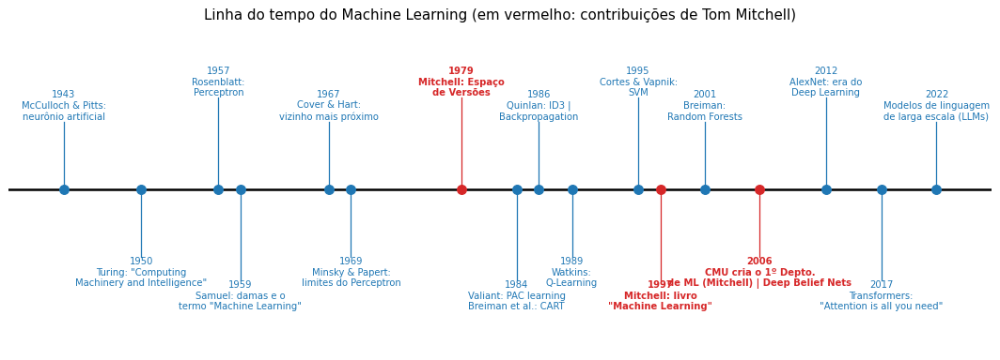

In [6]:
# Linha do tempo dos marcos de Machine Learning
marcos = [
    (1943, 'McCulloch & Pitts:\nneurônio artificial'),
    (1950, 'Turing: "Computing\nMachinery and Intelligence"'),
    (1957, 'Rosenblatt:\nPerceptron'),
    (1959, 'Samuel: damas e o\ntermo "Machine Learning"'),
    (1967, 'Cover & Hart:\nvizinho mais próximo'),
    (1969, 'Minsky & Papert:\nlimites do Perceptron'),
    (1979, 'Mitchell: Espaço\nde Versões'),
    (1984, 'Valiant: PAC learning\nBreiman et al.: CART'),
    (1986, 'Quinlan: ID3 |\nBackpropagation'),
    (1989, 'Watkins:\nQ-Learning'),
    (1995, 'Cortes & Vapnik:\nSVM'),
    (1997, 'Mitchell: livro\n"Machine Learning"'),
    (2001, 'Breiman:\nRandom Forests'),
    (2006, 'CMU cria o 1º Depto.\nde ML (Mitchell) | Deep Belief Nets'),
    (2012, 'AlexNet: era do\nDeep Learning'),
    (2017, 'Transformers:\n"Attention is all you need"'),
    (2022, 'Modelos de linguagem\nde larga escala (LLMs)'),
]
fig, ax = plt.subplots(figsize=(15, 5))
ax.axhline(0, color='k', lw=2)
for i, (ano, evento) in enumerate(marcos):
    alt = 1.0 if i % 2 == 0 else -1.0
    alt *= 1 + 0.35 * ((i // 2) % 2)
    destaque = 'Mitchell' in evento
    cor = CORES[1] if destaque else CORES[0]
    ax.plot([ano, ano], [0, alt], color=cor, lw=1)
    ax.scatter(ano, 0, s=60, color=cor, zorder=3)
    ax.text(ano, alt, f'{ano}\n{evento}', ha='center', va='bottom' if alt > 0 else 'top',
            fontsize=8, color=cor, fontweight='bold' if destaque else 'normal')
ax.set_ylim(-2.4, 2.4); ax.set_xlim(1938, 2027); ax.axis('off')
ax.set_title('Linha do tempo do Machine Learning (em vermelho: contribuições de Tom Mitchell)', fontsize=12)
plt.show()

#### 🔎 Como interpretar o gráfico

- Cada marcador é um marco histórico; em **vermelho** estão as contribuições de **Tom Mitchell**.
- **Repare nos ciclos:** o Perceptron (1957) gerou grande otimismo; o livro de Minsky e Papert (1969) mostrou suas limitações e contribuiu para o chamado **"inverno da IA"**. Nos anos 1980 vieram árvores de decisão, *backpropagation* e teoria do aprendizado (PAC). Nos anos 1990 vieram as SVMs e o livro de Mitchell. A partir de 2012, com **mais dados e GPUs**, o *deep learning* explodiu.
- **💡 Conceito-chave:** os algoritmos que estudaremos (KNN, árvores, Naive Bayes, regressão) **não são ultrapassados**. Eles continuam sendo a base teórica e prática da área, e muitas vezes são a melhor escolha para dados tabulares.

### 1.4 Vocabulário essencial

Usaremos um exemplo simples — classificar **frutas** — para fixar os termos:

| Termo | Sinônimos | Significado | No exemplo |
|---|---|---|---|
| **Instância** | exemplo, amostra, observação | Um objeto do mundo descrito por dados | Uma fruta |
| **Atributo** | *feature*, característica, variável | Uma propriedade mensurável | Peso, cor, textura |
| **Rótulo** | *label*, classe, alvo (*target*) | A resposta que queremos prever | "maçã" ou "laranja" |
| **Conjunto de dados** | *dataset* | Coleção de instâncias | A tabela abaixo |
| **Função-alvo** $c$ | conceito | A função "verdadeira" (desconhecida) que mapeia atributos em rótulos | Natureza das frutas |
| **Hipótese** $h$ | modelo | Nossa aproximação aprendida da função-alvo | "Se peso > 150g, então laranja" |
| **Espaço de hipóteses** $H$ | — | Conjunto de todas as hipóteses que o algoritmo consegue representar | Todas as regras do tipo "peso > limiar" |

> 🔑 **Ideia central (Mitchell, cap. 1–2):** aprender é **buscar** em $H$ a hipótese $h$ que melhor aproxima a função-alvo $c$ a partir dos exemplos.

In [7]:
frutas = pd.DataFrame({
    'peso_g':     [120, 130, 150, 170, 180, 115, 160, 175, 140, 190],
    'textura':    ['lisa', 'lisa', 'rugosa', 'rugosa', 'rugosa', 'lisa', 'rugosa', 'rugosa', 'lisa', 'rugosa'],
    'cor':        ['vermelha', 'vermelha', 'laranja', 'laranja', 'laranja', 'verde', 'laranja', 'laranja', 'vermelha', 'laranja'],
    'fruta':      ['maçã', 'maçã', 'laranja', 'laranja', 'laranja', 'maçã', 'laranja', 'laranja', 'maçã', 'laranja'],
})
print('Cada LINHA é uma instância; cada COLUNA (exceto a última) é um atributo; a última é o rótulo.\n')
display(frutas)

# Uma hipótese muito simples: busca o melhor limiar de peso (espaço de hipóteses H = {peso > t})
melhor_t, melhor_acc = None, 0
for t in range(100, 200, 5):
    previsao = np.where(frutas['peso_g'] > t, 'laranja', 'maçã')
    acc = (previsao == frutas['fruta']).mean()
    if acc > melhor_acc:
        melhor_t, melhor_acc = t, acc
print(f'\nHipótese aprendida: "Se peso > {melhor_t} g então laranja, senão maçã"  (acurácia = {melhor_acc:.0%})')

Cada LINHA é uma instância; cada COLUNA (exceto a última) é um atributo; a última é o rótulo.



,peso_g,textura,cor,fruta
0,120,lisa,vermelha,maçã
1,130,lisa,vermelha,maçã
2,150,rugosa,laranja,laranja
3,170,rugosa,laranja,laranja
4,180,rugosa,laranja,laranja
5,115,lisa,verde,maçã
6,160,rugosa,laranja,laranja
7,175,rugosa,laranja,laranja
8,140,lisa,vermelha,maçã
9,190,rugosa,laranja,laranja



Hipótese aprendida: "Se peso > 140 g então laranja, senão maçã"  (acurácia = 100%)


#### 🔎 Como interpretar o resultado

- **Tabela:** cada **linha** é uma **instância** (uma fruta); `peso_g`, `textura` e `cor` são **atributos**; `fruta` é o **rótulo**.
- **O que o código fez:** definiu um **espaço de hipóteses** pequeno, `H = {"se peso > t então laranja"}`, com `t` variando de 100 a 195 g, e **testou cada hipótese** contra os dados, guardando a de maior acurácia. Isso é aprendizado como **busca em H**, exatamente a visão de Mitchell.
- **Resultado:** `t = 140 g` separa perfeitamente os exemplos (100% de acurácia). Repare que **qualquer** `t` entre 140 e 149 também acertaria tudo. O algoritmo escolheu o primeiro que encontrou. Mais de uma hipótese consistente com os dados é algo que veremos de novo no **Espaço de Versões** (Parte 2).
- **⚠️ Cuidado:** 100% de acerto **nos dados de treino** não garante acerto em frutas novas. Uma maçã grande de 155 g seria classificada como laranja! Avaliar em dados **não vistos** é o tema da Parte 3.

### 1.5 Paradigmas de aprendizado

| Paradigma | Experiência **E** | Objetivo | Exemplos de algoritmos | Aplicações |
|---|---|---|---|---|
| **Supervisionado** | Pares (entrada, **rótulo**) | Prever o rótulo de novas entradas | Regressão linear/logística, KNN, árvores, SVM, redes neurais | Spam, diagnóstico, preço de imóveis |
| **Não supervisionado** | Apenas entradas, **sem rótulo** | Descobrir estrutura/padrões | K-Means, DBSCAN, PCA | Segmentação de clientes, compressão |
| **Semi-supervisionado** | Poucos rótulos + muitos dados sem rótulo | Aproveitar dados não rotulados | *Self-training*, *label propagation* | Classificação de imagens médicas |
| **Por reforço** | Interação: estado → ação → **recompensa** | Aprender uma política que maximize a recompensa | Q-Learning, SARSA, *Policy Gradient* | Jogos, robótica |

Dentro do supervisionado temos duas tarefas principais:
- **Classificação:** o rótulo é uma **categoria** (spam / não-spam; dígito 0–9).
- **Regressão:** o rótulo é um **número contínuo** (preço, temperatura).

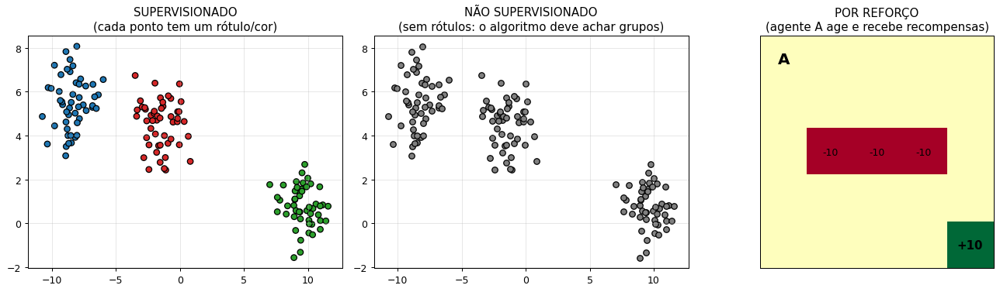

In [73]:
# Visualizando os três paradigmas lado a lado
from sklearn.datasets import make_blobs

Xp, yp = make_blobs(n_samples=150, centers=3, random_state=7, cluster_std=1.1)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3))

axs[0].scatter(Xp[:, 0], Xp[:, 1], c=yp, cmap=CMAP_PONTOS, edgecolor='k')
axs[0].set_title('SUPERVISIONADO\n(cada ponto tem um rótulo/cor)')

axs[1].scatter(Xp[:, 0], Xp[:, 1], c='gray', edgecolor='k')
axs[1].set_title('NÃO SUPERVISIONADO\n(sem rótulos: o algoritmo deve achar grupos)')

# Grid world simples para ilustrar o reforço
grade = np.zeros((5, 5)); grade[4, 4] = 1; grade[2, 1:4] = -1
axs[2].imshow(grade, cmap='RdYlGn', vmin=-1, vmax=1)
axs[2].text(0, 0, 'A', ha='center', va='center', fontsize=16, fontweight='bold')
axs[2].text(4, 4, '+10', ha='center', va='center', fontsize=12, fontweight='bold')
for c in range(1, 4):
    axs[2].text(c, 2, '-10', ha='center', va='center', fontsize=10)
axs[2].set_xticks([]); axs[2].set_yticks([]); axs[2].grid(False)
axs[2].set_title('POR REFORÇO\n(agente A age e recebe recompensas)')
plt.tight_layout(); plt.show()

#### 🔎 Como interpretar a figura

- **Supervisionado (esquerda):** cada ponto já vem com sua cor (rótulo). O algoritmo aprende a **mapear posição → cor** para colorir pontos novos.
- **Não supervisionado (centro):** os **mesmos pontos**, mas sem cores. Olhando, você provavelmente enxerga **3 grupos**. Um algoritmo de *clustering* (como o K-Means, Parte 12) faz exatamente isso: encontra a estrutura **sem que ninguém diga a resposta**.
- **Por reforço (direita):** não há um conjunto de dados fixo. O agente **A** se move pela grade e **recebe recompensas**: +10 no objetivo e −10 nas células vermelhas. Ninguém diz qual movimento é correto; ele aprende pelas **consequências** das ações (Parte 13).
- **💡 Conceito-chave:** o paradigma é definido pelo **tipo de experiência E** disponível: exemplos rotulados, dados sem rótulo ou interação com recompensas.

### 1.6 O fluxo de trabalho de um projeto de ML

```
 ┌────────────┐   ┌──────────────┐   ┌────────────────┐   ┌──────────────┐
 │ 1. Definir │──►│ 2. Coletar e │──►│ 3. Preparar os │──►│ 4. Dividir   │
 │  T, P, E   │   │ explorar dados│   │ dados (limpar, │   │ treino/teste │
 └────────────┘   └──────────────┘   │ normalizar...) │   └──────┬───────┘
                                     └────────────────┘          │
 ┌────────────┐   ┌──────────────┐   ┌────────────────┐   ┌──────▼───────┐
 │ 8. Colocar │◄──│ 7. Avaliar no│◄──│ 6. Ajustar     │◄──│ 5. Treinar   │
 │ em produção│   │ conj. de teste│   │ hiperparâmetros│   │ o modelo     │
 └────────────┘   └──────────────┘   └────────────────┘   └──────────────┘
```

Mitchell (cap. 1) descreve o **projeto de um sistema de aprendizado** em quatro escolhas que continuam válidas hoje:

1. **Escolher a experiência de treinamento** (quais dados? rotulados? representativos?);
2. **Escolher a função-alvo** (o que exatamente aprender?);
3. **Escolher a representação** da função-alvo (linear? árvore? rede neural?);
4. **Escolher o algoritmo** de aproximação (como ajustar os parâmetros?).

No exemplo das damas, Mitchell representa a função de avaliação do tabuleiro como uma **combinação linear** de atributos:

$$\hat{V}(b) = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_6 x_6$$

em que $x_1$ = nº de peças pretas, $x_2$ = nº de peças vermelhas, $x_3$ = nº de damas pretas etc., e ajusta os pesos com a **regra LMS** (*Least Mean Squares*):

$$w_i \leftarrow w_i + \eta \,\big(V_{treino}(b) - \hat{V}(b)\big)\, x_i$$

Essa mesma ideia — **ajustar pesos na direção que reduz o erro** — é o **gradiente descendente** que veremos em detalhe na Parte 4.

---
## Parte 2 — Aprendizado de conceitos como busca (Mitchell, Cap. 2)

Um **conceito** é uma função booleana: dada uma instância, ela pertence ou não ao conceito?
Mitchell usa o exemplo **"Dias em que Aldo gosta de praticar esportes aquáticos"** (*EnjoySport*):

| Ex. | Céu | Temp. do ar | Umidade | Vento | Água | Previsão | **Pratica esporte?** |
|:--:|---|---|---|---|---|---|:--:|
| 1 | Ensolarado | Quente | Normal | Forte | Quente | Igual | ✅ Sim |
| 2 | Ensolarado | Quente | Alta | Forte | Quente | Igual | ✅ Sim |
| 3 | Chuvoso | Frio | Alta | Forte | Quente | Muda | ❌ Não |
| 4 | Ensolarado | Quente | Alta | Forte | Fria | Muda | ✅ Sim |

### 2.1 Representação de hipóteses

Cada hipótese é uma conjunção de restrições sobre os 6 atributos. Cada restrição pode ser:
- um **valor específico** (ex.: `Ensolarado`);
- `?` → **qualquer valor** é aceito;
- `∅` → **nenhum valor** é aceito.

Exemplos:
- `⟨?, ?, ?, ?, ?, ?⟩` → hipótese **mais geral** (todo dia é bom);
- `⟨∅, ∅, ∅, ∅, ∅, ∅⟩` → hipótese **mais específica** (nenhum dia é bom);
- `⟨Ensolarado, ?, ?, Forte, ?, ?⟩` → bom se ensolarado **e** com vento forte.

### 2.2 Ordenação geral-para-específico

Dizemos que $h_j$ é **mais geral ou igual** a $h_k$ ($h_j \geq_g h_k$) se toda instância classificada como positiva por $h_k$ também é positiva por $h_j$. Essa ordem parcial **estrutura o espaço de hipóteses** e permite buscá-lo de forma eficiente.

### 2.3 Algoritmo **Find-S** (encontrar a hipótese maximamente específica)

```
1. h ← hipótese mais específica ⟨∅, ∅, ∅, ∅, ∅, ∅⟩
2. Para cada exemplo POSITIVO x:
       Para cada atributo a_i:
           se a restrição de h em a_i não é satisfeita por x:
               generalize-a minimamente (∅ → valor de x; valor diferente → ?)
3. Retorne h      (exemplos negativos são IGNORADOS)
```

In [9]:
# ========== DADOS ENJOYSPORT (Mitchell, Tabela 2.1) ==========
ATRIBUTOS = ['Céu', 'TempAr', 'Umidade', 'Vento', 'Água', 'Previsão']
DOMINIOS = {
    'Céu':      ['Ensolarado', 'Nublado', 'Chuvoso'],
    'TempAr':   ['Quente', 'Frio'],
    'Umidade':  ['Normal', 'Alta'],
    'Vento':    ['Forte', 'Fraco'],
    'Água':     ['Quente', 'Fria'],
    'Previsão': ['Igual', 'Muda'],
}
EXEMPLOS = [
    (('Ensolarado', 'Quente', 'Normal', 'Forte', 'Quente', 'Igual'), True),
    (('Ensolarado', 'Quente', 'Alta',   'Forte', 'Quente', 'Igual'), True),
    (('Chuvoso',    'Frio',   'Alta',   'Forte', 'Quente', 'Muda'),  False),
    (('Ensolarado', 'Quente', 'Alta',   'Forte', 'Fria',   'Muda'),  True),
]
display(pd.DataFrame([list(x) + ['Sim' if y else 'Não'] for x, y in EXEMPLOS],
                     columns=ATRIBUTOS + ['Esporte?'], index=range(1, 5)))


def find_s(exemplos, verbose=True):
    h = ['∅'] * len(ATRIBUTOS)
    historico = [list(h)]
    if verbose:
        print(f'h0 = ⟨{", ".join(h)}⟩')
    for i, (x, positivo) in enumerate(exemplos, 1):
        if positivo:
            for j, valor in enumerate(x):
                if h[j] == '∅':
                    h[j] = valor
                elif h[j] != valor:
                    h[j] = '?'
            acao = 'POSITIVO → generaliza'
        else:
            acao = 'NEGATIVO → ignorado'
        historico.append(list(h))
        if verbose:
            print(f'h{i} = ⟨{", ".join(h)}⟩    ({acao})')
    return h, historico


print('\n===== Execução do Find-S =====')
h_final, hist_finds = find_s(EXEMPLOS)

,Céu,TempAr,Umidade,Vento,Água,Previsão,Esporte?
1,Ensolarado,Quente,Normal,Forte,Quente,Igual,Sim
2,Ensolarado,Quente,Alta,Forte,Quente,Igual,Sim
3,Chuvoso,Frio,Alta,Forte,Quente,Muda,Não
4,Ensolarado,Quente,Alta,Forte,Fria,Muda,Sim



===== Execução do Find-S =====
h0 = ⟨∅, ∅, ∅, ∅, ∅, ∅⟩
h1 = ⟨Ensolarado, Quente, Normal, Forte, Quente, Igual⟩    (POSITIVO → generaliza)
h2 = ⟨Ensolarado, Quente, ?, Forte, Quente, Igual⟩    (POSITIVO → generaliza)
h3 = ⟨Ensolarado, Quente, ?, Forte, Quente, Igual⟩    (NEGATIVO → ignorado)
h4 = ⟨Ensolarado, Quente, ?, Forte, ?, ?⟩    (POSITIVO → generaliza)


#### 🔎 Como interpretar o Find-S passo a passo

| Passo | O que aconteceu | Por quê |
|---|---|---|
| **h0** | Começa com `⟨∅,∅,∅,∅,∅,∅⟩` | A hipótese mais específica possível: não aceita **nenhum** dia |
| **h1** | Vira uma cópia exata do exemplo 1 | O 1º positivo precisa ser aceito; a generalização **mínima** de ∅ é o próprio valor |
| **h2** | `Umidade` vira `?` | O exemplo 2 tem Umidade=Alta, diferente de Normal. Para aceitar ambos, a única saída é aceitar **qualquer** umidade |
| **h3** | Nada muda | O Find-S **ignora exemplos negativos**. Repare que h2 já rejeita o exemplo 3 (Chuvoso ≠ Ensolarado) |
| **h4** | `Água` e `Previsão` viram `?` | O exemplo 4 tem Água=Fria e Previsão=Muda |

- **Resultado final:** `⟨Ensolarado, Quente, ?, Forte, ?, ?⟩`, ou seja, *"Aldo pratica esportes quando está ensolarado, quente e com vento forte"*. É o mesmo resultado do livro de Mitchell.
- **Por que é seguro ignorar negativos?** Se o conceito verdadeiro está em H e os dados não têm ruído, a hipótese mais específica consistente com os positivos **nunca** cobrirá um negativo.
- **💡 Conceito-chave:** aprender = **generalizar** a partir de exemplos, mas apenas o **mínimo necessário**.

#### 🎛️ Find-S passo a passo

Mova o *slider* para ver a hipótese sendo **generalizada** a cada exemplo positivo. Células em verde são valores específicos, amarelas são `?` e cinzas são `∅`.

In [10]:
# 🎛️ INTERATIVO — evolução da hipótese no Find-S
def mostrar_find_s(passo=0):
    h = hist_finds[passo]
    fig, ax = plt.subplots(figsize=(11, 2.2))
    for j, v in enumerate(h):
        cor = '#dddddd' if v == '∅' else ('#ffe28a' if v == '?' else '#a6e3a1')
        ax.add_patch(plt.Rectangle((j, 0), 0.95, 1, color=cor))
        ax.text(j + 0.475, 0.62, ATRIBUTOS[j], ha='center', fontsize=9, color='#555')
        ax.text(j + 0.475, 0.3, v, ha='center', fontsize=12, fontweight='bold')
    ax.set_xlim(0, 6); ax.set_ylim(0, 1); ax.axis('off')
    if passo == 0:
        titulo = 'h0: hipótese mais específica possível'
    else:
        x, y = EXEMPLOS[passo - 1]
        titulo = f'Após o exemplo {passo} ({"POSITIVO" if y else "NEGATIVO - ignorado"}): {", ".join(x)}'
    ax.set_title(titulo, fontsize=10)
    plt.show()

interact(mostrar_find_s, passo=widgets.IntSlider(min=0, max=len(EXEMPLOS), step=1, value=0,
                                                 description='Exemplo'));

interactive(children=(IntSlider(value=0, description='Exemplo', max=4), Output()), _dom_classes=('widget-inter…

#### 🔎 Como usar e interpretar

- Mova o *slider* de 0 a 4. **Cinza** = `∅` (nada aceito), **verde** = valor específico, **amarelo** = `?` (qualquer valor).
- Observe que as células **só mudam de cinza → verde → amarelo, nunca no sentido contrário**. O Find-S só **generaliza**, nunca especializa. Por isso ele "caminha" no espaço de hipóteses **do mais específico para o mais geral**.
- No passo 3 (exemplo negativo), **nada muda**: o Find-S descarta essa informação. Esse desperdício motiva o algoritmo seguinte (Eliminação de Candidatos), que **usa os negativos também**.

**Limitações do Find-S** (discutidas por Mitchell):
- Não sabe se convergiu para o **único** conceito correto ou se há outras hipóteses consistentes;
- Prefere sempre a hipótese **mais específica** (por quê?);
- Não detecta dados **inconsistentes** (ruído), pois ignora os negativos.

### 2.4 Espaço de Versões e **Eliminação de Candidatos**

O **Espaço de Versões** $VS_{H,D}$ é o subconjunto de hipóteses de $H$ **consistentes** com todos os exemplos de treino $D$.

Mitchell (1977, 1982) mostrou que ele pode ser representado de forma compacta por duas fronteiras:
- **S** (*specific boundary*): as hipóteses consistentes **mais específicas**;
- **G** (*general boundary*): as hipóteses consistentes **mais gerais**.

Toda hipótese consistente está "entre" S e G. O algoritmo de **Eliminação de Candidatos** atualiza S e G a cada exemplo:
- exemplo **positivo** → **generaliza S** (e remove de G o que não o cobre);
- exemplo **negativo** → **especializa G** (e remove de S o que o cobre).

Como o domínio é pequeno (3·2·2·2·2·2 = 96 instâncias e 973 hipóteses semanticamente distintas), podemos **enumerar** o espaço inteiro por força bruta e **ver** o espaço de versões encolhendo.

In [11]:
from itertools import product

def cobre(h, x):
    # h classifica x como positivo?
    return all(hc == '?' or hc == xv for hc, xv in zip(h, x))

def mais_geral_ou_igual(h1, h2):
    # h1 >=g h2 (para hipóteses sem ∅)
    return all(a == '?' or a == b for a, b in zip(h1, h2))

# Enumera todas as hipóteses não vazias: cada atributo pode ser um valor ou '?'
H = list(product(*[DOMINIOS[a] + ['?'] for a in ATRIBUTOS]))
print(f'|H| = {len(H)} hipóteses não vazias  (+ 1 hipótese vazia ⟨∅,...⟩ = {len(H)+1})')

def espaco_de_versoes(exemplos):
    return [h for h in H if all(cobre(h, x) == y for x, y in exemplos)]

def fronteiras(VS):
    S = [h for h in VS if not any(h2 != h and mais_geral_ou_igual(h, h2) for h2 in VS)]
    G = [h for h in VS if not any(h2 != h and mais_geral_ou_igual(h2, h) for h2 in VS)]
    return S, G

tamanhos_vs = [len(H)]
for k in range(1, len(EXEMPLOS) + 1):
    VS = espaco_de_versoes(EXEMPLOS[:k])
    tamanhos_vs.append(len(VS))
    S, G = fronteiras(VS)
    print(f'\nApós {k} exemplo(s): |VS| = {len(VS)}')
    print('   S =', ['⟨' + ', '.join(s) + '⟩' for s in S])
    print('   G =', ['⟨' + ', '.join(g) + '⟩' for g in G])

print('\n📌 Espaço de versões final (todas as hipóteses consistentes):')
for h in VS:
    print('   ⟨' + ', '.join(h) + '⟩')

|H| = 972 hipóteses não vazias  (+ 1 hipótese vazia ⟨∅,...⟩ = 973)

Após 1 exemplo(s): |VS| = 64
   S = ['⟨Ensolarado, Quente, Normal, Forte, Quente, Igual⟩']
   G = ['⟨?, ?, ?, ?, ?, ?⟩']

Após 2 exemplo(s): |VS| = 32
   S = ['⟨Ensolarado, Quente, ?, Forte, Quente, Igual⟩']
   G = ['⟨?, ?, ?, ?, ?, ?⟩']

Após 3 exemplo(s): |VS| = 28
   S = ['⟨Ensolarado, Quente, ?, Forte, Quente, Igual⟩']
   G = ['⟨Ensolarado, ?, ?, ?, ?, ?⟩', '⟨?, Quente, ?, ?, ?, ?⟩', '⟨?, ?, ?, ?, ?, Igual⟩']

Após 4 exemplo(s): |VS| = 6
   S = ['⟨Ensolarado, Quente, ?, Forte, ?, ?⟩']
   G = ['⟨Ensolarado, ?, ?, ?, ?, ?⟩', '⟨?, Quente, ?, ?, ?, ?⟩']

📌 Espaço de versões final (todas as hipóteses consistentes):
   ⟨Ensolarado, Quente, ?, Forte, ?, ?⟩
   ⟨Ensolarado, Quente, ?, ?, ?, ?⟩
   ⟨Ensolarado, ?, ?, Forte, ?, ?⟩
   ⟨Ensolarado, ?, ?, ?, ?, ?⟩
   ⟨?, Quente, ?, Forte, ?, ?⟩
   ⟨?, Quente, ?, ?, ?, ?⟩


#### 🔎 Como interpretar o resultado

- **|H| = 972 (+1):** cada atributo pode assumir um de seus valores ou `?`, ou seja 4·3·3·3·3·3 = 972 hipóteses, mais a hipótese vazia. É o tamanho do espaço onde o aprendiz procura.
- **Evolução do espaço de versões (VS):**
  - **Após o exemplo 1 (+):** sobram **64** hipóteses, as que aceitam aquele dia. Cada atributo pode ser "o valor do exemplo" ou `?`: 2⁶ = 64.
  - **Após o exemplo 2 (+):** **32**. Umidade agora precisa ser `?`.
  - **Após o exemplo 3 (−):** **28**. O negativo elimina hipóteses gerais demais (como `⟨?,?,?,?,?,?⟩`), e por isso **G** fica mais específico.
  - **Após o exemplo 4 (+):** **6** hipóteses consistentes.
- **Fronteiras S e G:**
  - **S** = `⟨Ensolarado, Quente, ?, Forte, ?, ?⟩`, a mesma resposta do Find-S (que só calcula S!).
  - **G** = `{⟨Ensolarado,?,…⟩, ⟨?,Quente,…⟩}`, as hipóteses mais gerais que ainda rejeitam o dia chuvoso e frio.
  - As 6 hipóteses finais estão todas **"entre" S e G**. É exatamente o espaço de versões apresentado por Mitchell para este exemplo.
- **💡 Conceito-chave:** o espaço de versões representa **tudo o que ainda é plausível** dado o que vimos. Ele não escolhe uma resposta arbitrária; mantém **todas as consistentes**.

In [12]:
# 🎬 ANIMAÇÃO — o espaço de versões encolhendo a cada exemplo
fig, ax = plt.subplots(figsize=(8, 4))
rotulos = ['Início'] + [f'Ex. {k}\n({"+" if EXEMPLOS[k-1][1] else "−"})' for k in range(1, 5)]

def quadro_vs(i):
    ax.clear()
    cores = [CORES[2] if EXEMPLOS[k-1][1] else CORES[1] for k in range(1, i + 1)]
    barras = ax.bar(rotulos[:i+1], tamanhos_vs[:i+1], color=['gray'] + cores)
    for b, v in zip(barras, tamanhos_vs[:i+1]):
        ax.text(b.get_x() + b.get_width()/2, v * 1.15, str(v), ha='center', fontweight='bold')
    ax.set_yscale('log'); ax.set_ylim(1, 3000); ax.set_xlim(-0.5, 4.5)
    ax.set_ylabel('nº de hipóteses consistentes (log)')
    ax.set_title('Eliminação de Candidatos: cada exemplo elimina hipóteses')

anim = animation.FuncAnimation(fig, quadro_vs, frames=5, interval=1200)
mostrar_animacao(anim)

#### 🔎 Como interpretar a animação

- O eixo vertical está em **escala logarítmica**: cada linha de grade representa ×10.
- **Barras verdes** = exemplos positivos e **barra vermelha** = exemplo negativo. **Todos** os exemplos eliminam hipóteses, inclusive o negativo.
- A queda de 972 → 64 com **um único exemplo** mostra o poder da informação: cada exemplo **divide** o espaço de hipóteses.
- **Por que isso importa?** Se continuássemos recebendo exemplos (sem ruído), o espaço de versões convergiria para **uma única hipótese**, e saberíamos exatamente o conceito. Mitchell mostra também que o aprendiz poderia **escolher** o próximo exemplo a perguntar (*aprendizado ativo*) para cortar o espaço pela metade a cada pergunta.

### 2.5 Viés indutivo — por que precisamos de suposições?

O espaço de hipóteses acima só contém **conjunções**. Ele **não consegue** representar, por exemplo, "Céu = Ensolarado **OU** Céu = Nublado". Isso é um **viés** (*bias*): uma suposição embutida no aprendiz.

E se usássemos um espaço **sem viés**, capaz de representar **qualquer** subconjunto das 96 instâncias ($2^{96} \approx 10^{28}$ hipóteses)? Mitchell mostra que então o aprendiz **não consegue generalizar**: para qualquer instância não vista, metade das hipóteses consistentes diria "sim" e metade diria "não".

> 🔑 **Futilidade do aprendizado sem viés (Mitchell, 1980):** *um aprendiz que não faz nenhuma suposição a priori sobre a identidade do conceito-alvo não tem nenhuma base racional para classificar instâncias não vistas.*

**Viés indutivo** = conjunto de suposições que, junto com os dados de treino, justificam dedutivamente as classificações do aprendiz. Exemplos:

| Algoritmo | Viés indutivo |
|---|---|
| Eliminação de Candidatos | O conceito-alvo está contido em $H$ (conjunções) |
| Find-S | Idem + prefere a hipótese mais específica |
| Regressão linear | A relação entre $x$ e $y$ é aproximadamente linear |
| KNN | Instâncias próximas têm rótulos parecidos |
| ID3 | Árvores **menores** são preferíveis (Navalha de Occam) |

Vejamos na prática: classificar uma instância nova usando o espaço de versões (votação entre as hipóteses consistentes).

In [13]:
def classificar_com_vs(x, VS):
    votos_sim = sum(cobre(h, x) for h in VS)
    return votos_sim, len(VS) - votos_sim

novas = [
    ('Ensolarado', 'Quente', 'Normal', 'Forte', 'Fria',   'Muda'),
    ('Chuvoso',    'Frio',   'Normal', 'Fraco', 'Quente', 'Igual'),
    ('Ensolarado', 'Quente', 'Normal', 'Fraco', 'Quente', 'Igual'),
    ('Ensolarado', 'Frio',   'Normal', 'Forte', 'Quente', 'Igual'),
]
for x in novas:
    s, n = classificar_com_vs(x, VS)
    if n == 0:
        veredito = '✅ SIM (unanimidade)'
    elif s == 0:
        veredito = '❌ NÃO (unanimidade)'
    else:
        veredito = f'🤔 Ambíguo ({s} sim × {n} não) → precisamos de mais exemplos!'
    print(f'{x}\n   → {veredito}\n')

('Ensolarado', 'Quente', 'Normal', 'Forte', 'Fria', 'Muda')
   → ✅ SIM (unanimidade)

('Chuvoso', 'Frio', 'Normal', 'Fraco', 'Quente', 'Igual')
   → ❌ NÃO (unanimidade)

('Ensolarado', 'Quente', 'Normal', 'Fraco', 'Quente', 'Igual')
   → 🤔 Ambíguo (3 sim × 3 não) → precisamos de mais exemplos!

('Ensolarado', 'Frio', 'Normal', 'Forte', 'Quente', 'Igual')
   → 🤔 Ambíguo (2 sim × 4 não) → precisamos de mais exemplos!



#### 🔎 Como interpretar o resultado

Cada nova instância é classificada pelo **voto das 6 hipóteses** do espaço de versões:

| Instância | Votos | Interpretação |
|---|---|---|
| Ensolarado, Quente, Forte... | 6 sim × 0 | **Todas** as hipóteses concordam, então a resposta é **certa** (dado o viés de H) |
| Chuvoso, Frio... | 0 × 6 não | **Todas** discordam, então a resposta é **certa** |
| Ensolarado, Quente, vento **Fraco** | 3 × 3 | **Empate total**: os dados ainda não revelam se o vento importa |
| Ensolarado, **Frio**, Forte | 2 × 4 | Maioria diz "não", mas **não há certeza** |

- **Por que é útil?** O espaço de versões sabe **quando não sabe**. Em vez de dar um palpite confiante, ele indica **quais exemplos precisamos rotular** para eliminar a ambiguidade.
- **💡 Ligação com o viés indutivo:** as duas classificações "unânimes" só são possíveis **porque** restringimos H a conjunções. Sem esse viés, toda instância nova seria um empate exato (discussão da Seção 2.5).

---
## Parte 3 — Dados: a matéria-prima do aprendizado

> *"Lixo entra, lixo sai"* (*garbage in, garbage out*). A qualidade do modelo é limitada pela qualidade dos dados.

### 3.1 Tipos de atributos

| Tipo | Descrição | Exemplos | Tratamento usual |
|---|---|---|---|
| **Numérico contínuo** | Qualquer valor real | altura, preço | Normalização/padronização |
| **Numérico discreto** | Contagens | nº de quartos | Normalização |
| **Categórico nominal** | Categorias sem ordem | cor, cidade | *One-hot encoding* |
| **Categórico ordinal** | Categorias com ordem | P < M < G | Codificação ordinal (0, 1, 2) |
| **Texto** | Linguagem natural | e-mail | *Bag of words*, TF-IDF, *embeddings* |
| **Imagem** | Matriz de pixels | foto | Pixels como atributos, CNNs |

### 3.2 Pré-processamento na prática

In [14]:
# Um conjunto de dados "do mundo real": com valores faltantes e categorias
imoveis = pd.DataFrame({
    'area_m2':   [50, 72, np.nan, 120, 65, 200, 90, 45],
    'quartos':   [1, 2, 2, 3, 2, 4, 3, 1],
    'bairro':    ['Centro', 'Jardins', 'Centro', 'Vila', 'Jardins', 'Vila', 'Centro', np.nan],
    'tamanho':   ['P', 'M', 'M', 'G', 'M', 'G', 'G', 'P'],
    'preco_mil': [250, 480, 330, 620, 450, 980, 500, 210],
})
print('📋 Dados brutos:'); display(imoveis)

print('\n🔎 Valores ausentes por coluna:')
print(imoveis.isna().sum())

dados = imoveis.copy()
# 1) Imputação: numérico → mediana; categórico → moda
dados['area_m2'] = dados['area_m2'].fillna(dados['area_m2'].median())
dados['bairro']  = dados['bairro'].fillna(dados['bairro'].mode()[0])
# 2) Ordinal → números preservando a ordem
dados['tamanho'] = dados['tamanho'].map({'P': 0, 'M': 1, 'G': 2})
# 3) Nominal → one-hot
dados = pd.get_dummies(dados, columns=['bairro'], dtype=int)
print('\n✅ Dados prontos para um algoritmo de ML:'); display(dados)

📋 Dados brutos:


,area_m2,quartos,bairro,tamanho,preco_mil
0,50.0,1,Centro,P,250
1,72.0,2,Jardins,M,480
2,NaN,2,Centro,M,330
3,120.0,3,Vila,G,620
4,65.0,2,Jardins,M,450
5,200.0,4,Vila,G,980
6,90.0,3,Centro,G,500
7,45.0,1,NaN,P,210



🔎 Valores ausentes por coluna:
area_m2      1
quartos      0
bairro       1
tamanho      0
preco_mil    0
dtype: int64

✅ Dados prontos para um algoritmo de ML:


,area_m2,quartos,tamanho,preco_mil,bairro_Centro,bairro_Jardins,bairro_Vila
0,50.0,1,0,250,1,0,0
1,72.0,2,1,480,0,1,0
2,72.0,2,1,330,1,0,0
3,120.0,3,2,620,0,0,1
4,65.0,2,1,450,0,1,0
5,200.0,4,2,980,0,0,1
6,90.0,3,2,500,1,0,0
7,45.0,1,0,210,1,0,0


#### 🔎 Como interpretar o resultado

1. **Dados brutos:** há um `NaN` em `area_m2` (linha 2) e outro em `bairro` (linha 7). A maioria dos algoritmos **não aceita** valores ausentes nem texto.
2. **Imputação:**
   - a área faltante virou **72** (a **mediana** das áreas). Usamos a mediana e não a média porque ela é **robusta a valores extremos**: o imóvel de 200 m² puxaria a média para cima;
   - o bairro faltante virou **Centro** (a **moda**, categoria mais frequente).
3. **Codificação ordinal:** `P, M, G` viraram `0, 1, 2`. Isso faz sentido porque existe **ordem** (P < M < G).
4. ***One-hot encoding*:** `bairro` virou três colunas 0/1 (`bairro_Centro`, `bairro_Jardins`, `bairro_Vila`).
   - **Por que não usar 0, 1, 2 para bairros?** Porque o modelo interpretaria que "Vila (2)" é "o dobro" de "Jardins (1)" e que Jardins fica "entre" Centro e Vila, uma **ordem que não existe**. O *one-hot* evita criar essa relação falsa.
- **💡 Conceito-chave:** o resultado final é uma **matriz puramente numérica**, o formato que os algoritmos de ML esperam. Na prática, a preparação de dados costuma ocupar **a maior parte do tempo** de um projeto de ML.

### 3.3 Normalização e padronização

Muitos algoritmos (KNN, SVM, gradiente descendente, redes neurais) são **sensíveis à escala**. Se a área vai de 40 a 200 e o nº de quartos de 1 a 4, a área domina qualquer cálculo de distância.

- **Normalização Min-Max:** $x' = \dfrac{x - x_{min}}{x_{max} - x_{min}} \in [0, 1]$
- **Padronização (z-score):** $x' = \dfrac{x - \mu}{\sigma}$ → média 0 e desvio-padrão 1

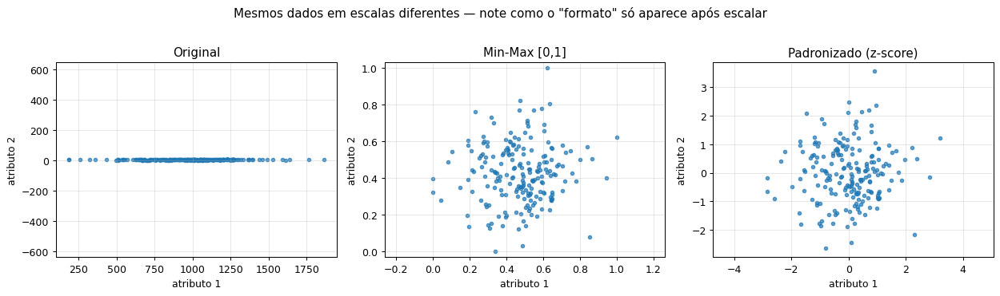

In [15]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

rng = np.random.default_rng(1)
A = np.c_[rng.normal(1000, 300, 200), rng.normal(5, 1.5, 200)]   # duas escalas muito diferentes

fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nome, dados_t) in zip(axs, [('Original', A),
                                     ('Min-Max [0,1]', MinMaxScaler().fit_transform(A)),
                                     ('Padronizado (z-score)', StandardScaler().fit_transform(A))]):
    ax.scatter(dados_t[:, 0], dados_t[:, 1], s=12, alpha=0.7)
    ax.set_title(nome); ax.set_xlabel('atributo 1'); ax.set_ylabel('atributo 2')
    ax.set_aspect('equal', adjustable='datalim')
plt.suptitle('Mesmos dados em escalas diferentes — note como o "formato" só aparece após escalar', y=1.02)
plt.tight_layout(); plt.show()

#### 🔎 Como interpretar o gráfico

- **Original (esquerda):** o atributo 1 varia em torno de 1000 ± 300 e o atributo 2 em torno de 5 ± 1,5. Com eixos na mesma escala (`aspect='equal'`), a nuvem parece uma **linha horizontal achatada**: o atributo 2 fica "invisível".
- **Por que isso é um problema?** Algoritmos baseados em **distância** (KNN, K-Means, SVM) calculariam distâncias dominadas quase só pelo atributo 1. Uma diferença de 1 unidade no atributo 2 (que é grande para ele) pesaria o mesmo que 1 unidade no atributo 1 (que é minúscula para ele).
- **Min-Max (centro):** os dois atributos passam a variar entre 0 e 1. A nuvem agora mostra a forma real dos dados.
- **Padronização (direita):** os dois atributos ficam com **média 0 e desvio-padrão 1**. A forma é a mesma da Min-Max; muda apenas o intervalo.
- **Quando usar cada um?** A Min-Max é sensível a *outliers* (um único valor extremo "esmaga" os demais). A padronização é a escolha padrão para a maioria dos modelos (regressão, SVM, redes neurais).

### 3.4 Divisão treino / validação / teste

A pergunta que importa em ML **não** é "o modelo acerta os dados que já viu?", e sim **"o modelo acerta dados novos?"** (capacidade de **generalização**).

- **Treino** (~60–80%): usado para ajustar os parâmetros;
- **Validação** (~10–20%): usado para escolher hiperparâmetros e comparar modelos;
- **Teste** (~10–20%): usado **uma única vez**, no fim, para estimar o desempenho real.

> ⚠️ **Vazamento de dados (*data leakage*)**: qualquer informação do conjunto de teste usada no treino (inclusive para calcular média/desvio na normalização!) produz uma estimativa **otimista e falsa**. Sempre ajuste (`fit`) o pré-processamento **somente no treino**.

Treino: 12 | Validação: 4 | Teste: 4


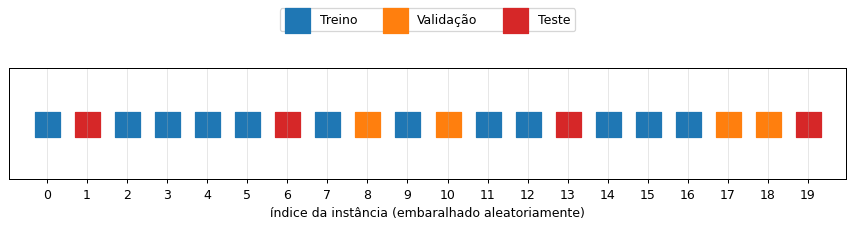

Média usada na normalização (apenas do treino): [8.17]


In [16]:
from sklearn.model_selection import train_test_split

X_todos = np.arange(20).reshape(-1, 1)
y_todos = np.arange(20) % 2

X_tr, X_temp, y_tr, y_temp = train_test_split(X_todos, y_todos, test_size=0.4, random_state=0)
X_val, X_te, y_val, y_te = train_test_split(X_temp, y_temp, test_size=0.5, random_state=0)
print(f'Treino: {len(X_tr)} | Validação: {len(X_val)} | Teste: {len(X_te)}')

fig, ax = plt.subplots(figsize=(12, 1.6))
for conj, cor, nome in [(X_tr, CORES[0], 'Treino'), (X_val, CORES[3], 'Validação'), (X_te, CORES[1], 'Teste')]:
    ax.scatter(conj.ravel(), np.zeros(len(conj)), s=400, color=cor, label=nome, marker='s')
ax.set_yticks([]); ax.set_xticks(range(20)); ax.legend(loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.6))
ax.set_xlabel('índice da instância (embaralhado aleatoriamente)')
plt.show()

# Forma CORRETA de normalizar (fit só no treino!)
scaler = StandardScaler().fit(X_tr)
X_tr_n, X_te_n = scaler.transform(X_tr), scaler.transform(X_te)
print('Média usada na normalização (apenas do treino):', scaler.mean_.round(2))

#### 🔎 Como interpretar o resultado

- **Divisão 12 / 4 / 4:** 60% treino, 20% validação e 20% teste. A figura mostra que as instâncias foram **sorteadas**, não cortadas em sequência. Isso evita que, por exemplo, todos os dados de um mês fiquem só no teste.
- **Média usada na normalização = 8,17:** é a média dos índices **do conjunto de treino**, não dos 20 dados (que seria 9,5).
- **Por que isso é importante?** O conjunto de teste simula o "futuro", dados que o modelo nunca viu. Se calcularmos a média com dados do teste, estamos **espiando o futuro**: isso é **vazamento de dados (*data leakage*)**, e a avaliação fica otimista e enganosa.
- **💡 Regra de ouro:** `fit` (aprender parâmetros, inclusive de pré-processamento) **só no treino**; `transform` em treino, validação e teste.

---
## Parte 4 — Regressão linear e gradiente descendente

### 4.1 O problema

Queremos prever um valor **contínuo** $y$ (ex.: preço de um imóvel) a partir de um atributo $x$ (ex.: área). A **hipótese** é uma reta:

$$h_\theta(x) = \theta_0 + \theta_1 x$$

- $\theta_0$: intercepto (*bias*) — onde a reta corta o eixo $y$;
- $\theta_1$: inclinação (peso) — quanto $y$ muda quando $x$ aumenta 1 unidade.

Com $n$ atributos: $h_\theta(\mathbf{x}) = \theta_0 + \theta_1 x_1 + \dots + \theta_n x_n = \boldsymbol{\theta}^T \mathbf{x}$.

### 4.2 Medindo o erro: função de custo (MSE)

Como saber se uma reta é boa? Medimos o **erro quadrático médio** entre previsões e valores reais:

$$J(\theta_0, \theta_1) = \frac{1}{2m} \sum_{i=1}^{m} \big(h_\theta(x^{(i)}) - y^{(i)}\big)^2$$

**Aprender = encontrar os $\theta$ que minimizam $J$.**

#### 🎛️ Tente você mesmo: ajuste a reta "na mão"

Mova os *sliders* e tente deixar o erro (MSE) o menor possível. Os segmentos vermelhos são os **resíduos** (erros) de cada ponto.

In [74]:
# Dados: área (m²) × preço (R$ mil) — gerados a partir de uma reta "verdadeira" + ruído
rng = np.random.default_rng(42)
area  = rng.uniform(30, 150, 40)
preco = 50 + 3.0 * area + rng.normal(0, 40, area.size)

def ajuste_manual(theta0=0.0, theta1=1.0):
    pred = theta0 + theta1 * area
    mse = np.mean((pred - preco) ** 2)
    plt.figure(figsize=(8, 4.5))
    plt.scatter(area, preco, color=CORES[0], zorder=3, label='Dados')
    for xi, yi, pi in zip(area, preco, pred):
        plt.plot([xi, xi], [yi, pi], color=CORES[1], alpha=0.4)
    xs = np.linspace(25, 155, 2)
    plt.plot(xs, theta0 + theta1 * xs, 'k-', lw=2, label=f'h(x) = {theta0:.0f} + {theta1:.2f}·x')
    plt.ylim(0, 600); plt.xlabel('Área (m²)'); plt.ylabel('Preço (R$ mil)')
    plt.title(f'MSE = {mse:,.1f}', fontsize=14, color=CORES[2] if mse < 2000 else CORES[1])
    plt.legend(loc='upper left'); plt.show()

interact(ajuste_manual,
         theta0=widgets.FloatSlider(min=-100, max=200, step=5, value=0, description='θ₀'),
         theta1=widgets.FloatSlider(min=0, max=6, step=0.1, value=1, description='θ₁'));

interactive(children=(FloatSlider(value=0.0, description='θ₀', max=200.0, min=-100.0, step=5.0), FloatSlider(v…

#### 🔎 Como usar e interpretar

- **Experimente:** comece com θ₁ ≈ 3 e depois ajuste θ₀. O menor MSE possível para estes dados é ≈ **785** (o título fica verde abaixo de 2.000). Quão perto você consegue chegar?
- **O que são os segmentos vermelhos?** São os **resíduos** `h(x) − y`, a distância vertical entre a previsão e o valor real de cada imóvel. O MSE é a **média dos quadrados** desses segmentos.
- **Por que elevar ao quadrado?**
  1. Resíduos positivos e negativos não se cancelam;
  2. Erros grandes são **muito** penalizados: um erro de 100 pesa 4× mais que um de 50;
  3. A função fica **suave e convexa** (formato de tigela), o que permite usar derivadas para achar o mínimo.
- **💡 Reflexão:** você acabou de fazer, "na mão", o que o algoritmo de aprendizado faz: **ajustar parâmetros para minimizar uma função de custo**. A diferença é que o computador faz isso de forma sistemática, usando o gradiente.

### 4.3 Gradiente descendente

Em vez de tentar valores ao acaso, usamos o **gradiente** (vetor de derivadas parciais), que aponta para a direção de **maior crescimento** de $J$. Caminhando no sentido **oposto**, descemos a "montanha" do erro.

$$\theta_j \leftarrow \theta_j - \alpha \frac{\partial J}{\partial \theta_j}$$

Para a regressão linear:

$$\frac{\partial J}{\partial \theta_0} = \frac{1}{m}\sum_{i=1}^{m}\big(h_\theta(x^{(i)}) - y^{(i)}\big) \qquad
\frac{\partial J}{\partial \theta_1} = \frac{1}{m}\sum_{i=1}^{m}\big(h_\theta(x^{(i)}) - y^{(i)}\big)\,x^{(i)}$$

- $\alpha$ é a **taxa de aprendizado** (*learning rate*): o tamanho do passo;
- Esta é exatamente a **regra LMS** de Mitchell, aplicada a todos os exemplos de uma vez (*batch*).

**Analogia:** você está no alto de uma montanha com neblina e quer chegar ao vale. Sem enxergar longe, você sente a inclinação do chão sob seus pés e dá um passo **ladeira abaixo**. Repete até chegar ao fundo.

#### Primeiro, em 1 dimensão: minimizando $f(x) = x^2$

In [75]:
# 🎬 ANIMAÇÃO — gradiente descendente em f(x) = x²   (derivada f'(x) = 2x)
f  = lambda x: x ** 2
df = lambda x: 2 * x

def trajetoria_1d(x0, alpha, passos=15):
    xs = [x0]
    for _ in range(passos):
        xs.append(xs[-1] - alpha * df(xs[-1]))
    return np.array(xs)

configs = [(0.1, 'α = 0.1 (pequeno: lento)'), (0.4, 'α = 0.4 (bom)'), (0.97, 'α = 0.97 (grande: oscila)')]
trajs = [trajetoria_1d(4.0, a) for a, _ in configs]

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
grid = np.linspace(-4.5, 4.5, 200)
artistas = []
for ax, (a, nome) in zip(axs, configs):
    ax.plot(grid, f(grid), 'k-', alpha=0.6)
    ponto, = ax.plot([], [], 'o', color=CORES[1], ms=10)
    rastro, = ax.plot([], [], '--', color=CORES[1], alpha=0.5)
    txt = ax.text(-4.2, 18, '', fontsize=10)
    ax.set_title(nome); ax.set_ylim(-1, 21)
    artistas.append((ponto, rastro, txt))

def quadro_1d(k):
    for (ponto, rastro, txt), tr in zip(artistas, trajs):
        ponto.set_data([tr[k]], [f(tr[k])])
        rastro.set_data(tr[:k+1], f(tr[:k+1]))
        txt.set_text(f'passo {k}: x = {tr[k]:.3f}')
    return []

anim = animation.FuncAnimation(fig, quadro_1d, frames=len(trajs[0]), interval=400)
mostrar_animacao(anim)

#### 🔎 Como interpretar a animação

Os três painéis partem do mesmo ponto (x = 4) e minimizam a mesma função `f(x) = x²`, mudando apenas a taxa de aprendizado α:

| Painel | O que acontece | Por quê |
|---|---|---|
| **α = 0,1** | Desce devagar e ainda não chegou ao mínimo após 15 passos | Cada passo é `x ← x − 0,1·2x = 0,8·x`: o ponto encolhe só 20% por passo |
| **α = 0,4** | Chega praticamente a 0 em poucos passos | `x ← 0,2·x`: encolhe 80% por passo |
| **α = 0,97** | **Ziguezague** de um lado para o outro da parábola | `x ← −0,94·x`: o passo é tão grande que "pula" o mínimo e troca de sinal; converge muito lentamente |

- **Por que os passos ficam menores perto do mínimo?** O passo é proporcional à **derivada** (inclinação), e a inclinação diminui perto do fundo. O algoritmo "freia sozinho".
- **E se α > 1?** Teríamos `|x|` **crescendo** a cada passo: o algoritmo **diverge**. Você verá isso no *slider* de α mais adiante.
- **💡 Conceito-chave:** α é um **hiperparâmetro**. Ele não é aprendido pelo algoritmo; nós escolhemos. A escolha certa é um equilíbrio entre **velocidade** e **estabilidade**.

#### Implementação da regressão linear do zero (com histórico para animação)

In [19]:
class RegressaoLinearGD:
    # Regressão linear treinada por gradiente descendente em lote (batch).

    def __init__(self, alpha=0.1, n_iter=200):
        self.alpha, self.n_iter = alpha, n_iter

    def fit(self, X, y):
        X = np.asarray(X, dtype=float).reshape(len(y), -1)
        Xb = np.c_[np.ones(len(X)), X]                 # coluna de 1s para θ0
        self.theta = np.zeros(Xb.shape[1])
        self.historico_theta, self.historico_custo = [self.theta.copy()], []
        m = len(y)
        for _ in range(self.n_iter):
            erro = Xb @ self.theta - y                 # h(x) - y
            self.historico_custo.append((erro @ erro) / (2 * m))
            gradiente = Xb.T @ erro / m                # ∂J/∂θ
            self.theta -= self.alpha * gradiente       # passo de descida
            self.historico_theta.append(self.theta.copy())
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float).reshape(-1, len(self.theta) - 1)
        return np.c_[np.ones(len(X)), X] @ self.theta


# Padronizamos x para o gradiente convergir bem (veja a Parte 3!)
mu, sigma = area.mean(), area.std()
area_z = (area - mu) / sigma

modelo_rl = RegressaoLinearGD(alpha=0.1, n_iter=60).fit(area_z, preco)
t0, t1 = modelo_rl.theta
print(f'θ (escala padronizada) = [{t0:.2f}, {t1:.2f}]')
print(f'Na escala original: preço ≈ {t0 - t1*mu/sigma:.2f} + {t1/sigma:.3f} · área')
print('(A reta verdadeira usada para gerar os dados era: 50 + 3.0 · área)')

θ (escala padronizada) = [332.03, 95.93]
Na escala original: preço ≈ 68.82 + 2.799 · área
(A reta verdadeira usada para gerar os dados era: 50 + 3.0 · área)


#### 🔎 Como interpretar o resultado

- **O que a classe faz:** a cada iteração (1) calcula as previsões `Xb @ θ`, (2) mede o erro, (3) calcula o gradiente `Xbᵀ·erro / m` e (4) dá um passo `θ ← θ − α·gradiente`. As 4 linhas do laço `for` **são** o aprendizado.
- **Por que a coluna de 1s?** Ela permite tratar o intercepto θ₀ como um peso comum: `θ₀·1 + θ₁·x`.
- **Por que padronizar a área?** Com área em m² (30 a 150), o gradiente em θ₁ seria ~100× maior que em θ₀. Com um único α, ou θ₀ andaria devagar demais ou θ₁ divergiria. Com a padronização, os dois parâmetros "andam" no mesmo ritmo.
- **Resultado:** `preço ≈ 68,8 + 2,80·área`. A reta **verdadeira** que gerou os dados era `50 + 3,0·área`. **Por que não é exata?** Os dados têm **ruído** (desvio de 40 mil) e são só 40 imóveis; a melhor reta para **esta amostra** é ligeiramente diferente da reta real. Com mais dados, a estimativa se aproximaria de (50; 3,0).
- **Desfazendo a padronização:** θ₁ (escala original) = θ₁ᶻ/σ e θ₀ = θ₀ᶻ − θ₁ᶻ·μ/σ. É assim que voltamos a um modelo interpretável em R$/m².

In [20]:
# 🎬 ANIMAÇÃO — a reta sendo ajustada + a descida na superfície de custo
T0, T1 = np.meshgrid(np.linspace(-50, 600, 120), np.linspace(-150, 250, 120))
Xb_z = np.c_[np.ones_like(area_z), area_z]
J = np.array([[np.mean((Xb_z @ np.array([a, b]) - preco) ** 2) / 2 for a, b in zip(r0, r1)]
              for r0, r1 in zip(T0, T1)])
hist = np.array(modelo_rl.historico_theta)

fig, (axA, axB, axC) = plt.subplots(1, 3, figsize=(16, 4.5))
axA.scatter(area_z, preco, color=CORES[0])
reta, = axA.plot([], [], 'r-', lw=2)
axA.set_xlabel('área (padronizada)'); axA.set_ylabel('preço'); axA.set_ylim(0, 600)

axB.contour(T0, T1, J, levels=np.logspace(2.5, 5.5, 25), cmap='viridis')
caminho, = axB.plot([], [], 'r.-')
axB.set_xlabel('θ₀'); axB.set_ylabel('θ₁'); axB.set_title('Curvas de nível de J(θ₀, θ₁)')

curva, = axC.plot([], [], color=CORES[2], lw=2)
axC.set_xlim(0, len(modelo_rl.historico_custo)); axC.set_ylim(0, max(modelo_rl.historico_custo) * 1.05)
axC.set_xlabel('iteração'); axC.set_ylabel('custo J'); axC.set_title('Curva de aprendizado')

xs = np.linspace(area_z.min(), area_z.max(), 2)
def quadro_rl(k):
    th = hist[k]
    reta.set_data(xs, th[0] + th[1] * xs)
    axA.set_title(f'Iteração {k}: h(x) = {th[0]:.0f} + {th[1]:.0f}·x')
    caminho.set_data(hist[:k+1, 0], hist[:k+1, 1])
    curva.set_data(range(k), modelo_rl.historico_custo[:k])
    return reta, caminho, curva

anim = animation.FuncAnimation(fig, quadro_rl, frames=len(modelo_rl.historico_custo), interval=120)
mostrar_animacao(anim)

#### 🔎 Como interpretar a animação

Os três painéis mostram **o mesmo processo** de três pontos de vista:

1. **Esquerda (espaço dos dados):** a reta começa **horizontal em zero** (θ = [0, 0]) e, a cada iteração, sobe e gira até passar pelo "meio" da nuvem de pontos.
2. **Centro (espaço dos parâmetros):** cada ponto da figura é uma **reta possível** (um par θ₀, θ₁), e as curvas de nível ligam retas com o mesmo erro. O caminho vermelho mostra o algoritmo **descendo a "tigela"** até o centro (o mínimo).
   - Os passos são **grandes no início** (longe do mínimo a inclinação é forte) e **pequenos no fim**.
   - O caminho corta as curvas de nível **perpendicularmente**: o gradiente sempre aponta na direção de maior inclinação.
3. **Direita (curva de aprendizado):** o custo J cai rapidamente nas primeiras ~15 iterações e depois **estabiliza**. Isso indica **convergência**.
- **💡 Como diagnosticar treinos reais:** olhe sempre a curva de custo. **Caindo e estabilizando** = ok. **Subindo** = α grande demais. **Caindo muito devagar** = α pequeno demais ou atributos sem padronização.

#### 🎛️ O efeito da taxa de aprendizado $\alpha$

- $\alpha$ **muito pequeno** → converge, mas **devagar**;
- $\alpha$ **adequado** → converge rápido;
- $\alpha$ **muito grande** → **oscila** e pode **divergir** (o custo explode).

In [ ]:
theta_otimo = np.linalg.lstsq(Xb_z, preco, rcond=None)[0]
J_otimo = np.mean((Xb_z @ theta_otimo - preco) ** 2) / 2

def efeito_alpha(alpha=0.1):
    m = RegressaoLinearGD(alpha=alpha, n_iter=50).fit(area_z, preco)
    custos = np.array(m.historico_custo)
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
    axs[0].plot(custos, 'o-', ms=3, color=CORES[0])
    axs[0].set_yscale('log'); axs[0].set_xlabel('iteração'); axs[0].set_ylabel('custo (log)')
    if custos[-1] > custos[0]:
        status = 'DIVERGIU'
    elif custos[-1] > 1.05 * J_otimo:
        status = 'ainda longe do mínimo (lento)'
    else:
        status = 'convergiu'
    axs[0].set_title(f'α = {alpha}  →  {status}')
    h = np.array(m.historico_theta)
    axs[1].contour(T0, T1, J, levels=np.logspace(2.5, 5.5, 25), cmap='viridis')
    axs[1].plot(np.clip(h[:, 0], -50, 600), np.clip(h[:, 1], -150, 250), 'r.-')
    axs[1].set_xlabel('θ₀'); axs[1].set_ylabel('θ₁'); axs[1].set_title('Trajetória no espaço de parâmetros')
    plt.show()

interact(efeito_alpha, alpha=widgets.SelectionSlider(
    options=[0.005, 0.01, 0.05, 0.1, 0.3, 0.6, 1.0, 1.5, 1.9, 2.1], value=0.1, description='α'));

#### 🔎 Como usar e interpretar

Mova o *slider* e observe o título de cada caso:

| α | Comportamento | Explicação |
|---|---|---|
| 0,005 – 0,05 | Custo cai **devagar**; após 50 iterações ainda está longe do mínimo | Passos minúsculos |
| 0,1 – 0,6 | Converge suavemente | Faixa "boa" |
| **1,0** | Converge em **um único passo**! | Caso especial: com dados padronizados, a "tigela" é perfeitamente redonda e α = 1 é o passo exato até o fundo |
| 1,5 – 1,9 | Converge, mas **ziguezagueando** (veja a trajetória à direita) | Cada passo "passa do ponto" e volta |
| 2,1 | **DIVERGE**: o custo explode (gráfico em escala log subindo) | Cada passo aumenta o erro em vez de diminuir |

- **Por que existe um limite?** Para uma função de custo quadrática, o gradiente descendente só converge se **α < 2 / (maior curvatura da tigela)**. Com os dados padronizados, a curvatura em todas as direções é 1, então o limite é **α < 2**. Sem padronização, a curvatura na direção de θ₁ seria milhares de vezes maior e o limite seria minúsculo: mais um motivo para padronizar.

- **💡 Dica prática:** teste α em escala logarítmica (0,001; 0,01; 0,1; 1) e escolha o maior valor que ainda converge de forma estável.

### 4.4 Solução analítica: Equação Normal

Para a regressão linear existe também uma **fórmula fechada** que encontra o mínimo diretamente:

$$\boldsymbol{\theta} = (X^T X)^{-1} X^T \mathbf{y}$$

| | Gradiente descendente | Equação normal |
|---|---|---|
| Precisa escolher $\alpha$? | Sim | Não |
| Iterativo? | Sim | Não |
| Custo com muitos atributos ($n$ grande) | Bom: $O(kmn)$ | Ruim: inverter matriz é $O(n^3)$ |
| Funciona para outros modelos? | ✅ Sim (redes neurais, logística...) | ❌ Só para regressão linear |

In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

Xb = np.c_[np.ones_like(area), area]
theta_normal = np.linalg.inv(Xb.T @ Xb) @ Xb.T @ preco
print(f'Equação normal  : preço = {theta_normal[0]:.2f} + {theta_normal[1]:.3f} · área')

sk = LinearRegression().fit(area.reshape(-1, 1), preco)
print(f'scikit-learn    : preço = {sk.intercept_:.2f} + {sk.coef_[0]:.3f} · área')
print(f'Nosso GD        : preço = {t0 - t1*mu/sigma:.2f} + {t1/sigma:.3f} · área')

pred = sk.predict(area.reshape(-1, 1))
print('\n📏 Métricas de regressão:')
print(f'   MAE  (erro absoluto médio)       = {mean_absolute_error(preco, pred):.2f} mil')
print(f'   RMSE (raiz do erro quadrático)   = {np.sqrt(mean_squared_error(preco, pred)):.2f} mil')
print(f'   R²   (variância explicada, 0..1) = {r2_score(preco, pred):.3f}')
print(f'\n🏠 Previsão para um imóvel de 100 m²: R$ {sk.predict([[100]])[0]:.1f} mil')

Equação normal  : preço = 68.94 + 2.804 · área
scikit-learn    : preço = 68.94 + 2.804 · área
Nosso GD        : preço = 68.82 + 2.799 · área

📏 Métricas de regressão:
   MAE  (erro absoluto médio)       = 23.78 mil
   RMSE (raiz do erro quadrático)   = 28.03 mil
   R²   (variância explicada, 0..1) = 0.922

🏠 Previsão para um imóvel de 100 m²: R$ 349.4 mil


#### 🔎 Como interpretar o resultado

- **Três métodos, (quase) a mesma resposta:** a equação normal e o scikit-learn dão exatamente `68,94 + 2,804·área`, a solução **exata** de mínimos quadrados. Nosso gradiente descendente chegou a `68,82 + 2,799·área`, muito perto. A diferença vem de termos parado após 60 iterações; com mais iterações ele chegaria ao mesmo valor.
- **Como interpretar as métricas:**
  - **MAE = 23,8 mil:** em média, a previsão erra o preço em R$ 23,8 mil para mais ou para menos. É a métrica mais fácil de explicar a um cliente.
  - **RMSE = 28,0 mil:** parecido com o MAE, mas penaliza mais os erros grandes. Se RMSE ≫ MAE, existem alguns erros muito grandes.
  - **R² = 0,922:** o modelo explica **92%** da variação dos preços. Os 8% restantes são o ruído (fatores não incluídos, como localização e estado do imóvel). R² = 0 equivale a prever sempre a média; R² = 1 é perfeito.
- **Interpretando o coeficiente:** θ₁ ≈ 2,8 significa que **cada m² a mais aumenta o preço em ~R$ 2,8 mil**. Essa **interpretabilidade** é uma das grandes vantagens da regressão linear.
- **⚠️ Atenção:** estas métricas foram calculadas nos **mesmos dados de treino**, então são otimistas. Na próxima célula avaliamos corretamente em um conjunto de teste.

### 4.5 Regressão linear **múltipla** — exemplo com dados reais

Usaremos o conjunto *Diabetes* (442 pacientes, 10 atributos clínicos) para prever a progressão da doença após um ano.

R² no teste: 0.453



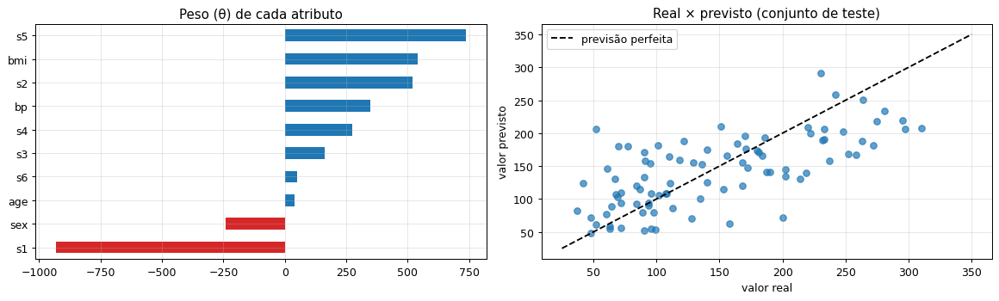

In [23]:
from sklearn.datasets import load_diabetes

diab = load_diabetes(as_frame=True)
Xdb, ydb = diab.data, diab.target
Xdb_tr, Xdb_te, ydb_tr, ydb_te = train_test_split(Xdb, ydb, test_size=0.2, random_state=42)

reg_mult = LinearRegression().fit(Xdb_tr, ydb_tr)
print(f'R² no teste: {r2_score(ydb_te, reg_mult.predict(Xdb_te)):.3f}\n')

coefs = pd.Series(reg_mult.coef_, index=Xdb.columns).sort_values()
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
coefs.plot.barh(ax=axs[0], color=[CORES[1] if c < 0 else CORES[0] for c in coefs])
axs[0].set_title('Peso (θ) de cada atributo')
axs[1].scatter(ydb_te, reg_mult.predict(Xdb_te), alpha=0.7)
axs[1].plot([25, 350], [25, 350], 'k--', label='previsão perfeita')
axs[1].set_xlabel('valor real'); axs[1].set_ylabel('valor previsto'); axs[1].legend()
axs[1].set_title('Real × previsto (conjunto de teste)')
plt.tight_layout(); plt.show()

#### 🔎 Como interpretar o resultado

- **R² no teste = 0,45:** o modelo explica cerca de **45%** da variação na progressão do diabetes. Parece baixo, mas é típico em dados **médicos reais**: a doença depende de muitos fatores não medidos (genética, hábitos, adesão ao tratamento). O resultado é **realista, não um erro**.
- **Gráfico de pesos (esquerda):** barras azuis aumentam a previsão, vermelhas diminuem. `bmi` (IMC) e `s5` (um marcador sanguíneo) estão entre os mais influentes, o que é coerente com a medicina. Os atributos deste *dataset* já vêm padronizados, por isso os pesos são comparáveis entre si.
  - ⚠️ `s1` e `s2` têm pesos grandes com **sinais opostos**. Isso costuma indicar **multicolinearidade** (atributos muito correlacionados, como dois tipos de colesterol). O modelo "compensa" um com o outro, e os pesos individuais ficam pouco confiáveis. A regularização (Seção 5.2) ajuda nesses casos.
- **Gráfico real × previsto (direita):** se o modelo fosse perfeito, todos os pontos estariam sobre a linha tracejada. A **dispersão** em volta da linha é o erro do modelo. Repare que valores reais muito altos tendem a ser **subestimados**: um modelo linear não capta tudo.

---
## Parte 5 — Generalização: *underfitting*, *overfitting* e o compromisso viés–variância

O objetivo do aprendizado é **generalizar**, não **decorar**. Mitchell define formalmente:

> Uma hipótese $h \in H$ **sobreajusta** (*overfits*) os dados de treino se existe outra hipótese $h' \in H$ tal que $h$ tem **erro menor** que $h'$ nos exemplos de treino, mas $h'$ tem **erro menor** que $h$ na **distribuição completa** de instâncias.

| Situação | Erro de treino | Erro de teste | Diagnóstico | O que fazer |
|---|:-:|:-:|---|---|
| ***Underfitting*** | Alto | Alto | Modelo **simples demais** (alto **viés**) | Modelo mais complexo, mais atributos |
| **Bom ajuste** | Baixo | Baixo | Equilíbrio | 🎉 |
| ***Overfitting*** | **Muito baixo** | Alto | Modelo **complexo demais** (alta **variância**) | Mais dados, regularização, modelo mais simples |

#### 🎛️ Regressão polinomial: aumente o grau e observe

Os dados vêm de uma senoide com ruído. Ajustamos polinômios de grau $d$: $h(x) = \theta_0 + \theta_1 x + \theta_2 x^2 + \dots + \theta_d x^d$.

In [76]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

rng = np.random.default_rng(3)
x_sen = np.sort(rng.uniform(0, 1, 20))
y_sen = np.sin(2 * np.pi * x_sen) + rng.normal(0, 0.25, x_sen.size)
x_sen_te = rng.uniform(0, 1, 100)
y_sen_te = np.sin(2 * np.pi * x_sen_te) + rng.normal(0, 0.25, x_sen_te.size)
xx_sen = np.linspace(0, 1, 300)

def ajusta_poly(grau):
    return make_pipeline(PolynomialFeatures(grau), LinearRegression()).fit(x_sen[:, None], y_sen)

graus = list(range(0, 16))
erros_tr, erros_te = [], []
for g in graus:
    m = ajusta_poly(g)
    erros_tr.append(mean_squared_error(y_sen, m.predict(x_sen[:, None])))
    erros_te.append(mean_squared_error(y_sen_te, m.predict(x_sen_te[:, None])))

def mostra_grau(grau=1):
    m = ajusta_poly(grau)
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
    axs[0].scatter(x_sen, y_sen, color=CORES[0], label='treino', zorder=3)
    axs[0].scatter(x_sen_te, y_sen_te, color='gray', s=8, alpha=0.5, label='teste')
    axs[0].plot(xx_sen, np.sin(2*np.pi*xx_sen), 'g--', alpha=0.6, label='função real')
    axs[0].plot(xx_sen, m.predict(xx_sen[:, None]), 'r-', lw=2, label=f'polinômio grau {grau}')
    axs[0].set_ylim(-2, 2); axs[0].legend(loc='lower left', fontsize=8)
    diag = 'UNDERFITTING' if grau < 3 else ('BOM AJUSTE' if grau <= 6 else 'OVERFITTING')
    axs[0].set_title(f'Grau {grau} → {diag}')
    axs[1].plot(graus, erros_tr, 'o-', label='erro de treino')
    axs[1].plot(graus, erros_te, 's-', label='erro de teste')
    axs[1].axvline(grau, color='k', ls=':')
    axs[1].set_yscale('log'); axs[1].set_xlabel('grau do polinômio (complexidade)')
    axs[1].set_ylabel('MSE (log)'); axs[1].legend(); axs[1].set_title('Erro × complexidade')
    plt.show()

interact(mostra_grau, grau=widgets.IntSlider(min=0, max=15, value=1, description='grau'));

interactive(children=(IntSlider(value=1, description='grau', max=15), Output()), _dom_classes=('widget-interac…

#### 🔎 Como usar e interpretar

Mova o *slider* e observe os **dois gráficos ao mesmo tempo**:

| Grau | Erro treino | Erro teste | Diagnóstico |
|---|---|---|---|
| 0 – 1 | Alto (~0,7 / ~0,19) | Alto (~0,58 / ~0,24) | ***Underfitting***: uma reta não consegue fazer a "onda" da senoide |
| **3 – 5** | Baixo (~0,055) | **Mínimo (~0,09)** | **Bom ajuste**: a curva acompanha a função real (verde tracejada) |
| 9 – 15 | **Baixíssimo** (~0,04) | **Explode** (0,6 → 3,7) | ***Overfitting***: a curva passa perto de cada ponto de treino, mas oscila loucamente entre eles |

- **Por que o erro de treino sempre cai?** Um polinômio de grau maior **contém** todos os de grau menor (basta zerar os coeficientes extras). Portanto ele **nunca** pode ajustar o treino pior. Com 20 pontos e grau 19, passaria **exatamente** por todos.
- **Por que o erro de teste sobe?** Com muitos parâmetros, o modelo passa a **modelar o ruído** dos 20 pontos específicos, e não a função verdadeira. Esse ruído não se repete nos dados de teste.
- **Como ler o gráfico da direita:** é a famosa **curva em U** do erro de teste. O ponto ideal de complexidade fica no fundo do U. **Nunca escolha o modelo pelo erro de treino!**

In [25]:
# 🎬 ANIMAÇÃO — aumentando a complexidade do modelo de grau 0 a 15
fig, ax = plt.subplots(figsize=(8, 4.5))
def quadro_poly(g):
    ax.clear()
    m = ajusta_poly(g)
    ax.scatter(x_sen, y_sen, color=CORES[0], zorder=3)
    ax.plot(xx_sen, np.sin(2*np.pi*xx_sen), 'g--', alpha=0.6)
    ax.plot(xx_sen, m.predict(xx_sen[:, None]), 'r-', lw=2)
    ax.set_ylim(-2, 2)
    ax.set_title(f'Grau {g} | erro treino = {erros_tr[g]:.3f} | erro teste = {erros_te[g]:.3f}')
anim = animation.FuncAnimation(fig, quadro_poly, frames=graus, interval=700)
mostrar_animacao(anim)

#### 🔎 Como interpretar a animação

- Assista prestando atenção às **bordas** do gráfico (perto de x = 0 e x = 1). A partir do grau ~9, a curva vermelha começa a fazer **oscilações violentas**: é ali que não há pontos de treino para "segurar" o polinômio.
- **Por que nas bordas?** Polinômios de grau alto crescem muito rápido (x¹⁵...). Entre pontos de treino o modelo é livre para fazer qualquer coisa, e nas extremidades essa liberdade é máxima. Esse fenômeno é conhecido como **fenômeno de Runge**.
- **Compare os números no título:** do grau 3 ao 15, o erro de treino praticamente não muda (0,055 → 0,040), mas o erro de teste multiplica por ~40. **Uma melhora pequena no treino pode custar uma piora enorme na generalização.**

### 5.1 Decomposição viés–variância

O erro esperado de um modelo em um ponto pode ser decomposto em:

$$\mathbb{E}\big[(y - \hat{h}(x))^2\big] = \underbrace{\text{Viés}^2}_{\text{suposições erradas}} + \underbrace{\text{Variância}}_{\text{sensibilidade aos dados}} + \underbrace{\sigma^2}_{\text{ruído irredutível}}$$

Para **visualizar** a variância, treinamos o mesmo tipo de modelo em **vários conjuntos de treino diferentes** sorteados da mesma distribuição:

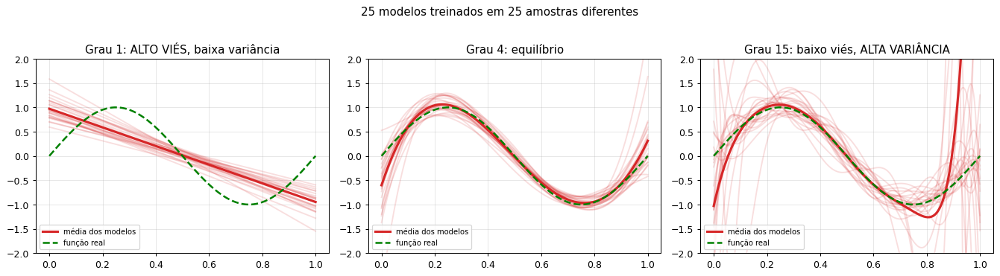

In [26]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, grau, nome in zip(axs, [1, 4, 15], ['Grau 1: ALTO VIÉS, baixa variância',
                                            'Grau 4: equilíbrio',
                                            'Grau 15: baixo viés, ALTA VARIÂNCIA']):
    previsoes = []
    for s in range(25):
        r = np.random.default_rng(100 + s)
        xs_ = np.sort(r.uniform(0, 1, 20)); ys_ = np.sin(2*np.pi*xs_) + r.normal(0, 0.25, 20)
        m = make_pipeline(PolynomialFeatures(grau), LinearRegression()).fit(xs_[:, None], ys_)
        p = m.predict(xx_sen[:, None]); previsoes.append(p)
        ax.plot(xx_sen, p, color=CORES[1], alpha=0.15)
    ax.plot(xx_sen, np.mean(previsoes, axis=0), color=CORES[1], lw=2.5, label='média dos modelos')
    ax.plot(xx_sen, np.sin(2*np.pi*xx_sen), 'g--', lw=2, label='função real')
    ax.set_ylim(-2, 2); ax.set_title(nome); ax.legend(loc='lower left', fontsize=8)
plt.suptitle('25 modelos treinados em 25 amostras diferentes', y=1.02)
plt.tight_layout(); plt.show()

#### 🔎 Como interpretar a figura

Cada linha fina vermelha é um modelo treinado em uma **amostra diferente** de 20 pontos; a linha grossa é a **média** dos 25 modelos.

| Painel | Viés (média × verde) | Variância (espalhamento das linhas finas) |
|---|---|---|
| **Grau 1** | **ALTO**: a média é uma reta, longe da senoide | Baixa: todas as retas são parecidas |
| **Grau 4** | Baixo: a média acompanha a senoide | Moderada |
| **Grau 15** | Baixo: **na média** acerta a forma | **ALTÍSSIMA**: cada amostra gera uma curva completamente diferente |

- **Viés** = erro **sistemático**, que existe porque o modelo é simples demais para representar a verdade. Mais dados **não resolvem**.
- **Variância** = **instabilidade**: o modelo muda muito conforme os dados de treino. Mais dados **ajudam muito**.
- **💡 O compromisso:** aumentar a complexidade **reduz o viés e aumenta a variância**. O melhor modelo equilibra os dois, e esse equilíbrio é exatamente o fundo da curva em U da célula anterior.

### 5.2 Regularização: penalizando a complexidade

Uma forma de combater o *overfitting* sem mudar o grau é **penalizar pesos grandes** na função de custo:

- **Ridge (L2):** $J(\theta) = \text{MSE} + \lambda \sum_j \theta_j^2$
- **Lasso (L1):** $J(\theta) = \text{MSE} + \lambda \sum_j |\theta_j|$ (zera pesos → seleção de atributos)

O hiperparâmetro $\lambda$ (no scikit-learn, `alpha`) controla a força da penalização.

In [27]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

def mostra_ridge(log_lambda=-8.0):
    lam = 10 ** log_lambda
    m = make_pipeline(PolynomialFeatures(15), StandardScaler(), Ridge(alpha=lam)).fit(x_sen[:, None], y_sen)
    err_te = mean_squared_error(y_sen_te, m.predict(x_sen_te[:, None]))
    plt.figure(figsize=(8, 4))
    plt.scatter(x_sen, y_sen, color=CORES[0], zorder=3)
    plt.plot(xx_sen, np.sin(2*np.pi*xx_sen), 'g--', alpha=0.6)
    plt.plot(xx_sen, m.predict(xx_sen[:, None]), 'r-', lw=2)
    plt.ylim(-2, 2)
    plt.title(f'Polinômio grau 15 + Ridge, λ = {lam:.0e}  |  erro de teste = {err_te:.3f}')
    plt.show()

interact(mostra_ridge, log_lambda=widgets.FloatSlider(min=-10, max=3, step=0.5, value=-8,
                                                      description='log₁₀ λ'));

interactive(children=(FloatSlider(value=-8.0, description='log₁₀ λ', max=3.0, min=-10.0, step=0.5), Output()),…

#### 🔎 Como usar e interpretar

O modelo é **sempre** um polinômio de grau 15 (que antes sofria *overfitting*); muda apenas a força da penalização λ:

| log₁₀ λ | Erro de teste | O que acontece |
|---|---|---|
| −8 | ~0,79 | Penalização quase nula: mesmo *overfitting* de antes |
| **−4 a −2** | **~0,09 – 0,10** | Os pesos ficam "comportados": curva suave, próxima da senoide |
| 0 | ~0,17 | Começa a simplificar demais |
| +2 | ~0,32 | Penalização excessiva: a curva fica quase reta (***underfitting***) |

- **Por que funciona?** O *overfitting* do grau 15 aparece com coeficientes **enormes**, de sinais alternados, que se cancelam nos pontos de treino e explodem entre eles. A penalização `λ·Σθ²` torna esses coeficientes grandes **caros**, então o otimizador prefere soluções mais suaves.
- **💡 Conceito-chave:** em vez de reduzir o **número** de parâmetros (grau), limitamos o **tamanho** deles. λ é um **botão de complexidade contínuo**, e o escolhemos com validação (Parte 11).

---
## Parte 6 — Classificação: regressão logística e Perceptron

### 6.1 Regressão logística

Para classificar (ex.: aprovado/reprovado), queremos uma **probabilidade** entre 0 e 1. A regressão logística passa a combinação linear pela **função sigmoide**:

$$h_\theta(\mathbf{x}) = \sigma(\boldsymbol{\theta}^T \mathbf{x}) = \frac{1}{1 + e^{-\boldsymbol{\theta}^T \mathbf{x}}} = P(y = 1 \mid \mathbf{x})$$

Classificamos como 1 se $h_\theta(\mathbf{x}) \geq 0{,}5$, ou seja, se $\boldsymbol{\theta}^T \mathbf{x} \geq 0$. A **fronteira de decisão** $\boldsymbol{\theta}^T \mathbf{x} = 0$ é uma reta (ou hiperplano).

A função de custo é a **entropia cruzada** (*log-loss*):

$$J(\theta) = -\frac{1}{m}\sum_{i=1}^{m}\Big[y^{(i)}\log h_\theta(x^{(i)}) + (1-y^{(i)})\log\big(1-h_\theta(x^{(i)})\big)\Big]$$

e, curiosamente, seu gradiente tem a **mesma forma** da regressão linear: $\nabla J = \frac{1}{m} X^T (h_\theta(X) - \mathbf{y})$.

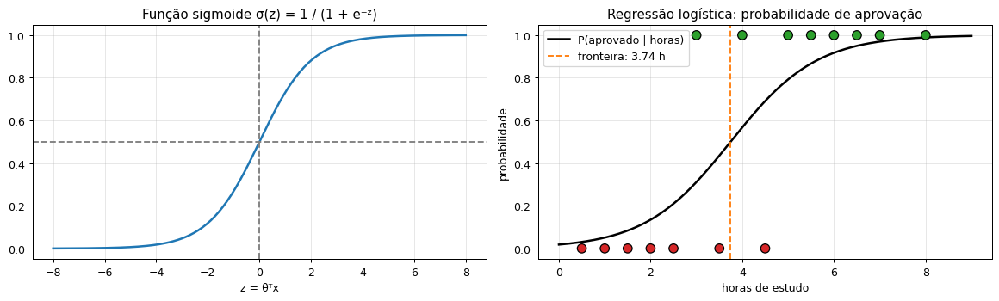

Estudando 2 h → P(aprovado) = 13.5%
Estudando 4 h → P(aprovado) = 56.8%
Estudando 6 h → P(aprovado) = 91.7%


In [28]:
sigmoide = lambda z: 1 / (1 + np.exp(-z))

# Exemplo intuitivo: horas de estudo × aprovação
horas = np.array([0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6, 6.5, 7, 8])
aprovado = np.array([0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1])

log1d = LogisticRegression().fit(horas.reshape(-1, 1), aprovado)
hh = np.linspace(0, 9, 200)

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
z = np.linspace(-8, 8, 200)
axs[0].plot(z, sigmoide(z), lw=2); axs[0].axhline(0.5, ls='--', color='gray'); axs[0].axvline(0, ls='--', color='gray')
axs[0].set_title('Função sigmoide σ(z) = 1 / (1 + e⁻ᶻ)'); axs[0].set_xlabel('z = θᵀx')

axs[1].scatter(horas, aprovado, c=aprovado, cmap=ListedColormap([CORES[1], CORES[2]]), s=70, edgecolor='k', zorder=3)
axs[1].plot(hh, log1d.predict_proba(hh.reshape(-1, 1))[:, 1], 'k-', lw=2, label='P(aprovado | horas)')
limiar = -log1d.intercept_[0] / log1d.coef_[0, 0]
axs[1].axvline(limiar, color=CORES[3], ls='--', label=f'fronteira: {limiar:.2f} h')
axs[1].set_xlabel('horas de estudo'); axs[1].set_ylabel('probabilidade'); axs[1].legend()
axs[1].set_title('Regressão logística: probabilidade de aprovação')
plt.tight_layout(); plt.show()

for h in [2, 4, 6]:
    print(f'Estudando {h} h → P(aprovado) = {log1d.predict_proba([[h]])[0, 1]:.1%}')

#### 🔎 Como interpretar o resultado

- **Esquerda, a sigmoide:** transforma qualquer número real `z` em um valor entre 0 e 1. Para z muito negativo dá ≈ 0; para z = 0 dá 0,5; para z muito positivo dá ≈ 1. Por isso podemos ler a saída como **probabilidade**.
- **Direita, o modelo de aprovação:**
  - Os pontos são os alunos (0 = reprovado, 1 = aprovado). Repare que **há sobreposição**: um aluno com 3 h passou e outro com 4,5 h reprovou. Não existe um limiar perfeito.
  - A curva preta é `P(aprovado | horas)`. Ela sobe suavemente, refletindo **incerteza** na região de transição.
  - A fronteira laranja (~**3,7 h**) é onde P = 50%.
- **Lendo as previsões:** 2 h → 13,5%; 4 h → 56,8%; 6 h → 91,7%. A regressão logística não dá só "sim/não": dá **o quanto confiamos** na resposta. Isso é essencial em aplicações reais (ex.: só aprovar um crédito automaticamente se P > 90%).
- **Por que não usar regressão linear aqui?** Uma reta produziria "probabilidades" negativas ou maiores que 1, e seria muito influenciada por alunos que estudaram muitas horas.

In [77]:
# Implementação do zero + 🎬 ANIMAÇÃO da fronteira de decisão durante o treino
class RegressaoLogisticaGD:
    def __init__(self, alpha=0.5, n_iter=300):
        self.alpha, self.n_iter = alpha, n_iter

    def fit(self, X, y):
        Xb = np.c_[np.ones(len(X)), X]
        self.theta = np.zeros(Xb.shape[1])
        self.hist_theta, self.hist_custo = [], []
        for _ in range(self.n_iter):
            p = sigmoide(Xb @ self.theta)
            custo = -np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12))
            self.hist_custo.append(custo); self.hist_theta.append(self.theta.copy())
            self.theta -= self.alpha * Xb.T @ (p - y) / len(y)
        return self

    def predict_proba(self, X):
        return sigmoide(np.c_[np.ones(len(X)), X] @ self.theta)

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)


Xlog, ylog = make_blobs(n_samples=200, centers=[(-1.5, -1), (1.5, 1.2)], cluster_std=1.1, random_state=1)
rlog = RegressaoLogisticaGD(alpha=0.3, n_iter=120).fit(Xlog, ylog)
print(f'Acurácia (treino) do nosso modelo: {(rlog.predict(Xlog) == ylog).mean():.1%}')

xx, yy = np.meshgrid(np.linspace(-5, 5, 120), np.linspace(-5, 5, 120))
grade_pts = np.c_[np.ones(xx.size), xx.ravel(), yy.ravel()]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
quadros_log = list(range(0, 120, 3))

def quadro_log(k):
    ax1.clear()
    th = rlog.hist_theta[k]
    P = sigmoide(grade_pts @ th).reshape(xx.shape)
    ax1.contourf(xx, yy, P, levels=20, cmap='RdBu', alpha=0.5, vmin=0, vmax=1)
    ax1.contour(xx, yy, P, levels=[0.5], colors='k', linewidths=2)
    ax1.scatter(Xlog[:, 0], Xlog[:, 1], c=ylog, cmap=ListedColormap([CORES[1], CORES[0]]), edgecolor='k', s=25)
    ax1.set_title(f'Iteração {k}: fronteira P = 0,5'); ax1.set_xlim(-5, 5); ax1.set_ylim(-5, 5)
    ax2.clear(); ax2.plot(rlog.hist_custo[:k+1], color=CORES[2], lw=2)
    ax2.set_xlim(0, 120); ax2.set_ylim(0, 0.75); ax2.set_title('Entropia cruzada (custo)')
    ax2.set_xlabel('iteração')

anim = animation.FuncAnimation(fig, quadro_log, frames=quadros_log, interval=120)
mostrar_animacao(anim)

Acurácia (treino) do nosso modelo: 95.0%


#### 🔎 Como interpretar a animação

- **Cores de fundo:** azul intenso = alta probabilidade da classe azul, vermelho intenso = alta probabilidade da classe vermelha, branco = incerteza (P ≈ 0,5). A linha preta é a **fronteira de decisão** (P = 0,5).
- **O que acontece:**
  1. **Iteração 0:** θ = 0, então P = 0,5 em todo o plano. O custo inicial é **0,693 = ln 2**, o custo de "chutar 50%" para todos.
  2. Nas primeiras iterações, a fronteira **gira e se desloca** rapidamente para separar as nuvens.
  3. Depois, a faixa de transição branca vai **ficando mais estreita**: o modelo fica mais **confiante** à medida que os pesos crescem.
- **Curva de custo (direita):** cai de 0,69 para ~**0,13**. Ela não chega a zero porque as classes **se sobrepõem um pouco** (alguns pontos estão "do lado errado"), por isso a acurácia final é 95% e não 100%.
- **💡 Conceito-chave:** a fronteira da regressão logística é sempre uma **reta** (hiperplano). Ela é um **classificador linear**, mesmo usando uma função não linear (a sigmoide) para gerar probabilidades.

### 6.2 O Perceptron de Rosenblatt (1957)

O **Perceptron** é o neurônio artificial mais simples e o ancestral das redes neurais (Mitchell, cap. 4):

$$o(\mathbf{x}) = \begin{cases} +1 & \text{se } w_0 + w_1x_1 + \dots + w_nx_n > 0 \\ -1 & \text{caso contrário} \end{cases}$$

**Regra de treinamento do Perceptron** — a cada exemplo **classificado errado**:

$$w_i \leftarrow w_i + \eta\,(t - o)\,x_i$$

onde $t$ é o rótulo correto, $o$ é a saída do perceptron e $\eta$ é a taxa de aprendizado.

> 📌 **Teorema da convergência:** se os dados forem **linearmente separáveis**, o Perceptron encontra uma reta separadora em um número finito de passos. Se **não forem** (ex.: XOR), ele nunca converge — limitação apontada por **Minsky e Papert (1969)**, que motivou as redes multicamadas.

In [30]:
class Perceptron:
    def __init__(self, eta=0.1, epocas=10):
        self.eta, self.epocas = eta, epocas

    def fit(self, X, y):                  # y ∈ {-1, +1}
        self.w = np.zeros(X.shape[1] + 1)
        self.historico = []               # (w, índice do ponto que causou a atualização)
        self.erros_por_epoca = []
        for _ in range(self.epocas):
            erros = 0
            for i, (xi, ti) in enumerate(zip(X, y)):
                o = self.predict(xi.reshape(1, -1))[0]
                if o != ti:
                    self.w[1:] += self.eta * (ti - o) * xi
                    self.w[0]  += self.eta * (ti - o)
                    self.historico.append((self.w.copy(), i))
                    erros += 1
            self.erros_por_epoca.append(erros)
            if erros == 0:
                break
        return self

    def predict(self, X):
        return np.where(X @ self.w[1:] + self.w[0] > 0, 1, -1)


Xp, yp = make_blobs(n_samples=60, centers=[(-1.5, -1), (1.5, 1)], cluster_std=0.9, random_state=23)
yp = np.where(yp == 0, -1, 1)
perc = Perceptron(eta=0.1, epocas=50).fit(Xp, yp)
print('Erros por época:', perc.erros_por_epoca)
print(f'Convergiu após {len(perc.historico)} atualizações de pesos. Pesos finais: {perc.w.round(3)}')

Erros por época: [4, 2, 2, 2, 2, 1, 0]
Convergiu após 13 atualizações de pesos. Pesos finais: [0.2   0.497 0.256]


#### 🔎 Como interpretar o resultado

- **Erros por época = [4, 2, 2, 2, 2, 1, 0]:** uma **época** é uma passagem completa pelos 60 exemplos. Na 1ª época, 4 exemplos estavam do lado errado e causaram correções. A quantidade de erros vai diminuindo até chegar a **zero na 7ª época**: todos os pontos estão corretamente separados e o algoritmo **para**.
- **13 atualizações no total:** o Perceptron só muda os pesos quando **erra**. Quando acerta, não faz nada (aprendizado **orientado ao erro**).
- **Pesos finais [0,2; 0,497; 0,256]:** definem a reta `0,2 + 0,497·x₁ + 0,256·x₂ = 0`. Qualquer reta que separe as classes serve; o Perceptron **não procura a melhor**, apenas **uma** que funcione (compare com a SVM na Parte 10, que busca a de margem máxima).
- **Por que convergiu?** Porque as duas nuvens são **linearmente separáveis**. Nesse caso, o **teorema de convergência do Perceptron** garante que o algoritmo termina em um número finito de passos.

In [81]:
# 🎬 ANIMAÇÃO — cada quadro é uma correção do Perceptron (o ponto destacado foi o erro)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
xs_line = np.array([-6, 6])

def quadro_perc(k):
    ax.clear()
    w, i = perc.historico[k]
    ax.scatter(Xp[:, 0], Xp[:, 1], c=yp, cmap=ListedColormap([CORES[1], CORES[0]]), edgecolor='k')
    ax.scatter(*Xp[i], s=300, facecolors='none', edgecolors='gold', linewidths=3, label='exemplo mal classificado')
    if abs(w[2]) > 1e-9:
        ax.plot(xs_line, -(w[0] + w[1] * xs_line) / w[2], 'k-', lw=2, label='fronteira')
    ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.legend(loc='upper left', fontsize=8)
    ax.set_title(f'Atualização {k+1}/{len(perc.historico)}:  w = {np.round(w, 2)}')

anim = animation.FuncAnimation(fig, quadro_perc, frames=len(perc.historico), interval=500)
mostrar_animacao(anim)

#### 🔎 Como interpretar a animação

- Cada quadro mostra a reta **logo depois** de uma correção. O círculo dourado marca o exemplo que estava errado e provocou a mudança.
- **Repare na direção do movimento:** após cada correção, a reta se move **em direção ao ponto errado**, tentando deixá-lo do lado certo. Pela regra `w ← w + η(t − o)x`:
  - se um ponto **azul** (t = +1) foi classificado como vermelho, somamos `2η·x` aos pesos e a reta "puxa" esse ponto para o lado azul;
  - se um ponto **vermelho** foi classificado como azul, subtraímos, e o efeito é o oposto.
- **Por que às vezes a reta piora?** Uma correção conserta **um** ponto, mas pode estragar outros. É por isso que a mesma época pode ter vários erros. Mesmo assim, **no conjunto** o algoritmo progride e termina sem erros.

In [32]:
# O problema XOR: o Perceptron NÃO consegue separar com uma reta
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([-1, 1, 1, -1])
p_xor = Perceptron(eta=0.1, epocas=50).fit(X_xor, y_xor)
print('Erros por época no XOR (nunca chega a zero):', p_xor.erros_por_epoca[:15], '...')
print('Acurácia final:', (p_xor.predict(X_xor) == y_xor).mean())

from sklearn.neural_network import MLPClassifier
mlp = MLPClassifier(hidden_layer_sizes=(4,), activation='tanh', solver='lbfgs', random_state=1).fit(X_xor, y_xor)
print('Rede com 1 camada oculta (MLP) no XOR — acurácia:', (mlp.predict(X_xor) == y_xor).mean())
print('👉 Redes neurais multicamadas serão estudadas na Aula 11.')

Erros por época no XOR (nunca chega a zero): [2, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4] ...
Acurácia final: 0.5
Rede com 1 camada oculta (MLP) no XOR — acurácia: 1.0
👉 Redes neurais multicamadas serão estudadas na Aula 11.


#### 🔎 Como interpretar o resultado

- **Os 4 pontos do XOR:** (0,0) → −1, (1,1) → −1, (0,1) → +1, (1,0) → +1. As classes ficam nas **diagonais opostas** de um quadrado.
- **Erros por época nunca chegam a zero:** o Perceptron fica **oscilando para sempre**. Corrige um ponto, estraga outro, e assim por diante. A acurácia final de **50%** é a mesma de um chute.
- **Por que acontece?** Tente desenhar **uma única reta** que deixe (0,1) e (1,0) de um lado e (0,0) e (1,1) do outro: **é impossível**. O XOR **não é linearmente separável**, e um Perceptron só consegue representar fronteiras lineares. Isso é um limite do **espaço de hipóteses** (viés de representação), não um problema de treino.
- **A solução:** uma rede com uma **camada oculta** (MLP) acerta 100%. A camada oculta cria **novos atributos** (combinações não lineares das entradas) nos quais o problema se torna separável.
- **💡 Importância histórica:** essa limitação, demonstrada por Minsky e Papert em 1969, contribuiu para reduzir o interesse em redes neurais por mais de uma década, até a popularização do *backpropagation* para redes multicamadas (1986).

---
## Parte 7 — Aprendizado baseado em instâncias: K-Vizinhos Mais Próximos (KNN)

> *"Diga-me com quem andas e te direi quem és."*

O **KNN** (Cover & Hart, 1967; Mitchell, cap. 8) é um aprendiz **preguiçoso** (*lazy*): no treino ele apenas **guarda** os exemplos. Para classificar uma nova instância $x_q$:

1. Calcula a distância de $x_q$ a **todos** os exemplos de treino;
2. Seleciona os $k$ mais próximos;
3. **Classificação:** vota a classe majoritária. **Regressão:** média dos valores.

**Distâncias comuns:**

| Distância | Fórmula |
|---|---|
| Euclidiana | $d(\mathbf{a},\mathbf{b}) = \sqrt{\sum_i (a_i - b_i)^2}$ |
| Manhattan | $d(\mathbf{a},\mathbf{b}) = \sum_i \lvert a_i - b_i \rvert$ |
| Minkowski | $d(\mathbf{a},\mathbf{b}) = \big(\sum_i \lvert a_i - b_i \rvert^p\big)^{1/p}$ |

**Viés indutivo:** a classe de uma instância é parecida com a das instâncias **próximas** a ela.

#### 🧪 Exemplo à mão: qual é o gênero deste filme?

| Filme | nº de cenas de luta | nº de beijos | Gênero |
|---|:-:|:-:|---|
| A | 3 | 104 | Romance |
| B | 2 | 100 | Romance |
| C | 1 | 81 | Romance |
| D | 101 | 10 | Ação |
| E | 99 | 5 | Ação |
| F | 98 | 2 | Ação |
| **?** | **18** | **90** | **???** |

In [33]:
from collections import Counter

filmes = np.array([[3, 104], [2, 100], [1, 81], [101, 10], [99, 5], [98, 2]], dtype=float)
generos = np.array(['Romance', 'Romance', 'Romance', 'Ação', 'Ação', 'Ação'])
novo = np.array([18, 90])

dist = np.sqrt(((filmes - novo) ** 2).sum(axis=1))
tabela = pd.DataFrame({'filme': list('ABCDEF'), 'lutas': filmes[:, 0], 'beijos': filmes[:, 1],
                       'gênero': generos, 'distância': dist.round(1)}).sort_values('distância')
display(tabela)
k = 3
votos = Counter(tabela['gênero'].iloc[:k])
print(f'Os {k} vizinhos mais próximos votam: {dict(votos)}  →  o filme é de {votos.most_common(1)[0][0]}!')

,filme,lutas,beijos,gênero,distância
1,B,2.0,100.0,Romance,18.9
2,C,1.0,81.0,Romance,19.2
0,A,3.0,104.0,Romance,20.5
3,D,101.0,10.0,Ação,115.3
4,E,99.0,5.0,Ação,117.4
5,F,98.0,2.0,Ação,118.9


Os 3 vizinhos mais próximos votam: {'Romance': 3}  →  o filme é de Romance!


#### 🔎 Como interpretar o resultado

- **Tabela ordenada por distância:** o filme novo (18 lutas, 90 beijos) está a ~19–20 unidades dos três romances e a mais de 115 dos filmes de ação. Exemplo de cálculo para o filme B: √((18−2)² + (90−100)²) = √(256 + 100) ≈ **18,9**.
- **Votação:** os 3 vizinhos mais próximos (B, C, A) são Romance, então a previsão é **Romance**.
- **Por que faz sentido?** Apesar de ter mais lutas que um romance típico, o filme novo tem **muitos beijos**, e nesse "espaço de atributos" ele fica no **bairro** dos romances.
- **⚠️ Perceba a dependência da escala:** se os beijos fossem medidos em "dezenas de beijos", essa diferença valeria 10× menos e o resultado poderia mudar. Por isso **padronizamos** os atributos antes do KNN (Parte 3).

In [34]:
class KNN:
    def __init__(self, k=3, metrica='euclidiana'):
        self.k, self.metrica = k, metrica

    def fit(self, X, y):
        self.X, self.y = np.asarray(X, float), np.asarray(y)   # apenas memoriza!
        return self

    def _distancias(self, x):
        if self.metrica == 'manhattan':
            return np.abs(self.X - x).sum(axis=1)
        return np.sqrt(((self.X - x) ** 2).sum(axis=1))

    def vizinhos(self, x):
        return np.argsort(self._distancias(x))[:self.k]

    def predict(self, X):
        return np.array([Counter(self.y[self.vizinhos(x)]).most_common(1)[0][0] for x in np.asarray(X, float)])


from sklearn.datasets import load_iris
iris = load_iris()
Xi = iris.data[:, [2, 3]]          # comprimento e largura da pétala (2D para visualizar)
yi = iris.target
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.3, random_state=42, stratify=yi)

meu_knn = KNN(k=5).fit(Xi_tr, yi_tr)
print(f'Nosso KNN (k=5) — acurácia no teste: {(meu_knn.predict(Xi_te) == yi_te).mean():.1%}')

from sklearn.neighbors import KNeighborsClassifier
knn_sk = KNeighborsClassifier(n_neighbors=5).fit(Xi_tr, yi_tr)
print(f'scikit-learn    — acurácia no teste: {knn_sk.score(Xi_te, yi_te):.1%}')

Nosso KNN (k=5) — acurácia no teste: 93.3%
scikit-learn    — acurácia no teste: 93.3%


#### 🔎 Como interpretar o resultado

- **"Treinar" o KNN = guardar os dados.** O método `fit` só copia `X` e `y`. Todo o trabalho acontece no `predict`, por isso o KNN é chamado de aprendiz **preguiçoso** (*lazy*): treino instantâneo, predição mais lenta.
- **Nosso KNN e o do scikit-learn dão a mesma acurácia (93,3%)**, o que confirma que a implementação está correta. A versão do scikit-learn é muito mais rápida em bases grandes porque usa estruturas como **KD-Tree** e **Ball-Tree** para encontrar vizinhos sem calcular todas as distâncias.
- **Por que só 2 atributos (pétala)?** Para conseguirmos **visualizar** no plano. Com os 4 atributos do Iris, a acurácia é parecida, já que as pétalas são os atributos mais informativos (como a árvore de decisão confirmará mais adiante).
- **Os ~7% de erro** vêm da região onde *versicolor* e *virginica* se sobrepõem: flores com pétalas de tamanho intermediário.

In [35]:
# 🎬 ANIMAÇÃO — um ponto novo "procura" seus vizinhos
consultas = np.array([[2.5, 0.8], [4.9, 1.6], [5.0, 1.75], [4.0, 1.2], [6.0, 2.2]])
nomes_cls = iris.target_names
fig, ax = plt.subplots(figsize=(7.5, 5.5))
k_anim = 5

def quadro_knn(f):
    q, etapa = consultas[f // 3], f % 3
    ax.clear()
    ax.scatter(Xi_tr[:, 0], Xi_tr[:, 1], c=yi_tr, cmap=CMAP_PONTOS, edgecolor='k', s=35)
    ax.scatter(*q, marker='*', s=400, color='gold', edgecolor='k', zorder=5)
    titulo = 'Novo ponto ★ — quem são seus vizinhos?'
    if etapa >= 1:
        viz = meu_knn.vizinhos(q)
        raio = np.sqrt(((Xi_tr[viz[-1]] - q) ** 2).sum())
        ax.add_patch(plt.Circle(q, raio, fill=False, ls='--', color='k'))
        for v in viz:
            ax.plot([q[0], Xi_tr[v, 0]], [q[1], Xi_tr[v, 1]], 'k-', alpha=0.6)
        titulo = f'Os {k_anim} vizinhos mais próximos'
    if etapa == 2:
        votos = Counter(yi_tr[viz])
        classe = votos.most_common(1)[0][0]
        ax.scatter(*q, marker='*', s=400, color=CORES[classe], edgecolor='k', zorder=6)
        titulo = 'Votos: ' + ', '.join(f'{nomes_cls[c]}={n}' for c, n in votos.items()) + f'  →  {nomes_cls[classe].upper()}'
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel('comprimento da pétala (cm)'); ax.set_ylabel('largura da pétala (cm)')
    ax.set_xlim(0.5, 7.2); ax.set_ylim(-0.2, 2.8); ax.set_aspect('equal')

anim = animation.FuncAnimation(fig, quadro_knn, frames=3 * len(consultas), interval=900)
mostrar_animacao(anim)

#### 🔎 Como interpretar a animação

Cada ponto novo (★) passa por 3 quadros, que correspondem às 3 etapas do algoritmo:

1. **★ amarela:** o ponto a classificar aparece; ainda não sabemos sua classe.
2. **Círculo tracejado + linhas:** os **5 vizinhos mais próximos**. O raio do círculo é a distância até o 5º vizinho. Repare que o círculo é **pequeno em regiões densas** e **grande em regiões vazias**: o KNN se adapta à densidade dos dados.
3. **★ colorida + votos no título:** a classe majoritária é atribuída.
- **Casos interessantes:**
  - Pontos no meio de uma nuvem recebem **5 votos a 0**: classificação fácil e confiável.
  - Pontos na **fronteira** entre *versicolor* (verde) e *virginica* (vermelho) recebem votos **divididos**, como 3 a 2. Aqui o KNN é menos confiável, e mudar *k* pode mudar a resposta.
- **💡 Conceito-chave:** o KNN não constrói uma regra global; ele toma uma **decisão local** para cada consulta. Mitchell chama isso de **aprendizado baseado em instâncias**.

#### 🎛️ Como o valor de $k$ afeta a fronteira de decisão?

- $k = 1$: fronteira muito **irregular** → tende ao *overfitting*;
- $k$ muito grande: fronteira muito **suave** → tende ao *underfitting* (no limite, prevê sempre a classe majoritária).

In [78]:
from sklearn.datasets import make_moons
Xm, ym = make_moons(n_samples=250, noise=0.3, random_state=0)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.3, random_state=0)

def knn_k(k=1):
    m = KNeighborsClassifier(n_neighbors=k).fit(Xm_tr, ym_tr)
    fig, ax = plt.subplots(figsize=(7, 4.5))
    plot_fronteira(m, Xm_tr, ym_tr, ax=ax,
                   titulo=f'k = {k} | acurácia treino = {m.score(Xm_tr, ym_tr):.0%} | teste = {m.score(Xm_te, ym_te):.0%}')
    plt.show()

interact(knn_k, k=widgets.IntSlider(min=1, max=101, step=2, value=1, description='k'));

interactive(children=(IntSlider(value=1, description='k', max=101, min=1, step=2), Output()), _dom_classes=('w…

#### 🔎 Como usar e interpretar

Mova o *slider* e compare as acurácias de **treino** e **teste** no título:

| k | Fronteira | Treino | Teste | Diagnóstico |
|---|---|---|---|---|
| **1** | Cheia de "ilhas" ao redor de pontos isolados | **100%** | ~85% | *Overfitting*: cada ponto de treino é seu próprio vizinho, então o treino é sempre 100% |
| **15** | Suave, acompanha o formato das luas | ~90% | **~91%** | Bom equilíbrio |
| **101** | Quase uma reta | ~79% | ~77% | *Underfitting*: k é ~40% dos dados, então cada voto envolve pontos muito distantes |

- **Por que k = 1 tem 100% no treino?** Ao classificar um ponto de treino, o vizinho mais próximo dele é **ele mesmo** (distância zero). Isso não significa que o modelo é bom; significa que ele **decorou**.
- **Por que *k* ímpar?** Em problemas com 2 classes, evita empates na votação.
- **💡 Conceito-chave:** *k* controla a **complexidade** do KNN, com sentido inverso ao do grau do polinômio: **k pequeno = modelo complexo**, **k grande = modelo simples**.

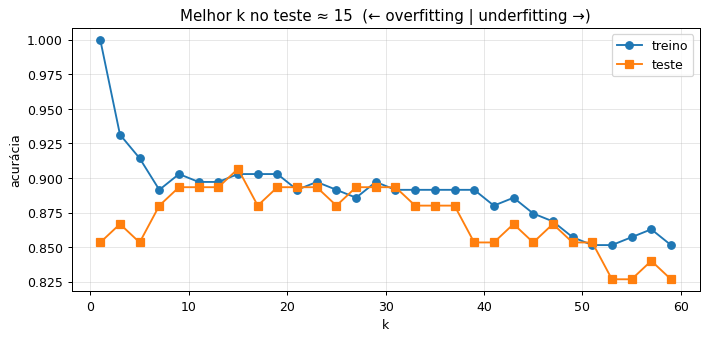

In [37]:
# Escolhendo k: curva de acurácia × k
ks = range(1, 60, 2)
acc_tr = [KNeighborsClassifier(n_neighbors=k).fit(Xm_tr, ym_tr).score(Xm_tr, ym_tr) for k in ks]
acc_te = [KNeighborsClassifier(n_neighbors=k).fit(Xm_tr, ym_tr).score(Xm_te, ym_te) for k in ks]
plt.figure(figsize=(9, 3.8))
plt.plot(ks, acc_tr, 'o-', label='treino'); plt.plot(ks, acc_te, 's-', label='teste')
plt.xlabel('k'); plt.ylabel('acurácia'); plt.legend()
plt.title(f'Melhor k no teste ≈ {list(ks)[int(np.argmax(acc_te))]}  (← overfitting | underfitting →)')
plt.show()

#### 🔎 Como interpretar o gráfico

- **Linha de treino (azul):** começa em 100% (k = 1) e **cai continuamente**, pois o modelo fica cada vez mais simples.
- **Linha de teste (laranja):** começa mais baixa, **sobe** até um máximo e depois **cai**. É a mesma curva em U (invertida, porque aqui medimos acerto e não erro) que vimos com os polinômios.
- **Distância entre as curvas:** à esquerda, a grande diferença entre treino e teste indica **variância alta** (*overfitting*). À direita, as duas curvas caem juntas, o que indica **viés alto** (*underfitting*).
- **⚠️ Cuidado metodológico:** aqui escolhemos *k* olhando o **teste** apenas para fins didáticos. Em um projeto real, *k* deve ser escolhido com **validação cruzada** (Parte 11), deixando o teste intocado até o final.

---
## Parte 8 — Aprendizado bayesiano: Naive Bayes (Mitchell, Cap. 6)

### 8.1 Teorema de Bayes

$$P(h \mid D) = \frac{P(D \mid h)\,P(h)}{P(D)}$$

- $P(h)$: probabilidade **a priori** da hipótese;
- $P(D \mid h)$: **verossimilhança** — probabilidade de observar os dados se $h$ for verdadeira;
- $P(h \mid D)$: probabilidade **a posteriori** — o que queremos!

A hipótese **MAP** (*maximum a posteriori*) é: $h_{MAP} = \arg\max_{h} P(D \mid h)\,P(h)$.

### 8.2 O classificador Naive Bayes

Para uma instância com atributos $a_1, \dots, a_n$, assumimos (de forma "ingênua") que os atributos são **condicionalmente independentes** dada a classe:

$$v_{NB} = \arg\max_{v_j \in V} P(v_j) \prod_{i} P(a_i \mid v_j)$$

Apesar da suposição simplificadora, funciona **muito bem** na prática — especialmente com **texto** (filtros de spam!).

#### 🧪 Exemplo à mão (Mitchell, Tabela 3.2): vou jogar tênis hoje?

Usaremos o famoso conjunto **PlayTennis** (14 dias), que também será usado no ID3 (Parte 9).

In [38]:
tenis = pd.DataFrame([
    ['Ensolarado', 'Quente', 'Alta',   'Fraco', 'Não'],
    ['Ensolarado', 'Quente', 'Alta',   'Forte', 'Não'],
    ['Nublado',    'Quente', 'Alta',   'Fraco', 'Sim'],
    ['Chuvoso',    'Amena',  'Alta',   'Fraco', 'Sim'],
    ['Chuvoso',    'Fria',   'Normal', 'Fraco', 'Sim'],
    ['Chuvoso',    'Fria',   'Normal', 'Forte', 'Não'],
    ['Nublado',    'Fria',   'Normal', 'Forte', 'Sim'],
    ['Ensolarado', 'Amena',  'Alta',   'Fraco', 'Não'],
    ['Ensolarado', 'Fria',   'Normal', 'Fraco', 'Sim'],
    ['Chuvoso',    'Amena',  'Normal', 'Fraco', 'Sim'],
    ['Ensolarado', 'Amena',  'Normal', 'Forte', 'Sim'],
    ['Nublado',    'Amena',  'Alta',   'Forte', 'Sim'],
    ['Nublado',    'Quente', 'Normal', 'Fraco', 'Sim'],
    ['Chuvoso',    'Amena',  'Alta',   'Forte', 'Não'],
], columns=['Tempo', 'Temperatura', 'Umidade', 'Vento', 'Jogar'], index=[f'D{i}' for i in range(1, 15)])
display(tenis)

,Tempo,Temperatura,Umidade,Vento,Jogar
D1,Ensolarado,Quente,Alta,Fraco,Não
D2,Ensolarado,Quente,Alta,Forte,Não
D3,Nublado,Quente,Alta,Fraco,Sim
D4,Chuvoso,Amena,Alta,Fraco,Sim
D5,Chuvoso,Fria,Normal,Fraco,Sim
D6,Chuvoso,Fria,Normal,Forte,Não
D7,Nublado,Fria,Normal,Forte,Sim
D8,Ensolarado,Amena,Alta,Fraco,Não
D9,Ensolarado,Fria,Normal,Fraco,Sim
D10,Chuvoso,Amena,Normal,Fraco,Sim


#### 🔎 Como interpretar a tabela

- São **14 dias** (D1–D14) descritos por 4 atributos **categóricos** e o rótulo `Jogar` (9 Sim, 5 Não). É o conjunto *PlayTennis* da Tabela 3.2 do livro de Mitchell, usado tanto no Naive Bayes quanto no ID3.
- **Já dá para notar padrões "a olho":** todos os dias **Nublado** são "Sim"; dias **Ensolarado** com umidade **Alta** são "Não". Os algoritmos a seguir vão descobrir esses padrões **automaticamente**, cada um com seu próprio viés indutivo.

In [39]:
class NaiveBayesCategorico:
    def __init__(self, suavizacao=0.0):     # suavizacao=1 → correção de Laplace
        self.alpha = suavizacao

    def fit(self, df, alvo):
        self.alvo, self.atributos = alvo, [c for c in df.columns if c != alvo]
        self.classes = df[alvo].unique()
        self.prior = df[alvo].value_counts(normalize=True).to_dict()
        self.verossimilhanca = {}
        for c in self.classes:
            sub = df[df[alvo] == c]
            for a in self.atributos:
                n_valores = df[a].nunique()
                for v in df[a].unique():
                    self.verossimilhanca[(a, v, c)] = ((sub[a] == v).sum() + self.alpha) / (len(sub) + self.alpha * n_valores)
        return self

    def pontuacoes(self, x, verbose=False):
        res = {}
        for c in self.classes:
            p = self.prior[c]
            termos = [f'P({c})={p:.3f}']
            for a in self.atributos:
                pv = self.verossimilhanca.get((a, x[a], c), 0)
                p *= pv
                termos.append(f'P({a}={x[a]}|{c})={pv:.3f}')
            res[c] = p
            if verbose:
                print(f'  {c:>3}: ' + ' × '.join(termos) + f'\n       = {p:.5f}')
        return res

    def predict_one(self, x, verbose=False):
        s = self.pontuacoes(x, verbose)
        total = sum(s.values())
        if verbose:
            for c, v in s.items():
                print(f'  P({c} | x) normalizada = {v/total:.1%}')
        return max(s, key=s.get)


nb = NaiveBayesCategorico().fit(tenis, 'Jogar')
dia_novo = {'Tempo': 'Ensolarado', 'Temperatura': 'Fria', 'Umidade': 'Alta', 'Vento': 'Forte'}
print('Dia novo:', dia_novo, '\n')
print('Decisão final → Jogar =', nb.predict_one(dia_novo, verbose=True))

Dia novo: {'Tempo': 'Ensolarado', 'Temperatura': 'Fria', 'Umidade': 'Alta', 'Vento': 'Forte'} 

  Não: P(Não)=0.357 × P(Tempo=Ensolarado|Não)=0.600 × P(Temperatura=Fria|Não)=0.200 × P(Umidade=Alta|Não)=0.800 × P(Vento=Forte|Não)=0.600
       = 0.02057
  Sim: P(Sim)=0.643 × P(Tempo=Ensolarado|Sim)=0.222 × P(Temperatura=Fria|Sim)=0.333 × P(Umidade=Alta|Sim)=0.333 × P(Vento=Forte|Sim)=0.333
       = 0.00529
  P(Não | x) normalizada = 79.5%
  P(Sim | x) normalizada = 20.5%
Decisão final → Jogar = Não


#### 🔎 Como interpretar o cálculo passo a passo

- **Priors:** P(Sim) = 9/14 = 0,643 e P(Não) = 5/14 = 0,357. Antes de olhar o tempo, "Sim" é mais provável.
- **Verossimilhanças** (contadas na tabela). Para a classe **Não** (5 dias):
  - Ensolarado em 3 de 5 → **0,600**
  - Fria em 1 de 5 → **0,200**
  - Alta em 4 de 5 → **0,800**
  - Forte em 3 de 5 → **0,600**
- **Produto:** P(Não)·Π = 0,357 × 0,6 × 0,2 × 0,8 × 0,6 ≈ **0,0206**; P(Sim)·Π ≈ **0,0053**.
- **Normalizando** (dividindo cada um pela soma): **P(Não | dia) ≈ 79,5%**. Apesar de "Sim" ser mais comum em geral (prior maior), as evidências deste dia, **sol + umidade alta + vento forte**, apontam fortemente para "Não".
- **💡 Por que "ingênuo"?** Multiplicamos as probabilidades como se Umidade e Tempo, por exemplo, fossem independentes. Na realidade não são, mas mesmo assim o **ranking** entre as classes costuma estar certo, e é só isso que importa para decidir.

> ⚠️ **Problema da frequência zero:** se um valor nunca apareceu com uma classe, o produto inteiro vira 0. A **suavização de Laplace** (somar 1 às contagens) resolve isso.

### 8.3 Naive Bayes para texto: um filtro de spam

In [40]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

emails = [
    ('ganhe dinheiro fácil agora clique aqui', 'spam'),
    ('promoção imperdível ganhe prêmio grátis', 'spam'),
    ('você foi sorteado clique e receba seu prêmio', 'spam'),
    ('oferta grátis só hoje dinheiro garantido', 'spam'),
    ('empréstimo fácil sem consulta clique agora', 'spam'),
    ('compre agora com desconto grátis', 'spam'),
    ('reunião do projeto amanhã às dez horas', 'ham'),
    ('segue em anexo o relatório da aula', 'ham'),
    ('professor a entrega do trabalho é amanhã', 'ham'),
    ('vamos almoçar juntos hoje no restaurante', 'ham'),
    ('lembrete prova de inteligência artificial na sexta', 'ham'),
    ('o código do projeto está no repositório', 'ham'),
]
textos, rotulos = zip(*emails)
vetorizador = CountVectorizer()
Xtxt = vetorizador.fit_transform(textos)
print(f'Vocabulário com {len(vetorizador.vocabulary_)} palavras. Cada e-mail vira um vetor de contagens (bag of words).')

nb_spam = MultinomialNB(alpha=1.0).fit(Xtxt, rotulos)

testes = ['ganhe um prêmio grátis agora', 'a reunião da aula foi remarcada',
          'clique aqui para receber dinheiro', 'o relatório do projeto está pronto']
for t in testes:
    proba = nb_spam.predict_proba(vetorizador.transform([t]))[0]
    pred = nb_spam.classes_[proba.argmax()]
    print(f'{"🚫" if pred == "spam" else "📩"} {pred.upper():4} ({proba.max():.0%})  ←  "{t}"')

# Palavras mais indicativas de spam (razão entre log-probabilidades)
log_razao = nb_spam.feature_log_prob_[1] - nb_spam.feature_log_prob_[0]
vocab = np.array(vetorizador.get_feature_names_out())
print('\nPalavras mais "spam":', list(vocab[np.argsort(log_razao)[::-1][:8]]))

Vocabulário com 56 palavras. Cada e-mail vira um vetor de contagens (bag of words).
🚫 SPAM (99%)  ←  "ganhe um prêmio grátis agora"
📩 HAM  (79%)  ←  "a reunião da aula foi remarcada"
🚫 SPAM (96%)  ←  "clique aqui para receber dinheiro"
📩 HAM  (98%)  ←  "o relatório do projeto está pronto"

Palavras mais "spam": ['agora', 'clique', 'grátis', 'prêmio', 'ganhe', 'dinheiro', 'fácil', 'você']


#### 🔎 Como interpretar o resultado

- **Bag of words:** cada e-mail virou um vetor de **56 posições** (uma por palavra do vocabulário) com a contagem de cada palavra. A **ordem** das palavras é descartada, e mesmo assim funciona bem.
- **Classificações:**
  - "ganhe um prêmio grátis agora" → **SPAM 99%**: quase todas as palavras aparecem apenas em spams.
  - "a reunião da aula foi remarcada" → **HAM 79%**, uma confiança menor. Por quê? "remarcada" e "foi" **nunca apareceram** no treino e são ignoradas; a decisão depende só de "reunião", "da" e "aula". Com pouca evidência, o modelo fica menos confiante.
- **Palavras mais "spam":** `agora, clique, grátis, prêmio, ganhe, dinheiro...` são as palavras cuja probabilidade é **muito maior** em spam do que em e-mails normais. Isso torna o modelo **explicável**: dá para dizer ao usuário *por que* o e-mail foi bloqueado.
- **`alpha=1.0` (suavização de Laplace):** sem ela, uma palavra que nunca apareceu em e-mails normais (ex.: "grátis") faria P(grátis | ham) = 0, e o produto inteiro iria a zero. Bastaria um e-mail legítimo dizer "grátis" para ser bloqueado com 100% de certeza.

---
## Parte 9 — Árvores de decisão: o algoritmo ID3 (Mitchell, Cap. 3)

Uma árvore de decisão classifica instâncias fazendo **perguntas sobre os atributos**, da raiz até uma folha. Ela representa uma **disjunção de conjunções** — e é facilmente lida como regras **SE-ENTÃO**.

```
                 Tempo?
         ┌─────────┼──────────┐
   Ensolarado   Nublado    Chuvoso
        │          │          │
    Umidade?      SIM       Vento?
     ┌───┴───┐            ┌───┴───┐
   Alta   Normal        Forte   Fraco
    NÃO    SIM           NÃO     SIM
```

### 9.1 Qual atributo perguntar primeiro? **Entropia** e **ganho de informação**

O ID3 (Quinlan, 1986) escolhe, em cada nó, o atributo que **mais reduz a incerteza**.

**Entropia** de um conjunto $S$ com proporção $p_+$ de positivos e $p_-$ de negativos:

$$\text{Entropia}(S) = -p_+\log_2 p_+ - p_-\log_2 p_-$$

- Entropia **0** → conjunto puro (todos da mesma classe);
- Entropia **1** → máxima incerteza (50% / 50%).

**Ganho de informação** do atributo $A$:

$$\text{Ganho}(S, A) = \text{Entropia}(S) - \sum_{v \in \text{Valores}(A)} \frac{|S_v|}{|S|}\,\text{Entropia}(S_v)$$

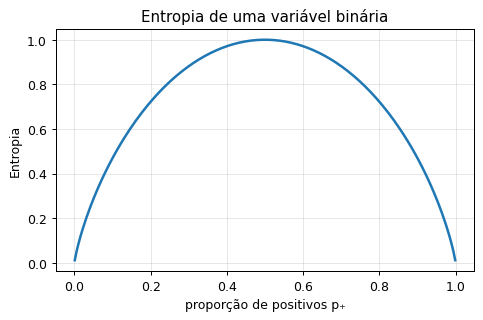

Entropia(S) do PlayTennis [9 Sim, 5 Não] = 0.940

  Ganho(S, Tempo       ) = 0.247  ████████████████████████
  Ganho(S, Umidade     ) = 0.152  ███████████████
  Ganho(S, Vento       ) = 0.048  ████
  Ganho(S, Temperatura ) = 0.029  ██

👉 "Tempo" tem o maior ganho → é a RAIZ da árvore (como no livro de Mitchell).


In [41]:
def entropia(rotulos):
    _, contagens = np.unique(rotulos, return_counts=True)
    p = contagens / contagens.sum()
    return -np.sum(p * np.log2(p))

def ganho_informacao(df, atributo, alvo):
    e_total = entropia(df[alvo])
    e_ponderada = sum(len(sub) / len(df) * entropia(sub[alvo]) for _, sub in df.groupby(atributo))
    return e_total - e_ponderada

# Curva da entropia
p = np.linspace(0.001, 0.999, 200)
plt.figure(figsize=(6, 3.5))
plt.plot(p, -p*np.log2(p) - (1-p)*np.log2(1-p), lw=2)
plt.xlabel('proporção de positivos p₊'); plt.ylabel('Entropia'); plt.title('Entropia de uma variável binária')
plt.show()

print(f'Entropia(S) do PlayTennis [9 Sim, 5 Não] = {entropia(tenis["Jogar"]):.3f}\n')
ganhos = {a: ganho_informacao(tenis, a, 'Jogar') for a in ['Tempo', 'Temperatura', 'Umidade', 'Vento']}
for a, g in sorted(ganhos.items(), key=lambda t: -t[1]):
    print(f'  Ganho(S, {a:<12}) = {g:.3f}  {"█" * int(g * 100)}')
print('\n👉 "Tempo" tem o maior ganho → é a RAIZ da árvore (como no livro de Mitchell).')

#### 🔎 Como interpretar o resultado

- **Gráfico da entropia:** vale **0** quando o conjunto é puro (p₊ = 0 ou 1) e é **máxima (1 bit)** quando p₊ = 0,5. Mede a **incerteza**: quantos bits, em média, seriam necessários para comunicar o rótulo de um exemplo sorteado.
- **Entropia(S) = 0,940:** com 9 Sim e 5 Não, a incerteza inicial é alta (quase 1).
- **Ganhos:**
  - **Tempo = 0,247 (o maior):** separar por Tempo cria o subconjunto **Nublado = 4 Sim, 0 Não**, que é **puro** (entropia 0). Isso reduz muito a incerteza.
  - **Umidade = 0,152:** Alta (3 Sim, 4 Não) e Normal (6 Sim, 1 Não) ficam razoavelmente separadas.
  - **Vento = 0,048** e **Temperatura = 0,029:** os subconjuntos continuam quase tão misturados quanto antes; perguntar sobre eles "informa" pouco.
- **💡 Conceito-chave:** o ganho de informação responde: *"quanto a incerteza sobre a classe diminui se eu souber o valor deste atributo?"*. O ID3 é **guloso**: em cada nó escolhe o atributo com maior ganho, sem olhar para os passos seguintes.

In [42]:
def id3(df, alvo, atributos, profundidade=0, log=None):
    # Constrói recursivamente uma árvore de decisão (dicionários aninhados).
    rotulos = df[alvo]
    if rotulos.nunique() == 1:                       # nó puro → folha
        return rotulos.iloc[0]
    if not atributos:                                 # sem atributos → classe majoritária
        return rotulos.mode()[0]
    ganhos = {a: ganho_informacao(df, a, alvo) for a in atributos}
    melhor = max(ganhos, key=ganhos.get)
    if log is not None:
        log.append(f'{"    " * profundidade}• nó com {len(df)} exemplos { {k: int(v) for k, v in rotulos.value_counts().items()} } '
                   f'→ melhor atributo: {melhor} (ganho {ganhos[melhor]:.3f})')
    arvore = {melhor: {}}
    for valor, sub in df.groupby(melhor):
        arvore[melhor][valor] = id3(sub, alvo, [a for a in atributos if a != melhor], profundidade + 1, log)
    return arvore

def imprimir_arvore(arv, indent=''):
    if not isinstance(arv, dict):
        print(indent + '→ ' + ('✅ ' if arv == 'Sim' else '❌ ') + arv)
        return
    atributo = next(iter(arv))
    for valor, sub in arv[atributo].items():
        print(f'{indent}[{atributo} = {valor}]')
        imprimir_arvore(sub, indent + '    ')

def classificar(arv, x):
    while isinstance(arv, dict):
        atributo = next(iter(arv))
        arv = arv[atributo][x[atributo]]
    return arv

passos = []
arvore_tenis = id3(tenis, 'Jogar', ['Tempo', 'Temperatura', 'Umidade', 'Vento'], log=passos)
print('🔨 Passos de construção do ID3:'); print('\n'.join(passos))
print('\n🌳 Árvore aprendida:'); imprimir_arvore(arvore_tenis)
print('\nDia novo', dia_novo, '→ Jogar =', classificar(arvore_tenis, dia_novo))

🔨 Passos de construção do ID3:
• nó com 14 exemplos {'Sim': 9, 'Não': 5} → melhor atributo: Tempo (ganho 0.247)
    • nó com 5 exemplos {'Sim': 3, 'Não': 2} → melhor atributo: Vento (ganho 0.971)
    • nó com 5 exemplos {'Não': 3, 'Sim': 2} → melhor atributo: Umidade (ganho 0.971)

🌳 Árvore aprendida:
[Tempo = Chuvoso]
    [Vento = Forte]
        → ❌ Não
    [Vento = Fraco]
        → ✅ Sim
[Tempo = Ensolarado]
    [Umidade = Alta]
        → ❌ Não
    [Umidade = Normal]
        → ✅ Sim
[Tempo = Nublado]
    → ✅ Sim

Dia novo {'Tempo': 'Ensolarado', 'Temperatura': 'Fria', 'Umidade': 'Alta', 'Vento': 'Forte'} → Jogar = Não


#### 🔎 Como interpretar o resultado

- **Passos de construção:**
  1. Na raiz (14 exemplos), o maior ganho é **Tempo**, e os dados são divididos em 3 ramos.
  2. **Nublado** (4 exemplos, todos Sim) é puro e vira uma **folha** imediatamente.
  3. **Chuvoso** (3 Sim, 2 Não): o melhor atributo é **Vento**, com ganho **0,971** (toda a entropia desse subconjunto). Separando por vento, os dois ramos ficam puros.
  4. **Ensolarado** (2 Sim, 3 Não): **Umidade** separa perfeitamente.
- **A árvore aprendida é idêntica à da Figura 3.1 do livro de Mitchell** e equivale a três regras:
  - SE Tempo = Nublado → Sim
  - SE Tempo = Ensolarado E Umidade = Normal → Sim
  - SE Tempo = Chuvoso E Vento = Fraco → Sim
  - caso contrário → Não
- **Repare que `Temperatura` nunca é usada!** O ID3 descobriu sozinho que ela é **irrelevante** para esta decisão. Árvores fazem **seleção de atributos** automaticamente.
- **Dia novo → Não:** o caminho é Ensolarado → Umidade Alta → **Não**, a mesma resposta do Naive Bayes, mas agora com uma **justificativa legível**.

**Viés indutivo do ID3:** prefere árvores **mais curtas** e com atributos de alto ganho perto da raiz — uma forma da **Navalha de Occam** (*"prefira a hipótese mais simples que se ajuste aos dados"*).

**Problemas práticos tratados por extensões (C4.5, CART):**
- *Overfitting* → **poda** (pré-poda: limitar profundidade; pós-poda: remover ramos que não melhoram a validação);
- Atributos contínuos → escolher limiares ($x \le t$);
- Valores ausentes e custos diferentes de atributos.

O scikit-learn implementa o **CART** (árvores binárias, critério **Gini** ou **entropia**).

#### 🎬 Animação: a árvore crescendo e particionando o espaço

In [43]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

fig, ax = plt.subplots(figsize=(7, 5))
profundidades = list(range(1, 11))
def quadro_arvore(d):
    ax.clear()
    m = DecisionTreeClassifier(max_depth=d, random_state=0).fit(Xm_tr, ym_tr)
    plot_fronteira(m, Xm_tr, ym_tr, ax=ax, resolucao=150,
                   titulo=f'max_depth = {d} | folhas = {m.get_n_leaves()} | '
                          f'treino = {m.score(Xm_tr, ym_tr):.0%} | teste = {m.score(Xm_te, ym_te):.0%}')
anim = animation.FuncAnimation(fig, quadro_arvore, frames=profundidades, interval=900)
mostrar_animacao(anim)

#### 🔎 Como interpretar a animação

- **Por que as fronteiras são "em escada"?** Cada nó da árvore faz uma pergunta do tipo `x₁ ≤ t` ou `x₂ ≤ t`, ou seja, corta o plano com uma linha **vertical ou horizontal**. A fronteira final é sempre formada por **retângulos** alinhados aos eixos.
- **Evolução:**
  - **Profundidade 1** (1 pergunta): um único corte; treino e teste ~84%.
  - **Profundidade 2–3:** a forma das luas começa a aparecer; teste ~87%.
  - **Profundidade 6–10:** surgem **retângulos minúsculos** em volta de pontos isolados; o treino chega a **100%**, mas o teste fica oscilando entre ~85% e ~88%, sem ganho consistente.
- **Como interpretar:** os retângulos pequenos são a árvore **decorando o ruído**. Em profundidade 10, cada folha tem pouquíssimos exemplos, e as decisões nessas folhas não são confiáveis.
- **💡 Por isso existe a poda:** limitar `max_depth`, exigir um mínimo de exemplos por folha (`min_samples_leaf`) ou podar a árvore depois de pronta são formas de controlar a complexidade, o mesmo papel do grau do polinômio ou do *k* do KNN.

Acurácia no teste: 95.6%


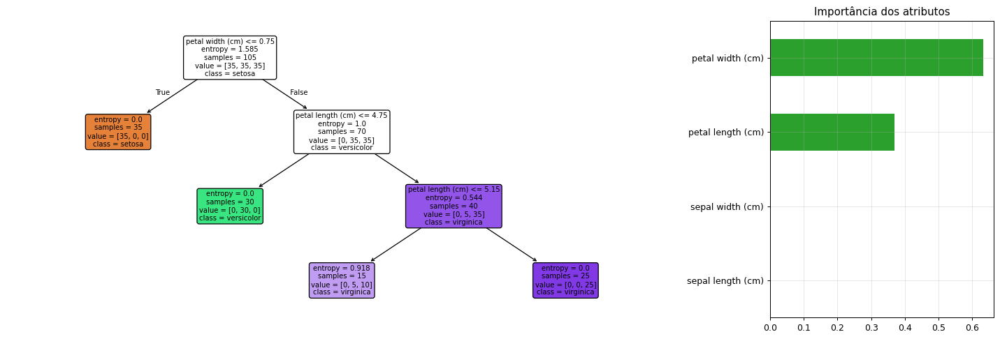

|--- petal width (cm) <= 0.75
|   |--- class: 0
|--- petal width (cm) >  0.75
|   |--- petal length (cm) <= 4.75
|   |   |--- class: 1
|   |--- petal length (cm) >  4.75
|   |   |--- petal length (cm) <= 5.15
|   |   |   |--- class: 2
|   |   |--- petal length (cm) >  5.15
|   |   |   |--- class: 2



In [44]:
# Árvore do scikit-learn no Iris completo (4 atributos), com visualização
Xi4_tr, Xi4_te, yi4_tr, yi4_te = train_test_split(iris.data, iris.target, test_size=0.3, random_state=1, stratify=iris.target)
arv_iris = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=0).fit(Xi4_tr, yi4_tr)
print(f'Acurácia no teste: {arv_iris.score(Xi4_te, yi4_te):.1%}')

fig, axs = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [3, 1]})
plot_tree(arv_iris, feature_names=iris.feature_names, class_names=iris.target_names,
          filled=True, rounded=True, fontsize=8, ax=axs[0])
pd.Series(arv_iris.feature_importances_, index=iris.feature_names).sort_values().plot.barh(ax=axs[1], color=CORES[2])
axs[1].set_title('Importância dos atributos')
plt.tight_layout(); plt.show()

from sklearn.tree import export_text
print(export_text(arv_iris, feature_names=list(iris.feature_names)))

#### 🔎 Como ler a árvore desenhada

Cada caixa (nó) mostra:
- **a pergunta** (ex.: `petal width (cm) <= 0.75`). Se a resposta for **verdadeira**, siga para a **esquerda**; se for falsa, para a **direita**;
- **entropy:** a impureza do nó (0 = puro);
- **samples:** quantos exemplos de treino chegaram ali;
- **value:** quantos exemplos de cada classe;
- **class + cor:** a classe majoritária. Quanto mais **intensa** a cor, mais puro é o nó.

**Interpretação:**
- A **1ª pergunta** (largura da pétala ≤ 0,75 cm) isola **todas** as *setosas* em um nó puro: elas são muito diferentes das outras espécies.
- As perguntas seguintes separam *versicolor* de *virginica*, que é a parte difícil.
- **Importância dos atributos:** só as **pétalas** foram usadas (largura ~63% e comprimento ~37%). As sépalas têm importância **zero** nesta árvore: o modelo descobriu quais medidas importam.
- **Texto (`export_text`):** a mesma árvore em formato de regras. Repare que o último nó divide em `class: 2` e `class: 2`, ou seja, os dois lados preveem a mesma classe. A divisão melhora a **pureza** (a proporção de classes), mas não muda a decisão final, um detalhe comum no CART.

---
## Parte 10 — SVM e métodos de *ensemble*

### 10.1 Máquinas de Vetores de Suporte (SVM)

Entre todas as retas que separam duas classes, qual é a **melhor**? A SVM (Cortes & Vapnik, 1995) escolhe a de **maior margem** — a maior "faixa" vazia entre as classes. Os pontos que tocam a margem são os **vetores de suporte**.

- **C** (regularização): C grande → margem estreita, poucos erros no treino (risco de *overfitting*); C pequeno → margem larga, tolera erros.
- **Truque do kernel:** projeta os dados implicitamente em um espaço de mais dimensões, onde eles se tornam separáveis. Kernels comuns: linear, polinomial, **RBF** (gaussiano). O parâmetro **γ** do RBF controla o "alcance" de cada exemplo.

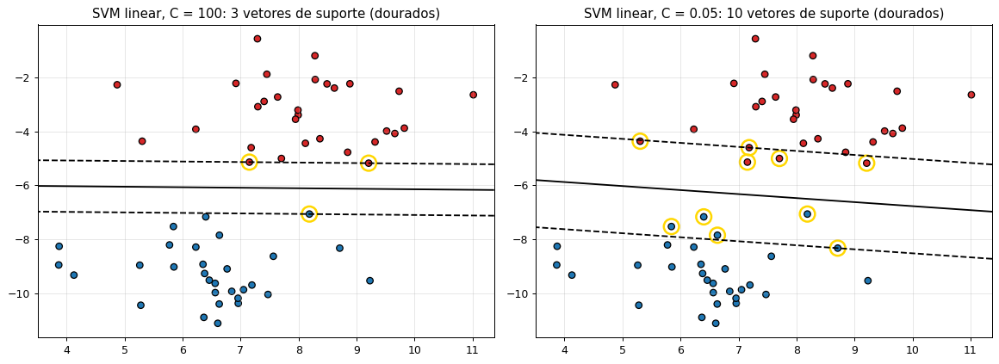

In [45]:
from sklearn.svm import SVC

Xs, ys = make_blobs(n_samples=60, centers=2, random_state=6, cluster_std=1.2)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, C in zip(axs, [100, 0.05]):
    svm = SVC(kernel='linear', C=C).fit(Xs, ys)
    ax.scatter(Xs[:, 0], Xs[:, 1], c=ys, cmap=ListedColormap([CORES[1], CORES[0]]), edgecolor='k')
    xx, yy = np.meshgrid(np.linspace(*ax.get_xlim(), 100), np.linspace(*ax.get_ylim(), 100))
    Z = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors='k', linestyles=['--', '-', '--'])
    ax.scatter(*svm.support_vectors_.T, s=200, facecolors='none', edgecolors='gold', linewidths=2)
    ax.set_title(f'SVM linear, C = {C}: {len(svm.support_vectors_)} vetores de suporte (dourados)')
plt.tight_layout(); plt.show()

#### 🔎 Como interpretar a figura

- **Linha contínua:** a fronteira de decisão. **Linhas tracejadas:** as bordas da **margem**. **Círculos dourados:** os **vetores de suporte**, os pontos que ficam na margem ou dentro dela.
- **C = 100 (esquerda):** apenas **3 vetores de suporte** e margem **estreita**. A SVM quase não tolera pontos dentro da margem, então a fronteira é definida pelos pontos mais "difíceis".
- **C = 0,05 (direita):** **10 vetores de suporte** e margem **larga**. A SVM aceita alguns pontos dentro da margem em troca de uma faixa mais larga, o que costuma **generalizar melhor** quando há ruído.
- **Por que só os vetores de suporte importam?** Se você apagar qualquer ponto que **não** está circulado e treinar de novo, a fronteira **não muda**. A solução depende só dos pontos críticos. Isso torna a SVM robusta e eficiente.
- **💡 Comparação com o Perceptron:** o Perceptron para na **primeira** reta que separa os dados; a SVM escolhe a reta **mais distante** dos dois grupos. Intuitivamente, uma reta com mais "folga" tem menos chance de errar pontos novos.

In [46]:
# 🎛️ INTERATIVO — SVM com kernel RBF em dados não lineares
from sklearn.datasets import make_circles
Xc, yc = make_circles(n_samples=200, factor=0.4, noise=0.12, random_state=0)

def svm_rbf(log_C=0.0, log_gamma=0.0):
    C, g = 10 ** log_C, 10 ** log_gamma
    m = SVC(kernel='rbf', C=C, gamma=g).fit(Xc, yc)
    fig, ax = plt.subplots(figsize=(6.5, 5))
    plot_fronteira(m, Xc, yc, ax=ax, titulo=f'RBF: C = {C:.2g}, γ = {g:.2g} | acurácia treino = {m.score(Xc, yc):.0%}')
    plt.show()

interact(svm_rbf, log_C=widgets.FloatSlider(min=-2, max=3, step=0.5, value=0, description='log₁₀ C'),
         log_gamma=widgets.FloatSlider(min=-2, max=2, step=0.5, value=0, description='log₁₀ γ'));

interactive(children=(FloatSlider(value=0.0, description='log₁₀ C', max=3.0, min=-2.0, step=0.5), FloatSlider(…

#### 🔎 Como usar e interpretar

- **O problema:** os dados formam **dois círculos concêntricos**. Nenhuma reta separa um círculo de dentro de um círculo de fora.
- **Truque do kernel:** o kernel RBF mede a **similaridade** entre pontos, `K(a,b) = exp(−γ‖a−b‖²)`, o que equivale a projetar os dados em um espaço de dimensão (infinita) onde eles se tornam separáveis. Na prática, a fronteira resultante no plano é uma **curva fechada**.
- **Experimente:**
  - **γ pequeno (log₁₀ γ = −2):** cada exemplo influencia uma área **grande**; a fronteira fica **suave**, às vezes simples demais.
  - **γ grande (log₁₀ γ = +2):** cada exemplo influencia só sua **vizinhança imediata**; aparecem "bolhas" em volta de pontos individuais. A acurácia de treino chega a 100%, mas é *overfitting*.
  - **C grande:** tenta acertar **todos** os pontos de treino. **C pequeno:** aceita erros em troca de uma fronteira mais simples.
- **💡 Conceito-chave:** **C e γ** juntos controlam a complexidade da SVM. Como interagem entre si, costumam ser escolhidos juntos por *Grid Search* (Seção 11.4).

### 10.2 *Ensembles*: a sabedoria das multidões

Combinar vários modelos "fracos" costuma produzir um modelo **forte**:

| Método | Ideia | Exemplo |
|---|---|---|
| **Bagging** | Treina vários modelos em amostras *bootstrap* (com reposição) e vota | **Random Forest** (Breiman, 2001) |
| **Boosting** | Treina modelos em sequência; cada um foca nos erros do anterior | AdaBoost, Gradient Boosting, XGBoost |
| **Stacking** | Um meta-modelo aprende a combinar as saídas de outros modelos | — |

A **Random Forest** treina muitas árvores, cada uma com uma amostra *bootstrap* e um subconjunto aleatório de atributos em cada divisão, reduzindo a **variância** de uma árvore isolada.

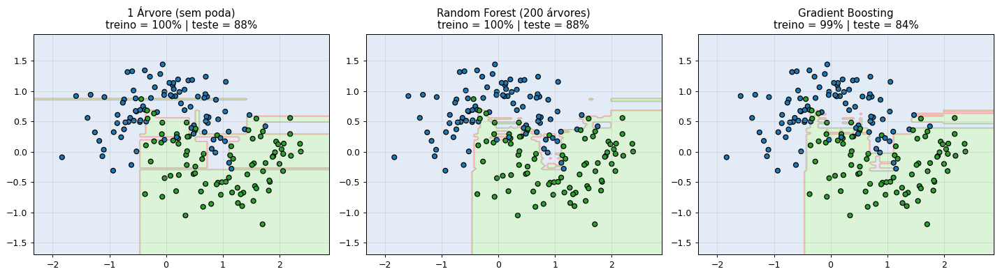

In [47]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

modelos_cmp = {
    '1 Árvore (sem poda)': DecisionTreeClassifier(random_state=0),
    'Random Forest (200 árvores)': RandomForestClassifier(n_estimators=200, random_state=0),
    'Gradient Boosting': GradientBoostingClassifier(random_state=0),
}
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (nome, m) in zip(axs, modelos_cmp.items()):
    m.fit(Xm_tr, ym_tr)
    plot_fronteira(m, Xm_tr, ym_tr, ax=ax, resolucao=150,
                   titulo=f'{nome}\ntreino = {m.score(Xm_tr, ym_tr):.0%} | teste = {m.score(Xm_te, ym_te):.0%}')
plt.tight_layout(); plt.show()

#### 🔎 Como interpretar a figura

| Modelo | Treino | Teste | Fronteira |
|---|---|---|---|
| 1 árvore sem poda | 100% | ~88% | Retângulos pequenos e "ilhas" em volta de pontos isolados |
| Random Forest | 100% | ~88% | Mais suave e com bordas mais "arredondadas": é a **média** de 200 árvores |
| Gradient Boosting | ~99% | ~84% | Formada por muitas árvores pequenas somadas em sequência |

- **Por que a Random Forest também tem 100% no treino?** Cada árvore da floresta é profunda e decora sua amostra. O ganho do *ensemble* aparece na **estabilidade**: se você trocar a semente ou os dados, a fronteira da floresta muda muito menos que a de uma árvore isolada (menor **variância**).
- **⚠️ Por que o teste não melhorou aqui?** Com apenas **75 pontos de teste**, cada ponto vale ~1,3 ponto percentual. Diferenças de 1–3 pontos podem ser **puro acaso**. Para comparar modelos de forma confiável, usamos **validação cruzada** (Parte 11), em que a Random Forest normalmente se mostra mais estável que uma árvore isolada.
- **💡 Lição importante:** nunca conclua que "o modelo A é melhor que o B" a partir de uma única divisão treino/teste pequena.

In [48]:
# 🎬 ANIMAÇÃO — Random Forest com cada vez mais árvores (a fronteira "suaviza")
fig, ax = plt.subplots(figsize=(7, 5))
n_arvores = [1, 2, 3, 5, 10, 20, 50, 100]
def quadro_rf(n):
    ax.clear()
    m = RandomForestClassifier(n_estimators=n, random_state=0).fit(Xm_tr, ym_tr)
    plot_fronteira(m, Xm_tr, ym_tr, ax=ax, resolucao=120,
                   titulo=f'Random Forest com {n} árvore(s) | teste = {m.score(Xm_te, ym_te):.0%}')
anim = animation.FuncAnimation(fig, quadro_rf, frames=n_arvores, interval=900)
mostrar_animacao(anim)

#### 🔎 Como interpretar a animação

- **1 árvore:** a fronteira é "quadrada" e cheia de recortes, típica de uma única árvore.
- **5 → 20 árvores:** os recortes isolados começam a **desaparecer**. Um recorte criado por uma árvore por causa de um ponto ruidoso é "votado contra" pelas outras árvores, que não viram aquele ponto (amostras *bootstrap* diferentes).
- **50 → 100 árvores:** a fronteira **estabiliza**: adicionar mais árvores quase não muda mais nada (teste ~87%).
- **Por que funciona?** Se várias árvores cometem erros **diferentes e pouco correlacionados**, a média dos votos cancela boa parte desses erros. É a **sabedoria das multidões**: a aleatoriedade (*bootstrap* + subconjunto aleatório de atributos) serve justamente para tornar as árvores **diferentes entre si**.
- **💡 Dica prática:** mais árvores **nunca pioram** a Random Forest (não causam *overfitting*); só aumentam o tempo de processamento. Por isso, 100–500 árvores é um valor comum.

---
## Parte 11 — Avaliação de modelos (Mitchell, Cap. 5)

### 11.1 Matriz de confusão e métricas

Para um problema binário (ex.: **doente = positivo**):

|  | **Previsto: Positivo** | **Previsto: Negativo** |
|---|:-:|:-:|
| **Real: Positivo** | VP (Verdadeiro Positivo) | FN (Falso Negativo) ⚠️ |
| **Real: Negativo** | FP (Falso Positivo) | VN (Verdadeiro Negativo) |

| Métrica | Fórmula | Pergunta que responde |
|---|---|---|
| **Acurácia** | $\frac{VP+VN}{VP+VN+FP+FN}$ | Quantos acertos no total? |
| **Precisão** | $\frac{VP}{VP+FP}$ | Dos que eu disse "positivo", quantos eram? |
| **Revocação** (*recall*, sensibilidade) | $\frac{VP}{VP+FN}$ | Dos positivos reais, quantos eu encontrei? |
| **F1-score** | $2\cdot\frac{\text{prec}\cdot\text{rev}}{\text{prec}+\text{rev}}$ | Média harmônica de precisão e revocação |
| **Especificidade** | $\frac{VN}{VN+FP}$ | Dos negativos reais, quantos eu acertei? |

> ⚠️ **A armadilha da acurácia:** em uma doença rara (1% de casos), um modelo que diz **sempre "saudável"** tem **99% de acurácia** — e é inútil!

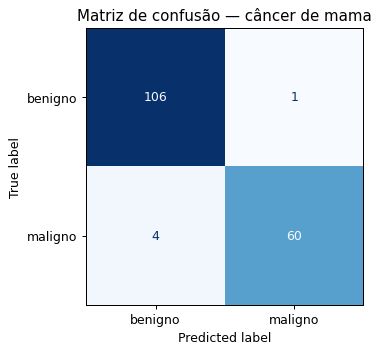

Acurácia : 0.971
Precisão : 0.984
Revocação: 0.938   ← crucial em medicina: não deixar passar tumores malignos
F1-score : 0.960

              precision    recall  f1-score   support

     benigno       0.96      0.99      0.98       107
     maligno       0.98      0.94      0.96        64

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171

Modelo "sempre negativo" em doença rara → acurácia = 99.0%, revocação = 0% 😱


In [49]:
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, precision_score, recall_score, f1_score)

cancer = load_breast_cancer()
# No dataset, 0 = maligno e 1 = benigno. Invertemos para que POSITIVO = maligno (o caso de interesse).
Xc_, yc_ = cancer.data, 1 - cancer.target
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc_, yc_, test_size=0.3, random_state=42, stratify=yc_)

clf_cancer = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xc_tr, yc_tr)
yc_pred = clf_cancer.predict(Xc_te)

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(yc_te, yc_pred), display_labels=['benigno', 'maligno']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Matriz de confusão — câncer de mama'); ax.grid(False)
plt.show()

print(f'Acurácia : {accuracy_score(yc_te, yc_pred):.3f}')
print(f'Precisão : {precision_score(yc_te, yc_pred):.3f}')
print(f'Revocação: {recall_score(yc_te, yc_pred):.3f}   ← crucial em medicina: não deixar passar tumores malignos')
print(f'F1-score : {f1_score(yc_te, yc_pred):.3f}\n')
print(classification_report(yc_te, yc_pred, target_names=['benigno', 'maligno']))

# A armadilha da acurácia
y_raro = np.r_[np.ones(10), np.zeros(990)]
print(f'Modelo "sempre negativo" em doença rara → acurácia = {accuracy_score(y_raro, np.zeros(1000)):.1%}, '
      f'revocação = {recall_score(y_raro, np.zeros(1000)):.0%} 😱')

#### 🔎 Como interpretar o resultado

- **Matriz de confusão** (linhas = classe real, colunas = classe prevista):
  - **106** benignos corretamente identificados (VN) e **60** malignos corretamente identificados (VP);
  - **1** benigno classificado como maligno (**FP**): um susto, seguido de exames extras;
  - **4** malignos classificados como benignos (**FN**): **o erro mais grave**, pois são tumores que passariam despercebidos.
- **Métricas:**
  - **Acurácia 97,1%:** acertou 166 de 171 casos;
  - **Precisão 98,4%:** dos 61 casos que o modelo chamou de malignos, 60 eram mesmo;
  - **Revocação 93,8%:** dos 64 tumores malignos reais, o modelo encontrou 60 (e perdeu 4);
  - **F1 96,0%:** a média harmônica entre precisão e revocação.
- **Como ler o `classification_report`:** cada linha mostra as métricas **considerando aquela classe como positiva**. `support` é quantos exemplos reais existem de cada classe. *macro avg* é a média simples entre classes; *weighted avg* é ponderada pelo `support`.
- **A armadilha da acurácia (última linha):** um "modelo" que diz **sempre negativo** teria **99% de acurácia** numa doença com 1% de prevalência, mas **revocação 0%**: não detecta nenhum doente. **Com classes desbalanceadas, a acurácia sozinha engana.**
- **💡 Escolhendo a métrica:** em triagem médica priorizamos a **revocação** (não perder doentes); em um filtro de spam, a **precisão** (não bloquear e-mails legítimos).

### 11.2 Limiar de decisão, curva ROC e AUC

Classificadores probabilísticos produzem um *score*. Mudando o **limiar** (padrão: 0,5) trocamos precisão por revocação.
A **curva ROC** mostra a Taxa de Verdadeiros Positivos (revocação) × Taxa de Falsos Positivos para **todos** os limiares. A **AUC** (área sob a curva) resume: 1,0 = perfeito; 0,5 = aleatório.

In [50]:
# 🎬 ANIMAÇÃO — varrendo o limiar de decisão e percorrendo a curva ROC
from sklearn.metrics import roc_curve, roc_auc_score

scores = clf_cancer.predict_proba(Xc_te)[:, 1]
fpr, tpr, _ = roc_curve(yc_te, scores)
auc = roc_auc_score(yc_te, scores)
limiares = np.linspace(0.99, 0.01, 40)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
bins = np.linspace(0, 1, 30)
def quadro_roc(i):
    t = limiares[i]
    ax1.clear()
    ax1.hist(scores[yc_te == 0], bins=bins, alpha=0.6, label='benigno (neg.)', color=CORES[0])
    ax1.hist(scores[yc_te == 1], bins=bins, alpha=0.6, label='maligno (pos.)', color=CORES[1])
    ax1.axvline(t, color='k', lw=2, ls='--')
    pred = scores >= t
    vp = np.sum(pred & (yc_te == 1)); fp = np.sum(pred & (yc_te == 0))
    fn = np.sum(~pred & (yc_te == 1)); vn = np.sum(~pred & (yc_te == 0))
    ax1.set_title(f'limiar = {t:.2f} | VP={vp} FP={fp} FN={fn} VN={vn}')
    ax1.set_xlabel('P(maligno)'); ax1.legend(loc='upper center')
    ax2.clear()
    ax2.plot(fpr, tpr, color='gray', lw=1)
    ax2.plot([0, 1], [0, 1], 'k:', label='aleatório (AUC = 0,5)')
    ax2.scatter(fp / (fp + vn), vp / (vp + fn), s=120, color=CORES[3], zorder=3)
    ax2.set_xlabel('Taxa de Falsos Positivos'); ax2.set_ylabel('Taxa de Verdadeiros Positivos (revocação)')
    ax2.set_title(f'Curva ROC (AUC = {auc:.3f})'); ax2.legend(loc='lower right')
anim = animation.FuncAnimation(fig, quadro_roc, frames=len(limiares), interval=180)
mostrar_animacao(anim)

#### 🔎 Como interpretar a animação

- **Esquerda, histogramas:** a distribuição das probabilidades previstas P(maligno). Benignos (azul) concentram-se perto de 0 e malignos (vermelho) perto de 1. A linha tracejada é o **limiar**: tudo à direita dela é classificado como maligno.
- **O que acontece ao mover o limiar de 0,99 para 0,01:**
  - **Limiar alto (0,99):** o modelo só diz "maligno" quando tem muita certeza, então **poucos FP**, mas **muitos FN** (alta precisão, baixa revocação). O ponto laranja fica no canto **inferior esquerdo** da ROC.
  - **Limiar baixo (0,01):** qualquer suspeita vira "maligno", então **FN quase zero**, mas FP aumenta (alta revocação, menor precisão). O ponto vai para o canto **superior direito**.
- **Direita, curva ROC:** é o caminho percorrido pelo ponto laranja. Uma curva colada no **canto superior esquerdo** significa que existe um limiar com quase 100% de revocação e quase 0% de falsos positivos.
- **AUC = 0,998:** quase perfeito. Interpretação probabilística: se sortearmos um tumor maligno e um benigno, o modelo atribui uma probabilidade maior ao maligno em **99,8%** das vezes. A linha pontilhada (AUC = 0,5) é um classificador aleatório.
- **💡 Conceito-chave:** o modelo produz **scores**; o **limiar** é uma decisão de **negócio**, que depende do custo de cada tipo de erro. Os histogramas pouco sobrepostos explicam por que este modelo funciona tão bem: as duas classes recebem scores muito diferentes.

### 11.3 Validação cruzada *k-fold*

Uma única divisão treino/teste pode dar sorte (ou azar). Na **validação cruzada k-fold**, dividimos os dados em $k$ partes; treinamos $k$ vezes, cada vez usando uma parte diferente como teste, e tiramos a **média**.

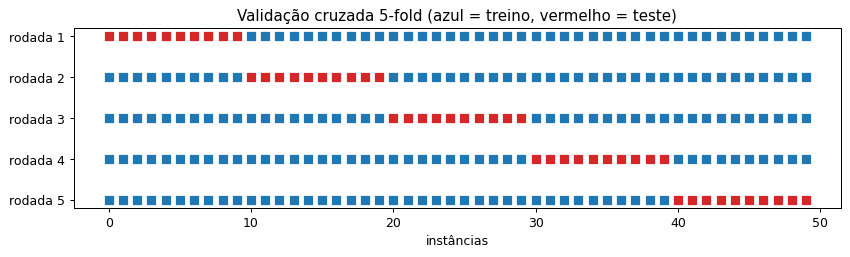

KNN (k=5)              F1 = 0.952 ± 0.014   [0.953 0.94  0.976 0.937 0.953]
Árvore (prof. 4)       F1 = 0.886 ± 0.024   [0.897 0.843 0.914 0.9   0.876]
Regressão logística    F1 = 0.974 ± 0.009   [0.977 0.976 0.963 0.964 0.988]
Random Forest          F1 = 0.945 ± 0.025   [0.907 0.927 0.976 0.951 0.965]
SVM (RBF)              F1 = 0.964 ± 0.020   [0.966 0.94  1.    0.951 0.965]


In [51]:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=False)
fig, ax = plt.subplots(figsize=(11, 2.6))
for i, (tr, te) in enumerate(kf.split(np.arange(50))):
    ax.scatter(tr, [i] * len(tr), marker='s', s=40, color=CORES[0])
    ax.scatter(te, [i] * len(te), marker='s', s=40, color=CORES[1])
ax.set_yticks(range(5)); ax.set_yticklabels([f'rodada {i+1}' for i in range(5)])
ax.set_xlabel('instâncias'); ax.invert_yaxis(); ax.grid(False)
ax.set_title('Validação cruzada 5-fold (azul = treino, vermelho = teste)')
plt.show()

for nome, m in {'KNN (k=5)': make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
                'Árvore (prof. 4)': DecisionTreeClassifier(max_depth=4, random_state=0),
                'Regressão logística': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
                'Random Forest': RandomForestClassifier(n_estimators=200, random_state=0),
                'SVM (RBF)': make_pipeline(StandardScaler(), SVC())}.items():
    s = cross_val_score(m, Xc_, yc_, cv=5, scoring='f1')
    print(f'{nome:<22} F1 = {s.mean():.3f} ± {s.std():.3f}   {np.round(s, 3)}')

#### 🔎 Como interpretar o resultado

- **Figura:** em cada rodada, um bloco diferente (vermelho) é usado como teste e o resto (azul) como treino. Ao final, **todo exemplo foi usado como teste exatamente uma vez**.
- **Resultados (F1 em 5 folds):**

| Modelo | F1 médio | ± desvio | Leitura |
|---|---|---|---|
| Regressão logística | **0,974** | 0,009 | Melhor **e** mais estável |
| SVM (RBF) | 0,964 | 0,020 | Muito boa |
| KNN | 0,952 | 0,014 | Boa (com padronização!) |
| Random Forest | 0,945 | 0,025 | Boa, porém mais variável |
| Árvore (prof. 4) | 0,886 | 0,024 | A mais fraca |

- **Como ler o "±":** é o desvio-padrão entre os 5 folds. Repare que a SVM variou de **0,94 a 1,00** dependendo da divisão: uma única divisão treino/teste poderia ter dado qualquer um desses valores. A média de 5 rodadas é uma estimativa **muito mais confiável**.
- **Por que um modelo simples (logística) venceu?** Este conjunto tem 30 atributos numéricos e classes **quase linearmente separáveis**. Quando a fronteira real é aproximadamente linear, modelos complexos não têm vantagem, só mais variância. **Sempre teste um *baseline* simples!**
- **Diferenças menores que o desvio** (ex.: 0,964 × 0,952) não devem ser consideradas conclusivas.

### 11.4 Ajuste de hiperparâmetros (*Grid Search*)

**Parâmetros** são aprendidos no treino (pesos $\theta$). **Hiperparâmetros** são escolhidos **antes** do treino ($k$ do KNN, profundidade da árvore, $C$ da SVM). O `GridSearchCV` testa todas as combinações com validação cruzada.

Melhores hiperparâmetros: {'svc__C': 10, 'svc__gamma': 0.01}
F1 médio na validação cruzada: 0.956
F1 no conjunto de teste      : 0.968


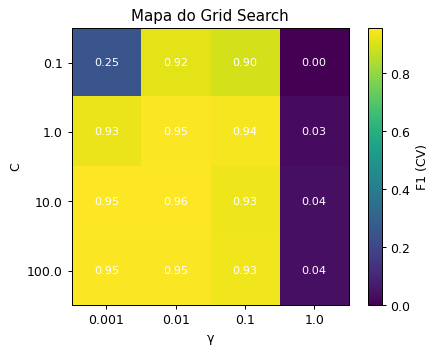

In [52]:
from sklearn.model_selection import GridSearchCV

grade = {'svc__C': [0.1, 1, 10, 100], 'svc__gamma': [0.001, 0.01, 0.1, 1]}
busca = GridSearchCV(make_pipeline(StandardScaler(), SVC()), grade, cv=5, scoring='f1').fit(Xc_tr, yc_tr)
print('Melhores hiperparâmetros:', busca.best_params_)
print(f'F1 médio na validação cruzada: {busca.best_score_:.3f}')
print(f'F1 no conjunto de teste      : {f1_score(yc_te, busca.predict(Xc_te)):.3f}')

res = pd.DataFrame(busca.cv_results_).pivot_table(index='param_svc__C', columns='param_svc__gamma', values='mean_test_score')
fig, ax = plt.subplots(figsize=(5.5, 4))
im = ax.imshow(res.values, cmap='viridis'); plt.colorbar(im, label='F1 (CV)')
ax.set_xticks(range(4)); ax.set_xticklabels(res.columns); ax.set_yticks(range(4)); ax.set_yticklabels(res.index)
ax.set_xlabel('γ'); ax.set_ylabel('C'); ax.set_title('Mapa do Grid Search'); ax.grid(False)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{res.values[i, j]:.2f}', ha='center', va='center', color='w', fontsize=9)
plt.show()

#### 🔎 Como interpretar o resultado

- **O que foi feito:** 4 valores de C × 4 valores de γ = **16 combinações**, cada uma avaliada com validação cruzada de 5 folds (**80 treinos**). Tudo isso **só com os dados de treino**.
- **Mapa de calor:** cada célula é o F1 médio de uma combinação.
  - **Coluna γ = 1 (direita):** F1 próximo de **0** para qualquer C. Com γ grande, cada ponto só "enxerga" a si mesmo (com 30 atributos padronizados, as distâncias entre pacientes são grandes). Pacientes novos não se parecem com nenhum exemplo de treino, e o modelo acaba prevendo quase sempre a classe majoritária (benigno), sem detectar os malignos.
  - **Canto C = 0,1, γ = 0,001 (F1 ≈ 0,25):** o extremo oposto. Modelo simples demais **e** muito regularizado: *underfitting*.
  - **Região amarela (γ = 0,001 a 0,1 com C ≥ 1):** F1 ≈ 0,93–0,96, a zona de bons hiperparâmetros.
- **Melhor combinação:** C = 10, γ = 0,01, com F1 de **0,956 na CV** e **0,968 no teste**. Os dois valores são próximos, o que indica que a estimativa da validação cruzada era **confiável** e que não houve *overfitting* na escolha dos hiperparâmetros.
- **💡 Por que não escolher os hiperparâmetros pelo teste?** Testar 16 combinações no conjunto de teste e escolher a melhor seria "treinar" no teste, e a avaliação final ficaria otimista. O teste deve ser usado **uma única vez**, no final.

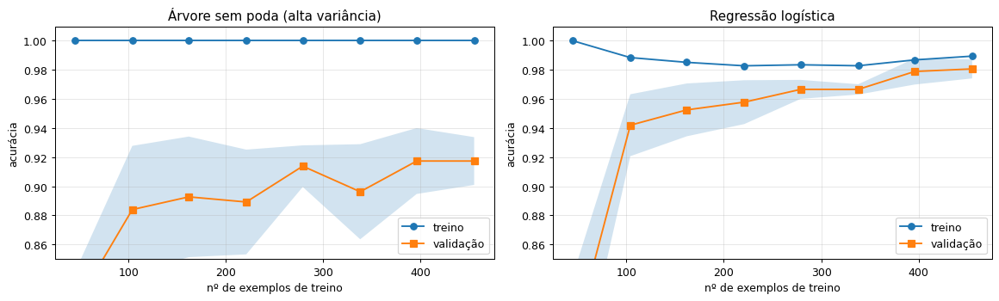

In [53]:
# Curva de aprendizado: desempenho × tamanho do treino (de novo, Mitchell: P melhora com E!)
from sklearn.model_selection import learning_curve

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, (nome, m) in zip(axs, [('Árvore sem poda (alta variância)', DecisionTreeClassifier(random_state=0)),
                               ('Regressão logística', make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)))]):
    tam, s_tr, s_val = learning_curve(m, Xc_, yc_, cv=5, train_sizes=np.linspace(0.1, 1, 8), random_state=0)
    ax.plot(tam, s_tr.mean(1), 'o-', label='treino'); ax.plot(tam, s_val.mean(1), 's-', label='validação')
    ax.fill_between(tam, s_val.mean(1) - s_val.std(1), s_val.mean(1) + s_val.std(1), alpha=0.2)
    ax.set_ylim(0.85, 1.01); ax.set_xlabel('nº de exemplos de treino'); ax.set_ylabel('acurácia')
    ax.set_title(nome); ax.legend()
plt.tight_layout(); plt.show()

#### 🔎 Como interpretar as curvas de aprendizado

**Esquerda, árvore sem poda (alta variância):**
- A acurácia de **treino fica em 100%** para qualquer tamanho: a árvore sempre consegue decorar os dados.
- A acurácia de **validação é bem menor** e sobe devagar. A **grande distância** entre as curvas é a assinatura do ***overfitting***.
- **Diagnóstico:** mais dados ajudariam (a curva ainda sobe). Podar a árvore ou usar uma Random Forest também.

**Direita, regressão logística:**
- Com poucos exemplos, a validação é baixa (~79%); a partir de ~100 exemplos, treino e validação ficam **próximos** e altos (~98%).
- **Diagnóstico:** o modelo está bem ajustado. Mais dados trariam pouco ganho, pois as curvas já estão quase se encontrando.

| Padrão nas curvas | Diagnóstico | Ação |
|---|---|---|
| Treino alto, validação baixa, **distância grande** | Alta variância (*overfitting*) | Mais dados, regularização, modelo mais simples |
| Treino e validação **baixos e próximos** | Alto viés (*underfitting*) | Modelo mais complexo, atributos melhores |
| Treino e validação **altos e próximos** | Bom ajuste | 🎉 |

- **💡 Ligação com Mitchell:** de novo vemos **P melhorando com E**. Agora a curva também mostra **quanto** cada modelo ainda pode melhorar com mais experiência.

---
## Parte 12 — Aprendizado não supervisionado

Agora **não há rótulos**. O objetivo é descobrir **estrutura** nos dados: grupos (*clustering*), direções principais (redução de dimensionalidade), anomalias.

### 12.1 K-Means (Lloyd, 1957/1982)

```
1. Escolha k centróides iniciais (aleatoriamente)
2. Repita até não mudar:
     a) ATRIBUIÇÃO: cada ponto vai para o centróide mais próximo
     b) ATUALIZAÇÃO: cada centróide vai para a média dos seus pontos
```

O K-Means minimiza a **inércia** (soma das distâncias quadradas de cada ponto ao seu centróide):

$$J = \sum_{i=1}^{m} \lVert \mathbf{x}^{(i)} - \boldsymbol{\mu}_{c^{(i)}} \rVert^2$$

In [54]:
class KMeans_do_zero:
    def __init__(self, k=3, max_iter=20, semente=0):
        self.k, self.max_iter, self.semente = k, max_iter, semente

    def fit(self, X):
        rng = np.random.default_rng(self.semente)
        self.centroides = X[rng.choice(len(X), self.k, replace=False)].astype(float)
        self.historico = []
        for _ in range(self.max_iter):
            # (a) atribuição
            dist = np.linalg.norm(X[:, None, :] - self.centroides[None, :, :], axis=2)
            rotulos = dist.argmin(axis=1)
            self.historico.append((self.centroides.copy(), rotulos.copy()))
            # (b) atualização
            novos = np.array([X[rotulos == j].mean(axis=0) if np.any(rotulos == j) else self.centroides[j]
                              for j in range(self.k)])
            if np.allclose(novos, self.centroides):
                break
            self.centroides = novos
        self.rotulos_ = rotulos
        self.inercia_ = np.sum((X - self.centroides[rotulos]) ** 2)
        return self


Xk, yk_real = make_blobs(n_samples=300, centers=4, cluster_std=0.9, random_state=3)
km = KMeans_do_zero(k=4, semente=5).fit(Xk)
print(f'Convergiu em {len(km.historico)} iterações. Inércia final = {km.inercia_:.1f}')

Convergiu em 6 iterações. Inércia final = 503.3


#### 🔎 Como interpretar o resultado

- **Convergiu em 6 iterações:** depois disso, nenhum ponto mudou de grupo e os centróides pararam de se mover. O K-Means **sempre converge**, porque cada passo (atribuir e atualizar) **nunca aumenta** a inércia.
- **Inércia = 503,3:** a soma das distâncias ao quadrado de cada ponto até o seu centróide. **Quanto menor, mais compactos os grupos.** Sozinho, o número não diz muito; ele é útil para **comparar** soluções (por exemplo, diferentes valores de k no método do cotovelo).
- **⚠️ Mínimos locais:** o K-Means garante convergência, mas **não** garante a melhor solução. O resultado depende dos centróides iniciais sorteados. Por isso o `KMeans` do scikit-learn roda várias vezes (`n_init=10`) e usa a inicialização **k-means++**, que espalha os centróides iniciais.

In [55]:
# 🎬 ANIMAÇÃO — K-Means: atribuição e atualização dos centróides
fig, ax = plt.subplots(figsize=(7, 5.5))
cmap_k = ListedColormap(CORES[:4])
quadros_km = [(i, fase) for i in range(len(km.historico)) for fase in (0, 1)]

def quadro_km(q):
    i, fase = q
    cent, rot = km.historico[i]
    ax.clear()
    if i == 0 and fase == 0:
        ax.scatter(Xk[:, 0], Xk[:, 1], c='lightgray', edgecolor='k', s=20)
        titulo = 'Iteração 0: centróides iniciais aleatórios'
    else:
        ax.scatter(Xk[:, 0], Xk[:, 1], c=rot, cmap=cmap_k, edgecolor='k', s=20, vmin=0, vmax=3)
        titulo = f'Iteração {i}: ' + ('ATRIBUIÇÃO (pontos → centróide mais próximo)' if fase == 0
                                       else 'ATUALIZAÇÃO (centróide → média do grupo)')
    if fase == 1 and i + 1 < len(km.historico):
        prox = km.historico[i + 1][0]
        for c0, c1 in zip(cent, prox):
            ax.annotate('', xy=c1, xytext=c0, arrowprops=dict(arrowstyle='->', lw=2))
        cent = prox
    ax.scatter(cent[:, 0], cent[:, 1], marker='X', s=300, c=range(4), cmap=cmap_k, edgecolor='k', linewidths=2, vmin=0, vmax=3)
    ax.set_title(titulo, fontsize=10)

anim = animation.FuncAnimation(fig, quadro_km, frames=quadros_km, interval=800)
mostrar_animacao(anim)

#### 🔎 Como interpretar a animação

A animação alterna as duas etapas do algoritmo:

1. **ATRIBUIÇÃO:** cada ponto recebe a cor do **centróide (X) mais próximo**. A fronteira entre duas cores fica exatamente no meio do caminho entre dois centróides.
2. **ATUALIZAÇÃO:** as setas mostram cada centróide **se movendo para o centro de massa** (média) dos pontos de sua cor.

- **O que observar:**
  - No início, os centróides aleatórios podem estar **mal posicionados** (dois dentro do mesmo grupo, por exemplo), e as cores não correspondem aos grupos "naturais".
  - A cada iteração, os centróides **"descem"** em direção aos centros dos grupos, e os movimentos ficam **cada vez menores**.
  - Na última iteração, as setas praticamente desaparecem: **convergência**.
- **Por que funciona?** As duas etapas são como uma "negociação": os pontos escolhem o centróide mais próximo e os centróides se posicionam no centro de seus pontos. Cada rodada reduz a inércia, até um ponto de equilíbrio.
- **💡 Conceito-chave:** nenhum rótulo foi usado. O K-Means descobriu os 4 grupos **apenas pela geometria** dos dados: aprendizado **não supervisionado**.

#### Como escolher $k$? Método do cotovelo e coeficiente de silhueta

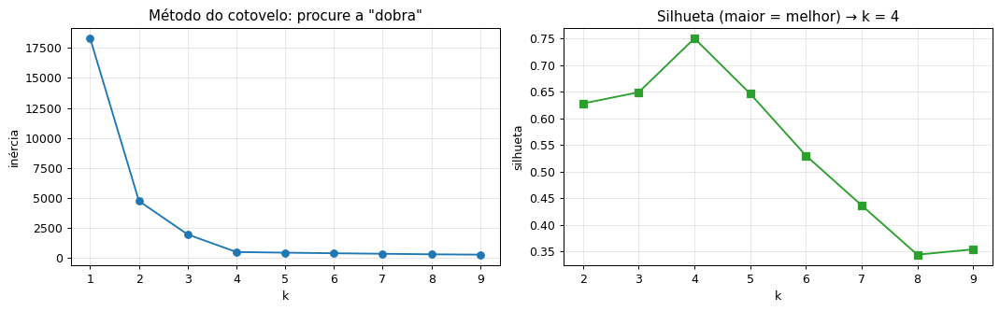

In [56]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = range(1, 10)
inercias = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xk).inertia_ for k in ks]
silhuetas = [silhouette_score(Xk, KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(Xk)) for k in ks[1:]]

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].plot(ks, inercias, 'o-'); axs[0].set_xlabel('k'); axs[0].set_ylabel('inércia')
axs[0].set_title('Método do cotovelo: procure a "dobra"')
axs[1].plot(list(ks)[1:], silhuetas, 's-', color=CORES[2]); axs[1].set_xlabel('k'); axs[1].set_ylabel('silhueta')
axs[1].set_title(f'Silhueta (maior = melhor) → k = {list(ks)[1:][int(np.argmax(silhuetas))]}')
plt.tight_layout(); plt.show()

#### 🔎 Como interpretar os gráficos

- **Método do cotovelo (esquerda):** a inércia cai muito de k = 1 para 2, 3 e 4 (de 18.296 para 503), e depois quase não cai mais (449, 401...). O **"cotovelo" em k = 4** indica que, a partir dali, criar novos grupos só "quebra" grupos que já são naturais.
  - **Por que a inércia sempre cai?** Com mais centróides, cada ponto fica mais perto de algum deles. No limite (k = nº de pontos), a inércia é zero. Por isso **não** escolhemos o k de menor inércia.
- **Silhueta (direita):** para cada ponto, compara a distância média aos pontos do **próprio grupo** com a distância ao **grupo vizinho mais próximo**. Varia de −1 (ponto no grupo errado) a +1 (grupos bem separados). O máximo é **0,75 em k = 4**.
- **Conclusão:** os dois métodos concordam em **k = 4**, exatamente o número de grupos usados para gerar os dados. Em dados reais os critérios nem sempre concordam, e o **conhecimento do domínio** ajuda a decidir.

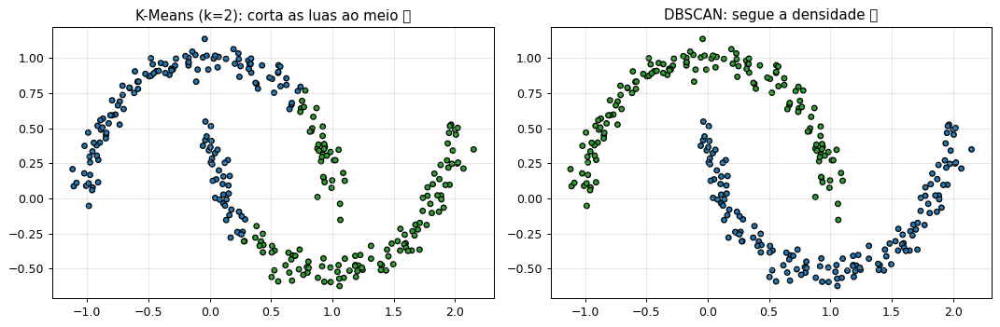

In [57]:
# Limitação: K-Means assume grupos "redondos". DBSCAN agrupa por densidade.
from sklearn.cluster import DBSCAN
Xlua, _ = make_moons(n_samples=300, noise=0.06, random_state=0)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].scatter(*Xlua.T, c=KMeans(2, n_init=10, random_state=0).fit_predict(Xlua), cmap=CMAP_PONTOS, edgecolor='k', s=20)
axs[0].set_title('K-Means (k=2): corta as luas ao meio ❌')
axs[1].scatter(*Xlua.T, c=DBSCAN(eps=0.2, min_samples=5).fit_predict(Xlua), cmap=CMAP_PONTOS, edgecolor='k', s=20)
axs[1].set_title('DBSCAN: segue a densidade ✅')
plt.tight_layout(); plt.show()

#### 🔎 Como interpretar a figura

- **K-Means (esquerda):** corta as duas luas com uma **linha reta**, misturando metade de cada lua. **Por que?** Ele atribui cada ponto ao centróide mais próximo, e isso sempre gera regiões **convexas** separadas por retas (diagrama de Voronoi). Não consegue representar formas curvas ou entrelaçadas.
- **DBSCAN (direita):** separa as luas corretamente. Ele agrupa pontos que estão em regiões **densas** e **conectadas**: dois pontos ficam no mesmo grupo se existe uma "trilha" de vizinhos próximos (distância < `eps`) ligando um ao outro. Vantagens extras: **não precisa saber k** de antemão e marca pontos isolados como **ruído**.
- **💡 Conceito-chave:** cada algoritmo de *clustering* tem seu **viés indutivo** sobre o que é "um grupo". K-Means: grupos esféricos de tamanho parecido. DBSCAN: regiões densas conectadas. Escolha conforme a forma esperada dos dados.

### 12.2 Exemplo prático: segmentação de clientes

Uma loja quer agrupar clientes por **renda anual** e **pontuação de gastos** para criar campanhas de marketing específicas.

,renda_mil,pontuacao_gasto,perfil,nº clientes
segmento,,,,
0,54.7,49.5,"renda média, gasto médio",100
1,90.5,84.7,"renda alta, gasto alto",60
2,89.7,10.7,"renda alta, gasto baixo",60
3,24.3,78.4,"renda baixa, gasto alto",60
4,23.7,19.2,"renda baixa, gasto baixo",60


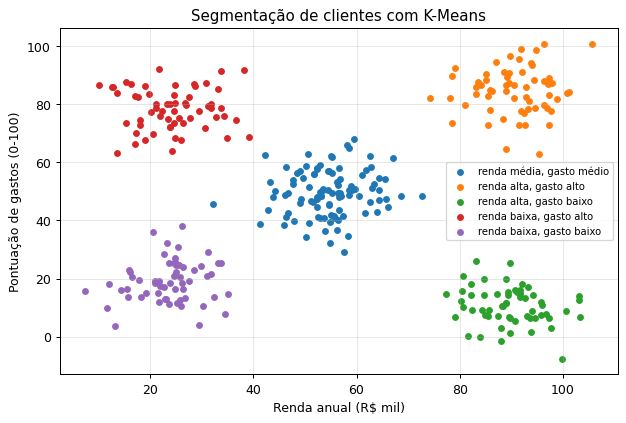

In [58]:
rng = np.random.default_rng(7)
grupos = [((25, 20), 60), ((25, 80), 60), ((55, 50), 100), ((90, 15), 60), ((90, 85), 60)]
clientes = np.vstack([rng.normal(c, (7, 8), size=(n, 2)) for c, n in grupos])
clientes_df = pd.DataFrame(clientes, columns=['renda_mil', 'pontuacao_gasto'])

seg = make_pipeline(StandardScaler(), KMeans(n_clusters=5, n_init=10, random_state=0))
clientes_df['segmento'] = seg.fit_predict(clientes_df[['renda_mil', 'pontuacao_gasto']])

resumo = clientes_df.groupby('segmento')[['renda_mil', 'pontuacao_gasto']].mean().round(1)
def nomear(r):
    renda = 'alta' if r.renda_mil > 70 else ('baixa' if r.renda_mil < 40 else 'média')
    gasto = 'alto' if r.pontuacao_gasto > 65 else ('baixo' if r.pontuacao_gasto < 35 else 'médio')
    return f'renda {renda}, gasto {gasto}'
resumo['perfil'] = resumo.apply(nomear, axis=1)
resumo['nº clientes'] = clientes_df['segmento'].value_counts().sort_index()
display(resumo)

plt.figure(figsize=(8, 5))
for s, r in resumo.iterrows():
    pts = clientes_df[clientes_df.segmento == s]
    plt.scatter(pts.renda_mil, pts.pontuacao_gasto, s=20, label=r.perfil)
plt.xlabel('Renda anual (R$ mil)'); plt.ylabel('Pontuação de gastos (0-100)')
plt.title('Segmentação de clientes com K-Means'); plt.legend(fontsize=8); plt.show()

#### 🔎 Como interpretar o resultado

- **Tabela de segmentos:** o K-Means encontrou 5 perfis de clientes, e a média de cada grupo permite **dar nome** a eles:

| Perfil | Leitura de negócio | Ação sugerida |
|---|---|---|
| Renda alta, gasto alto | Clientes "VIP" | Programa de fidelidade, lançamentos exclusivos |
| Renda alta, gasto baixo | **Potencial inexplorado** | Campanhas para aumentar o engajamento |
| Renda baixa, gasto alto | Gastam muito em relação à renda | Ofertas de parcelamento; atenção ao risco de crédito |
| Renda baixa, gasto baixo | Clientes ocasionais | Promoções de baixo custo |
| Renda média, gasto médio | O grupo mais numeroso (100) | Comunicação geral |

- **Por que usamos `StandardScaler` antes?** Renda (≈ 10–110) e pontuação (0–100) estão em escalas parecidas aqui, mas em dados reais raramente estão. Padronizar garante que os dois atributos tenham **o mesmo peso** na distância.
- **💡 Importante:** o algoritmo **não sabe** o que é "VIP". Ele só encontra grupos; a **interpretação** e as **ações** vêm do analista. Em aprendizado não supervisionado não existe "resposta certa" para comparar, e a validação depende do **valor que os grupos geram** para o negócio.

### 12.3 Redução de dimensionalidade com PCA

A **Análise de Componentes Principais** encontra as direções de **maior variância** dos dados e projeta os dados nelas. Usos: visualização, compressão, remoção de ruído, acelerar outros algoritmos.

Exemplo: as imagens de dígitos têm **64 dimensões** (8×8 pixels). Com PCA, podemos vê-las em **2D**:

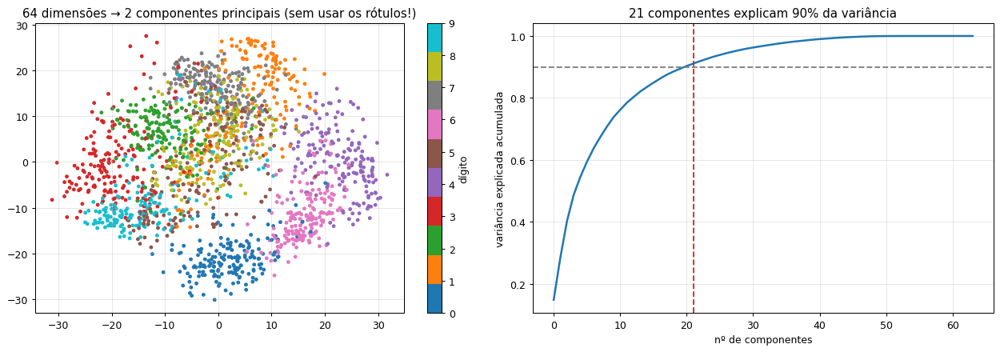

In [59]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2).fit(digitos.data)
Z = pca.transform(digitos.data)
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
sc = axs[0].scatter(Z[:, 0], Z[:, 1], c=digitos.target, cmap='tab10', s=8)
plt.colorbar(sc, ax=axs[0], label='dígito')
axs[0].set_title('64 dimensões → 2 componentes principais (sem usar os rótulos!)')

pca_full = PCA().fit(digitos.data)
axs[1].plot(np.cumsum(pca_full.explained_variance_ratio_), lw=2)
axs[1].axhline(0.9, ls='--', color='gray')
n90 = np.argmax(np.cumsum(pca_full.explained_variance_ratio_) >= 0.9) + 1
axs[1].axvline(n90, ls='--', color=CORES[1])
axs[1].set_xlabel('nº de componentes'); axs[1].set_ylabel('variância explicada acumulada')
axs[1].set_title(f'{n90} componentes explicam 90% da variância')
plt.tight_layout(); plt.show()

#### 🔎 Como interpretar os gráficos

- **Esquerda, os dígitos projetados em 2D:** cada ponto é uma imagem de 64 pixels, resumida em apenas **2 números** (as duas primeiras componentes principais). As cores (dígitos) só foram usadas para **pintar** o gráfico, **não** para calcular a projeção.
  - Mesmo assim, aparecem **aglomerados** por dígito: os 0 ficam de um lado, os 4 de outro... O PCA preservou boa parte da estrutura dos dados.
  - Alguns dígitos se **sobrepõem** (como 1, 7 e 9): em 2D perdemos informação, e essas classes precisariam de mais dimensões para serem separadas.
- **Direita, variância explicada acumulada:** mostra quanto da "informação" (variância) é preservado com *n* componentes. Com **21 componentes** mantemos **90%** da variância, ou seja, uma compressão de 64 → 21 números (~3×) perdendo apenas 10%.
- **Por que funciona?** Os pixels são **altamente correlacionados**: pixels vizinhos tendem a ter valores parecidos, e os cantos da imagem são quase sempre brancos. O PCA encontra combinações de pixels que capturam essas redundâncias.

In [60]:
# 🎬 ANIMAÇÃO — reconstruindo um dígito com cada vez mais componentes principais
img = digitos.data[0]
fig, axs = plt.subplots(1, 2, figsize=(7, 3.5))
def quadro_pca(n):
    p = PCA(n_components=n).fit(digitos.data)
    rec = p.inverse_transform(p.transform(img.reshape(1, -1)))
    for ax in axs:
        ax.clear(); ax.axis('off')
    axs[0].imshow(img.reshape(8, 8), cmap='gray_r'); axs[0].set_title('original (64 valores)')
    axs[1].imshow(rec.reshape(8, 8), cmap='gray_r'); axs[1].set_title(f'{n} componente(s)')
anim = animation.FuncAnimation(fig, quadro_pca, frames=[1, 2, 3, 5, 8, 12, 16, 24, 32, 48, 64], interval=700)
mostrar_animacao(anim)

#### 🔎 Como interpretar a animação

- À esquerda está a imagem **original** de um "0" (64 valores); à direita, a imagem **reconstruída** a partir de *n* componentes principais.
- **1–3 componentes:** um borrão. Já dá para perceber uma forma "escura no contorno, clara no meio", mas não o dígito.
- **8–12 componentes:** o "0" já é reconhecível.
- **24+ componentes:** praticamente idêntico ao original.
- **Por que funciona?** Cada componente é um "padrão de pixels" (uma imagem-base). A reconstrução é uma **soma ponderada** dessas imagens-base. As primeiras componentes capturam os padrões **mais comuns** entre todos os dígitos, e as últimas só detalhes finos, muitas vezes ruído.
- **💡 Aplicações:** compressão de imagens, remoção de ruído (descartar as últimas componentes), visualização de dados de alta dimensão e aceleração de outros algoritmos (menos atributos = treino mais rápido).

---
## Parte 13 — Aprendizado por reforço: Q-Learning (Mitchell, Cap. 13)

Um **agente** interage com um **ambiente**: observa o **estado** $s$, executa uma **ação** $a$, recebe uma **recompensa** $r$ e vai para o estado $s'$. Ninguém diz qual é a ação correta — o agente aprende por **tentativa e erro**.

```
        ┌─────────── ação a ───────────┐
        │                              ▼
   ┌─────────┐                   ┌────────────┐
   │ AGENTE  │◄── estado s', r ──│ AMBIENTE   │
   └─────────┘                   └────────────┘
```

Relacionando com Mitchell: **T** = escolher ações; **P** = recompensa acumulada (descontada); **E** = interações com o ambiente.

### 13.1 A função Q e a regra de atualização

$Q(s, a)$ estima a recompensa total futura ao tomar a ação $a$ no estado $s$ e agir bem depois disso. O **Q-Learning** (Watkins, 1989) atualiza:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\Big[r + \gamma \max_{a'} Q(s',a') - Q(s,a)\Big]$$

- $\alpha$: taxa de aprendizado; $\gamma$: fator de desconto (quanto o futuro importa);
- **Exploração × exploração** (*exploration vs. exploitation*): com probabilidade $\varepsilon$ o agente faz uma ação **aleatória** (explora); senão escolhe a melhor ação conhecida (*ε-greedy*).

### 13.2 Exemplo: robô no labirinto
O robô começa em **S** e precisa chegar em **G** (+10), evitando as armadilhas **X** (−10). Cada passo custa −0,1.

Recompensa média nos 10 primeiros episódios: -13.65
Recompensa média nos 50 últimos episódios : 3.66


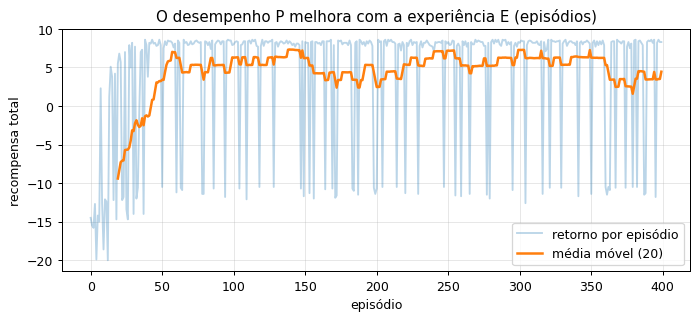

In [61]:
MAPA = [
    'S..#....',
    '.#.#.##.',
    '.#...#X.',
    '.##X.#..',
    '....X..G',
]
LIN, COL = len(MAPA), len(MAPA[0])
ACOES = [(-1, 0), (1, 0), (0, -1), (0, 1)]          # cima, baixo, esquerda, direita
SETAS = ['↑', '↓', '←', '→']
INICIO = next((r, c) for r in range(LIN) for c in range(COL) if MAPA[r][c] == 'S')

def passo(s, a):
    r, c = s[0] + ACOES[a][0], s[1] + ACOES[a][1]
    if not (0 <= r < LIN and 0 <= c < COL) or MAPA[r][c] == '#':
        r, c = s                                         # bateu na parede: fica parado
    celula = MAPA[r][c]
    if celula == 'G':
        return (r, c), 10.0, True
    if celula == 'X':
        return (r, c), -10.0, True
    return (r, c), -0.1, False

def q_learning(episodios=400, alpha=0.5, gamma=0.95, eps=0.2, semente=0, salvar_em=()):
    rng = np.random.default_rng(semente)
    Q = np.zeros((LIN, COL, 4))
    retornos, snapshots = [], {}
    for ep in range(1, episodios + 1):
        s, total, fim, n = INICIO, 0.0, False, 0
        while not fim and n < 200:
            a = rng.integers(4) if rng.random() < eps else int(np.argmax(Q[s]))
            s2, r, fim = passo(s, a)
            alvo = r if fim else r + gamma * np.max(Q[s2])
            Q[s][a] += alpha * (alvo - Q[s][a])
            s, total, n = s2, total + r, n + 1
        retornos.append(total)
        if ep in salvar_em:
            snapshots[ep] = Q.copy()
    return Q, retornos, snapshots

marcos_ep = [1, 5, 10, 20, 40, 80, 150, 250, 400]
Q, retornos, snaps = q_learning(salvar_em=marcos_ep)
print(f'Recompensa média nos 10 primeiros episódios: {np.mean(retornos[:10]):.2f}')
print(f'Recompensa média nos 50 últimos episódios : {np.mean(retornos[-50:]):.2f}')

plt.figure(figsize=(9, 3.5))
plt.plot(retornos, alpha=0.3, label='retorno por episódio')
plt.plot(pd.Series(retornos).rolling(20).mean(), lw=2, label='média móvel (20)')
plt.xlabel('episódio'); plt.ylabel('recompensa total'); plt.legend()
plt.title('O desempenho P melhora com a experiência E (episódios)')
plt.show()

#### 🔎 Como interpretar o resultado

- **Recompensa média nos 10 primeiros episódios ≈ −13,7:** no início, a tabela Q está zerada e o robô anda **aleatoriamente**. Ele cai nas armadilhas (−10) ou vaga até o limite de 200 passos, acumulando −0,1 por passo.
- **Recompensa média nos 50 últimos episódios ≈ +3,7:** agora o robô chega ao objetivo na maioria das vezes. O ótimo seria 10 − 14 × 0,1 = **+8,6** (15 passos); a média fica abaixo disso porque, com **ε = 0,2**, em 20% das decisões o robô ainda faz uma ação aleatória de propósito (exploração), o que às vezes o leva a uma armadilha.
- **Como ler o gráfico:** a linha clara é a recompensa de cada episódio (muito ruidosa); a linha escura é a média móvel. A **subida brusca nos primeiros ~40 episódios** marca o momento em que o robô descobre o caminho até G e a informação começa a se propagar pela tabela Q.
- **Por que a informação "se propaga"?** A regra `Q(s,a) ← … r + γ·max Q(s',a')` copia parte do valor do estado seguinte para o estado atual. A recompensa de +10 em G é transmitida **de trás para frente**, passo a passo, ao longo do caminho, um episódio de cada vez.

In [62]:
# 🎬 ANIMAÇÃO — valores V(s) = max_a Q(s,a) e a política aprendida ao longo dos episódios
def caminho_guloso(Q):
    s, cam = INICIO, [INICIO]
    for _ in range(40):
        s, _, fim = passo(s, int(np.argmax(Q[s])))
        cam.append(s)
        if fim:
            break
    return cam

fig, ax = plt.subplots(figsize=(9, 5.5))
def quadro_q(ep):
    Qs = snaps[ep]
    ax.clear()
    V = Qs.max(axis=2).copy()
    mascara = np.array([[ch == '#' for ch in linha] for linha in MAPA])
    V[mascara] = np.nan
    ax.imshow(V, cmap='RdYlGn', vmin=-5, vmax=10)
    for r in range(LIN):
        for c in range(COL):
            ch = MAPA[r][c]
            if ch == '#':
                ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, color='#333'))
            elif ch in 'GX':
                ax.text(c, r, ch, ha='center', va='center', fontsize=16, fontweight='bold')
            else:
                ax.text(c, r, SETAS[int(np.argmax(Qs[r, c]))] if Qs[r, c].any() else '·',
                        ha='center', va='center', fontsize=14)
                if ch == 'S':
                    ax.text(c - 0.35, r - 0.3, 'S', fontsize=9, fontweight='bold')
    cam = np.array(caminho_guloso(Qs))
    ax.plot(cam[:, 1], cam[:, 0], 'b-', lw=3, alpha=0.6)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_title(f'Após {ep} episódio(s): cores = V(s), setas = política, azul = caminho do robô')

anim = animation.FuncAnimation(fig, quadro_q, frames=marcos_ep, interval=1000)
mostrar_animacao(anim)

#### 🔎 Como interpretar a animação

- **Cores:** o valor `V(s) = max Q(s,a)`, isto é, quão bom é estar em cada célula. **Verde** = valor alto (a partir dali o robô chega ao objetivo com boa recompensa); **amarelo/laranja** = valor perto de zero ou levemente negativo (ainda desconhecido, ou só com custos de passos). As células escuras são paredes.
- **Setas:** a **política** aprendida (a melhor ação conhecida em cada célula); `·` indica uma célula ainda não visitada.
- **Linha azul:** o caminho que o robô faria seguindo a política **sem explorar**.
- **O que acontece ao longo dos episódios:**
  1. **Episódios 1–10:** quase tudo sem cor definida e setas confusas. O robô ainda não sabe chegar a G, e a linha azul fica "presa" perto do início.
  2. **Episódios 10–20:** as células **perto de G ficam verdes primeiro**, e o verde vai se espalhando para trás, em direção ao início. É a **propagação do valor** descrita acima.
  3. **A partir do episódio ~40:** as setas formam um caminho coerente de S até G, e a linha azul percorre o **caminho ótimo** (15 passos), passando ao lado da armadilha X sem cair nela. Nos episódios seguintes a política quase não muda; os valores só se refinam.
- **Repare:** nenhuma seta do caminho aponta **para dentro** de uma armadilha. O agente aprendeu a evitá-las só pelas recompensas negativas, sem que ninguém programasse "fuja do X".
- **💡 Conceito-chave:** o robô nunca recebeu um mapa nem exemplos de "ação correta". Aprendeu apenas com **tentativa, erro e recompensa**. É a mesma ideia do programa de damas de Samuel (1959) e de sistemas modernos como o AlphaGo.

---
## Parte 14 — Projeto completo: do dado bruto ao modelo avaliado

Vamos juntar **tudo** em um *pipeline* realista, com um conjunto de dados **misto** (numérico + categórico + valores ausentes): prever se um cliente de um banco vai **cancelar** o cartão (*churn*).

**Definição do problema (T/P/E):**
- **T:** prever se o cliente vai cancelar nos próximos meses;
- **P:** F1-score da classe "cancela" (classes desbalanceadas → acurácia engana);
- **E:** histórico de clientes que cancelaram ou não.

In [63]:
# 1) DADOS — gerados sinteticamente com regras realistas
rng = np.random.default_rng(2024)
n = 2000
df = pd.DataFrame({
    'idade': rng.integers(18, 80, n),
    'renda_mil': np.round(rng.lognormal(3.6, 0.5, n), 1),
    'meses_cliente': rng.integers(1, 120, n),
    'reclamacoes': rng.poisson(0.8, n),
    'uso_mensal': np.round(rng.gamma(2.0, 400, n), 0),
    'plano': rng.choice(['básico', 'gold', 'platinum'], n, p=[0.6, 0.3, 0.1]),
    'regiao': rng.choice(['Sudeste', 'Sul', 'Nordeste', 'Norte', 'Centro-Oeste'], n),
})
logit = (0.5 + 1.5 * df.reclamacoes - 0.05 * df.meses_cliente - 0.0015 * df.uso_mensal
         + 1.0 * (df.plano == 'básico') - 0.02 * (df.idade - 45))
df['cancelou'] = (rng.random(n) < sigmoide(logit)).astype(int)
for col in ['renda_mil', 'uso_mensal']:                 # simula dados faltantes
    df.loc[rng.random(n) < 0.05, col] = np.nan

print(f'{len(df)} clientes | taxa de cancelamento = {df.cancelou.mean():.1%}')
display(df.head())
print('\nValores ausentes:\n', df.isna().sum()[df.isna().sum() > 0])

2000 clientes | taxa de cancelamento = 25.4%


,idade,renda_mil,meses_cliente,reclamacoes,uso_mensal,plano,regiao,cancelou
0,32,63.5,104,2,654.0,básico,Sul,1
1,59,113.1,50,1,586.0,básico,Nordeste,0
2,23,46.8,52,2,644.0,básico,Nordeste,0
3,31,25.6,78,0,795.0,gold,Sul,0
4,37,49.3,34,1,97.0,básico,Norte,1



Valores ausentes:
 renda_mil     96
uso_mensal    87
dtype: int64


#### 🔎 Como interpretar o resultado

- **2.000 clientes e taxa de cancelamento de 25,4%:** as classes são **desbalanceadas** (3 "ficam" para cada 1 que "cancela"). Um modelo que dissesse sempre "fica" teria ~75% de acurácia e seria inútil. Por isso escolhemos o **F1 da classe "cancela"** como medida P.
- **Valores ausentes:** ~5% de `renda_mil` e de `uso_mensal` estão faltando, como acontece em bases reais (cadastros incompletos, falhas de integração). O *pipeline* precisará tratar isso.
- **Como os dados foram gerados:** a probabilidade de cancelar **aumenta** com reclamações e com o plano básico, e **diminui** com o tempo de cliente, o uso e a idade. **Renda e região não têm efeito real.** Guarde essa informação: vamos ver se o modelo descobre essas relações sozinho.

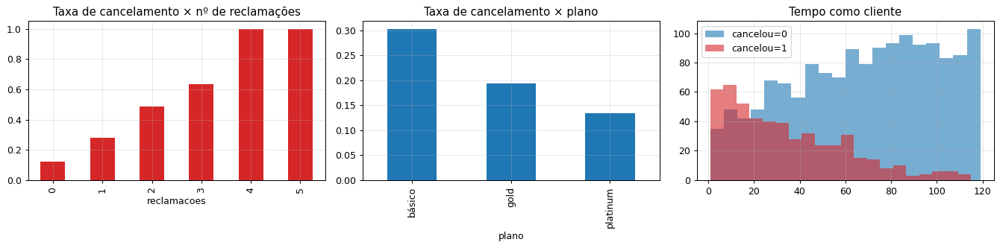

In [64]:
# 2) ANÁLISE EXPLORATÓRIA rápida
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
df.groupby('reclamacoes').cancelou.mean().plot.bar(ax=axs[0], color=CORES[1])
axs[0].set_title('Taxa de cancelamento × nº de reclamações')
df.groupby('plano').cancelou.mean().plot.bar(ax=axs[1], color=CORES[0])
axs[1].set_title('Taxa de cancelamento × plano')
for c, cor in [(0, CORES[0]), (1, CORES[1])]:
    axs[2].hist(df[df.cancelou == c].meses_cliente, bins=20, alpha=0.6, color=cor, label=f'cancelou={c}')
axs[2].set_title('Tempo como cliente'); axs[2].legend()
plt.tight_layout(); plt.show()

#### 🔎 Como interpretar os gráficos

- **Reclamações (esquerda):** a taxa de cancelamento sobe de forma muito clara: ~**12%** com 0 reclamações, ~**28%** com 1, ~**49%** com 2, ~**63%** com 3, e quase todos com 4 ou mais. É um **sinal forte** e quase monotônico, um ótimo atributo preditivo.
- **Plano (centro):** básico ~**30%**, gold ~**19%**, platinum ~**13%**. Clientes de planos superiores cancelam menos.
- **Tempo como cliente (direita):** os que cancelaram (vermelho) se concentram nos **primeiros meses**; clientes antigos raramente cancelam. É comum em negócios reais: o risco é maior logo após a contratação.
- **💡 Por que fazer EDA antes de modelar?** Para (1) entender o problema, (2) encontrar erros nos dados, (3) ter **expectativas** sobre o que o modelo deve aprender e (4) poder desconfiar do modelo se ele disser algo muito diferente do que os dados mostram.

Regressão logística    F1 (CV 5-fold) = 0.703 ± 0.028
KNN                    F1 (CV 5-fold) = 0.603 ± 0.036
Árvore de decisão      F1 (CV 5-fold) = 0.624 ± 0.023
Random Forest          F1 (CV 5-fold) = 0.679 ± 0.032
Gradient Boosting      F1 (CV 5-fold) = 0.658 ± 0.034


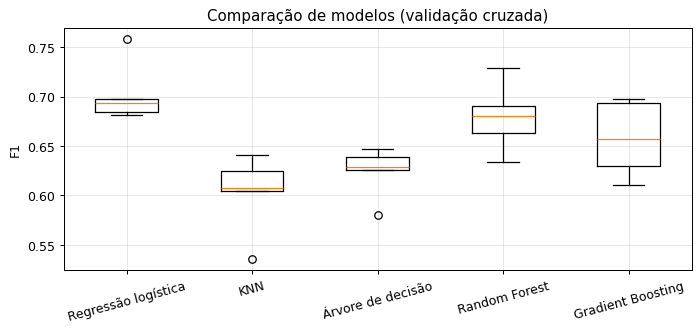

In [65]:
# 3) PIPELINE: pré-processamento + modelo, sem vazamento de dados
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

num = ['idade', 'renda_mil', 'meses_cliente', 'reclamacoes', 'uso_mensal']
cat = ['plano', 'regiao']
X_ch, y_ch = df[num + cat], df['cancelou']
X_ch_tr, X_ch_te, y_ch_tr, y_ch_te = train_test_split(X_ch, y_ch, test_size=0.25, random_state=0, stratify=y_ch)

preproc = ColumnTransformer([
    ('num', Pipeline([('imputar', SimpleImputer(strategy='median')), ('escalar', StandardScaler())]), num),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat),
])

candidatos = {
    'Regressão logística': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'KNN': KNeighborsClassifier(n_neighbors=15),
    'Árvore de decisão': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=0),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced', random_state=0),
    'Gradient Boosting': GradientBoostingClassifier(random_state=0),
}
resultados = {}
for nome, modelo in candidatos.items():
    pipe = Pipeline([('prep', preproc), ('modelo', modelo)])
    s = cross_val_score(pipe, X_ch_tr, y_ch_tr, cv=5, scoring='f1')
    resultados[nome] = s
    print(f'{nome:<22} F1 (CV 5-fold) = {s.mean():.3f} ± {s.std():.3f}')

plt.figure(figsize=(9, 3.5))
plt.boxplot(list(resultados.values()))
plt.xticks(range(1, len(resultados) + 1), list(resultados.keys()), rotation=15)
plt.ylabel('F1'); plt.title('Comparação de modelos (validação cruzada)')
plt.show()

#### 🔎 Como interpretar o resultado

- **O `Pipeline` + `ColumnTransformer`** aplica automaticamente:
  - nas colunas **numéricas**: imputação pela mediana → padronização;
  - nas **categóricas**: *one-hot encoding*.

  Dentro do `cross_val_score`, esse pré-processamento é **reajustado em cada fold usando só os dados de treino daquele fold**, o que elimina o risco de vazamento de dados.
- **Comparação (F1 na validação cruzada):**

| Modelo | F1 | Leitura |
|---|---|---|
| **Regressão logística** | **0,703** | Melhor, porque a relação nos dados é aproximadamente linear no logit (foi assim que os geramos) |
| Random Forest | 0,679 | Próxima |
| Gradient Boosting | 0,658 | Sem ajuste de hiperparâmetros |
| Árvore de decisão | 0,624 | Uma única árvore é limitada |
| KNN | 0,603 | Sofre com atributos *one-hot* e sem `class_weight` |

- **Boxplot:** cada caixa mostra a distribuição dos 5 valores de F1. Caixas que **se sobrepõem** indicam que a diferença entre os modelos pode não ser significativa.
- **`class_weight='balanced'`:** faz os erros na classe minoritária ("cancela") **pesarem mais** no treino. Sem isso, o modelo tenderia a prever "fica" quase sempre.
- **F1 ≈ 0,70 é bom?** Para *churn*, sim: o comportamento humano tem muita aleatoriedade, e mesmo o modelo "perfeito" que gerou os dados não acertaria todos os casos.

Melhor configuração: {'modelo__C': 0.1} | F1 (CV) = 0.706

              precision    recall  f1-score   support

        fica       0.93      0.78      0.85       373
     cancela       0.56      0.83      0.67       127

    accuracy                           0.79       500
   macro avg       0.75      0.81      0.76       500
weighted avg       0.84      0.79      0.80       500



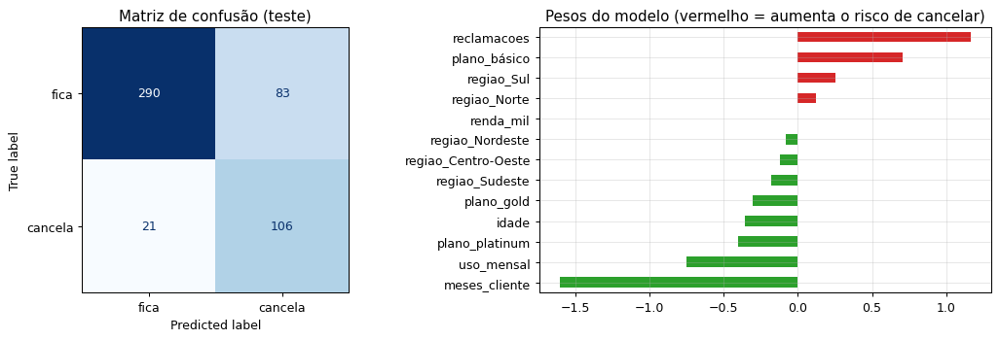

In [66]:
# 4) AJUSTE FINO + 5) AVALIAÇÃO FINAL no teste (uma única vez!)
# Escolhemos a regressão logística: desempenho competitivo na CV e pesos INTERPRETÁVEIS.
pipe_final = Pipeline([('prep', preproc), ('modelo', LogisticRegression(max_iter=1000, class_weight='balanced'))])
busca_ch = GridSearchCV(pipe_final, {'modelo__C': [0.01, 0.1, 1, 10]}, cv=5, scoring='f1').fit(X_ch_tr, y_ch_tr)
print('Melhor configuração:', busca_ch.best_params_, f'| F1 (CV) = {busca_ch.best_score_:.3f}\n')

final = busca_ch.best_estimator_
pred_ch = final.predict(X_ch_te)
print(classification_report(y_ch_te, pred_ch, target_names=['fica', 'cancela']))

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay(confusion_matrix(y_ch_te, pred_ch), display_labels=['fica', 'cancela']).plot(ax=axs[0], cmap='Blues', colorbar=False)
axs[0].grid(False); axs[0].set_title('Matriz de confusão (teste)')

nomes_feat = num + list(final.named_steps['prep'].named_transformers_['cat'].get_feature_names_out(cat))
coefs = pd.Series(final.named_steps['modelo'].coef_[0], index=nomes_feat).sort_values()
coefs.plot.barh(ax=axs[1], color=[CORES[2] if c < 0 else CORES[1] for c in coefs])
axs[1].set_title('Pesos do modelo (vermelho = aumenta o risco de cancelar)')
plt.tight_layout(); plt.show()

#### 🔎 Como interpretar o resultado

- **Melhor C = 0,1** (regularização moderada), com **F1 de 0,706 na CV** e **0,67 no teste**. Valores próximos indicam que a estimativa da validação cruzada era realista.
- **Relatório no teste (classe "cancela"):**
  - **Revocação 0,83:** o modelo identifica **83%** dos clientes que de fato vão cancelar. Para uma campanha de retenção, isso é o mais importante;
  - **Precisão 0,56:** de cada 100 clientes alertados, 56 iriam mesmo cancelar e 44 são "alarmes falsos". Se oferecer um desconto for barato, é um ótimo negócio.
  - Esse equilíbrio vem do `class_weight='balanced'`, que privilegia a revocação. Mudando o limiar de decisão (Seção 11.2), a empresa pode ajustar a troca entre precisão e revocação conforme o custo da campanha.
- **Gráfico de pesos (direita):** como os atributos numéricos foram padronizados, os pesos são **comparáveis**:
  - **Aumentam o risco (vermelho):** `reclamacoes` (+1,17) e `plano_básico` (+0,71);
  - **Diminuem o risco (verde):** `meses_cliente` (−1,61, o mais forte), `uso_mensal` (−0,75) e `idade` (−0,36);
  - **`renda_mil` ≈ 0:** o modelo descobriu que a renda **não importa**, o que está correto, pois ela não foi usada na geração dos dados;
  - **Regiões com pesos pequenos (±0,1–0,3):** também não têm efeito real. Esses valores são **ruído** da amostra, um alerta para não interpretar pesos pequenos como "descobertas".
- **💡 Conclusão:** o modelo recuperou as relações reais dos dados, e isso pode ser verificado olhando os pesos: um modelo **interpretável** permite auditar se ele aprendeu algo sensato.

In [67]:
# 6) USO DO MODELO em produção: novos clientes
novos_clientes = pd.DataFrame([
    {'idade': 30, 'renda_mil': 40, 'meses_cliente': 3,  'reclamacoes': 4, 'uso_mensal': 150,  'plano': 'básico',   'regiao': 'Sul'},
    {'idade': 55, 'renda_mil': 90, 'meses_cliente': 96, 'reclamacoes': 0, 'uso_mensal': 1800, 'plano': 'platinum', 'regiao': 'Sudeste'},
    {'idade': 42, 'renda_mil': 55, 'meses_cliente': 24, 'reclamacoes': 1, 'uso_mensal': 700,  'plano': 'gold',     'regiao': 'Nordeste'},
])
novos_clientes['P(cancelar)'] = final.predict_proba(novos_clientes).round(3)[:, 1]
novos_clientes['ação sugerida'] = np.where(novos_clientes['P(cancelar)'] > 0.5, '📞 contatar com oferta', '✅ manter')
display(novos_clientes)

,idade,renda_mil,meses_cliente,reclamacoes,uso_mensal,plano,regiao,P(cancelar),ação sugerida
0,30,40,3,4,150,básico,Sul,1.000,📞 contatar com oferta
1,55,90,96,0,1800,platinum,Sudeste,0.002,✅ manter
2,42,55,24,1,700,gold,Nordeste,0.669,📞 contatar com oferta


#### 🔎 Como interpretar o resultado

| Cliente | Perfil | P(cancelar) | Por quê |
|---|---|---|---|
| 1 | 3 meses de casa, **4 reclamações**, plano básico, pouco uso | **≈ 100%** | Combina todos os fatores de risco |
| 2 | 8 anos de casa, 0 reclamações, platinum, uso alto | **≈ 0,2%** | Combina todos os fatores de proteção |
| 3 | 2 anos, 1 reclamação, gold, uso médio | **≈ 67%** | Caso intermediário. Apesar de parecer um cliente "médio", fica acima do limiar de 50% |

- **Por que o cliente 3 tem probabilidade tão alta?** Os dados foram gerados com uma taxa de cancelamento de 25%, e o modelo com `class_weight='balanced'` **"empurra" as probabilidades para cima** para não perder clientes que vão cancelar. Por isso, as probabilidades de um modelo treinado com balanceamento **não devem ser lidas como probabilidades reais**; para isso seria preciso **calibrá-lo** (`CalibratedClassifierCV`).
- **💡 Do modelo à decisão:** em produção, o modelo é aplicado periodicamente a toda a base de clientes, e a equipe de retenção recebe a lista ordenada por risco. Este é o ciclo completo de ML: **dados → modelo → decisão → ação → novos dados** (que serão a experiência E do próximo treino).

---
## Parte 15 — Ética, boas práticas, resumo e exercícios

### 15.1 Ética e responsabilidade em ML

Modelos aprendem com dados históricos — e **herdam seus vieses**.

| Risco | Exemplo | Mitigação |
|---|---|---|
| **Viés nos dados** | Modelo de crédito que penaliza um bairro por padrões históricos de discriminação | Auditar dados e métricas **por grupo** |
| **Atributos sensíveis "disfarçados"** | CEP funcionando como substituto de raça/renda | Analisar correlações; *fairness metrics* |
| **Falta de explicabilidade** | Negar um empréstimo sem justificar | Modelos interpretáveis, SHAP/LIME |
| **Privacidade** | Treinar com dados pessoais sem consentimento | **LGPD**, anonimização |
| **Mudança de distribuição** (*data drift*) | Modelo treinado antes da pandemia falha depois dela | Monitorar e retreinar |

### 15.2 Boas práticas — *checklist*

- ✅ Defina **T, P e E** antes de escrever código;
- ✅ Separe o conjunto de **teste** no início e só o use no **final**;
- ✅ Comece com um **modelo simples** (*baseline*) — às vezes ele basta;
- ✅ Faça o pré-processamento **dentro de um Pipeline** (evita vazamento);
- ✅ Use **validação cruzada** para comparar modelos e escolher hiperparâmetros;
- ✅ Escolha a **métrica certa** para o problema (cuidado com a acurácia em dados desbalanceados);
- ✅ Analise **erros** e **importância dos atributos** — entenda o que o modelo aprendeu;
- ✅ Documente e versione dados, código e modelos.

### 15.3 Resumo dos algoritmos estudados

| Algoritmo | Tipo | Viés indutivo / ideia | Prós | Contras |
|---|---|---|---|---|
| **Find-S / Elim. de Candidatos** | Conceitos | Conceito é uma conjunção | Didático; base teórica | Não tolera ruído |
| **Regressão linear** | Regressão | Relação linear | Simples, interpretável | Só relações lineares |
| **Regressão logística** | Classificação | Fronteira linear | Probabilidades; interpretável | Fronteira linear |
| **Perceptron** | Classificação | Fronteira linear | Base das redes neurais | Não resolve XOR |
| **KNN** | Ambos | Vizinhos parecidos | Sem treino; flexível | Lento na predição; sensível à escala |
| **Naive Bayes** | Classificação | Atributos independentes | Muito rápido; ótimo em texto | Suposição forte |
| **Árvore (ID3/CART)** | Ambos | Árvores curtas (Occam) | Interpretável; aceita dados mistos | *Overfitting*; instável |
| **SVM** | Ambos | Máxima margem | Ótima em alta dimensão | Escolha de kernel/hiperparâmetros |
| **Random Forest** | Ambos | Média de muitas árvores | Robusta, pouca configuração | Menos interpretável |
| **K-Means** | Agrupamento | Grupos esféricos | Simples e escalável | Precisa de *k*; formas não esféricas |
| **PCA** | Redução de dim. | Direções de maior variância | Visualização, compressão | Apenas linear |
| **Q-Learning** | Reforço | Equação de Bellman | Aprende sem modelo do ambiente | Muitas interações |

### 15.4 Conexões com as próximas aulas

- **Aula 11 — Redes Neurais Artificiais:** generalização do Perceptron com *backpropagation*;
- **Aula 12 — Algoritmos Genéticos:** aprendizado como busca evolutiva (Mitchell, cap. 9);
- **Aula 16 — Raciocínio Probabilístico:** aprofundamento do aprendizado bayesiano;
- **Aula 17 — Raciocínio Baseado em Casos:** aprendizado baseado em instâncias (Mitchell, cap. 8).

### 15.5 Exercícios

**Conceituais**

1. Para cada problema a seguir, identifique **T, P e E** (definição de Mitchell): (a) prever a nota de um aluno na prova final; (b) recomendar músicas; (c) um robô aspirador que aprende a planta da casa.
2. Classifique como supervisionado, não supervisionado ou por reforço: (a) agrupar notícias por assunto; (b) prever o preço de um carro usado; (c) treinar um agente para jogar xadrez.
3. Explique, com suas palavras, por que um aprendiz **sem viés indutivo** não consegue generalizar.
4. Um modelo tem 99% de acurácia no treino e 62% no teste. Qual é o diagnóstico? Cite três ações para melhorar.
5. Em um teste de detecção de fraude, o que é pior: um falso positivo ou um falso negativo? Qual métrica você priorizaria?

**Práticos (use as células deste notebook)**

6. **Find-S:** adicione o exemplo `('Ensolarado', 'Quente', 'Normal', 'Fraco', 'Quente', 'Igual'), True` ao `EXEMPLOS` e execute novamente. Como a hipótese e o espaço de versões mudam?
7. **Gradiente descendente:** modifique `RegressaoLinearGD` para usar **gradiente descendente estocástico** (atualizar com um exemplo por vez). Compare as curvas de custo.
8. **KNN:** implemente o **KNN ponderado pela distância** (peso $w_i = 1/d(x_q, x_i)^2$, Mitchell cap. 8) e compare com o KNN comum no conjunto `make_moons`.
9. **ID3:** calcule à mão o ganho de informação dos atributos `Temperatura`, `Umidade` e `Vento` no subconjunto `Tempo = Ensolarado` e confira com a função `ganho_informacao`.
10. **Naive Bayes:** ative a suavização de Laplace (`NaiveBayesCategorico(suavizacao=1)`) e classifique um dia com `Tempo = Nublado` e `Jogar` = ? Por que a suavização importa aqui?
11. **K-Means:** execute `KMeans_do_zero` com sementes diferentes. Todas convergem para a mesma solução? Pesquise sobre a inicialização **k-means++**.
12. **Q-Learning:** altere `eps` para 0.0 e para 0.8. O que acontece com o aprendizado? Explique em termos de exploração × exploração.
13. **Projeto:** no *pipeline* de *churn*, troque o modelo final por `RandomForestClassifier`, ajuste `n_estimators` e `max_depth` com `GridSearchCV` e compare o F1 no teste.

**Desafio 🏆**

14. Escolha um conjunto de dados público (Kaggle, UCI ou `sklearn.datasets`), defina T/P/E e construa um *pipeline* completo: análise exploratória, pré-processamento, comparação de pelo menos 3 modelos com validação cruzada, ajuste de hiperparâmetros e avaliação final. Escreva um parágrafo discutindo possíveis vieses dos dados.

### 15.6 Referências

**Livro-base**
- MITCHELL, Tom M. ***Machine Learning***. New York: McGraw-Hill, 1997. — capítulos 1 (introdução e T/P/E), 2 (aprendizado de conceitos), 3 (árvores de decisão), 4 (redes neurais/Perceptron), 5 (avaliação de hipóteses), 6 (aprendizado bayesiano), 8 (aprendizado baseado em instâncias) e 13 (aprendizado por reforço).

**Artigos clássicos**
- SAMUEL, A. L. Some studies in machine learning using the game of checkers. *IBM Journal of Research and Development*, 3(3), 1959.
- ROSENBLATT, F. The perceptron: a probabilistic model for information storage and organization in the brain. *Psychological Review*, 65(6), 1958.
- MITCHELL, T. M. The need for biases in learning generalizations. Technical Report CBM-TR-117, Rutgers University, 1980.
- MITCHELL, T. M. Generalization as search. *Artificial Intelligence*, 18(2), 1982.
- QUINLAN, J. R. Induction of decision trees. *Machine Learning*, 1(1), 1986.
- VALIANT, L. G. A theory of the learnable. *Communications of the ACM*, 27(11), 1984.
- CORTES, C.; VAPNIK, V. Support-vector networks. *Machine Learning*, 20(3), 1995.
- WATKINS, C. J. C. H.; DAYAN, P. Q-learning. *Machine Learning*, 8, 1992.
- BREIMAN, L. Random forests. *Machine Learning*, 45(1), 2001.
- DOMINGOS, P. A few useful things to know about machine learning. *Communications of the ACM*, 55(10), 2012.

**Livros complementares**
- RUSSELL, S.; NORVIG, P. *Inteligência Artificial: uma abordagem moderna*. 4. ed. (cap. 19–22).
- FACELI, K.; LORENA, A. C.; GAMA, J.; ALMEIDA, T. A.; CARVALHO, A. C. P. L. F. *Inteligência Artificial: uma abordagem de aprendizado de máquina*. 2. ed. Rio de Janeiro: LTC, 2021.
- HASTIE, T.; TIBSHIRANI, R.; FRIEDMAN, J. *The Elements of Statistical Learning*. 2. ed. Springer, 2009.
- BISHOP, C. M. *Pattern Recognition and Machine Learning*. Springer, 2006.
- GÉRON, A. *Mãos à obra: aprendizado de máquina com Scikit-Learn, Keras & TensorFlow*. Alta Books.
- SUTTON, R. S.; BARTO, A. G. *Reinforcement Learning: An Introduction*. 2. ed. MIT Press, 2018.

**Documentação**
- scikit-learn: https://scikit-learn.org/stable/user_guide.html

---
📘 Veja também o arquivo **README.md** desta pasta, com a biografia dos principais autores da área — com destaque para **Tom M. Mitchell**.